# Bank Marketing Campaign Response: Combined Pipeline
### IT3091 Machine Learning · Group 2026-AI-42

This single notebook runs the **whole project from raw data to recommendation** in one pass. It is the eight project notebooks joined in order, so there is one file to open, read and run for the final submission. The code is shared with the separate notebooks (`src/`), so results are identical.

**Run it:** put `bank-additional-full.csv` in `Dataset/`, install `requirements.txt`, then *Restart and Run All*. Expect roughly 15 minutes. Parts 4 to 7 read files saved by earlier parts, so run it top to bottom.

**Contents**

1. **Part 1: Exploratory data analysis** (same content as `notebooks/01_eda.ipynb`)
2. **Part 2: Preprocessing and feature engineering** (same content as `notebooks/02_preprocessing.ipynb`)
3. **Part 3: Model comparison** (same content as `notebooks/03_model_comparison.ipynb`)
4. **Part 4: Imbalance handling and tuning** (same content as `notebooks/04_imbalance_and_tuning.ipynb`)
5. **Part 5: Final evaluation** (same content as `notebooks/05_final_evaluation.ipynb`)
6. **Part 6: Call policy and recalibration** (same content as `notebooks/06_call_policy.ipynb`)
7. **Part 7: Segments and responsible AI** (same content as `notebooks/07_segments_and_responsible_ai.ipynb`)
8. **Part 8: Business interpretation** (same content as `notebooks/08_business_interpretation.ipynb`)

**Pipeline in one line:** raw contacts → data audit and EDA → leakage-safe preprocessing (chronological split) → model comparison → imbalance handling and tuning → one look at the later period → ranked call policy → segments and fairness → recommendation.

---
---
# PART 1 of 8: EXPLORATORY DATA ANALYSIS
*(source notebook: `01_eda.ipynb`)*

# 01 · Exploratory Data Analysis
### IT3091 Machine Learning · Group 2026-AI-42 · Bank Marketing: ranking clients for a term-deposit telemarketing campaign

**Track:** Guided Data Track (group digit 2, Banking & Finance)  |  **Primary lens:** Campaign response prediction  |  **Secondary lens:** Customer segment prioritisation
**Dataset:** UCI Bank Marketing, `bank-additional-full.csv` (Moro, Cortez & Rita, 2014)  |  **Led by:** Problem framing & EDA lead

---

## What this notebook has to settle

A bank's call centre cannot phone every client on its list, so the campaign manager needs to know **who to call first**. The model that will answer this is built in notebooks 03-08. Before any model is trained, the data has to answer six practical questions, and each answer feeds one decision in the preprocessing notebook (02):

| # | Question the bank would ask | Section | What it decides |
|---|---|---|---|
| Q1 | What is one row, what does each column mean, and can the numbers be trusted? | 1-3 | cleaning rules |
| Q2 | Which columns would **not exist** at the moment the call list is built? | 2 | leakage guard (`duration`) |
| Q3 | How rare is a subscription, and what does that do to the way we measure a model? | 4 | evaluation metrics, imbalance handling |
| Q4 | Which client, campaign and history characteristics separate subscribers from non-subscribers? | 5-8, 11 | which features matter, how to encode them |
| Q5 | Does the picture stay the same over the two and a half years of calls? | 9 | validation design (chronological split) |
| Q6 | Are some columns redundant or just proxies for the calendar? | 10 | macro-indicator policy |

### How every section is written
**Purpose** (why the bank cares) → **Evidence** (the code and its output) → **Reading** (what the output says in plain words) → **Decision** (what it changes downstream). The final sections collect the findings in an **insight log** (section 12) and a **hand-off table to preprocessing** (section 13).

> The written readings were composed against the official file. If a number in your own output disagrees with a sentence, trust your output and correct the sentence before submitting.
>
> All statistics below are computed on the **full file**. EDA describes the data; it does not fit a model, so nothing here is evaluated as a prediction. Anything that is later *learned* (medians, scalers, encoders, models) is fitted on the training period only, in notebooks 02-08.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

from src.config import *
from src.data.loading import load_raw, fingerprint
from src.data.splits import deduplicate, chronological_split, describe_split
from src.data import eda_checks as ec
from src.plotting import set_style, save_fig, rate_bars

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170, "display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---
## 1 · Load the data and record exactly which file we used

**Purpose.** Two people running this notebook must be analysing the same data. We load the file untouched (no cleaning yet) and print a content fingerprint that can be compared across machines.

**What one row is.** The file has **no client identifier**. One row is one *telemarketing contact* (a call outcome for a client during a campaign), so the same person could appear more than once and we cannot tell. We therefore treat each row as one observation (unit of analysis stated in the initial submission, section 8) and list this as a limitation.

**Dataset version.** The initial submission proposed `bank-full.csv` (16 inputs). This project models `bank-additional-full.csv` (20 inputs, 41,188 rows) because it keeps the same bank, campaign and target but adds the five macro-economic indicators that the proposal said it would revisit if EDA suggested they were needed. The proposal's version is compared head-to-head in notebook 03 (section 5) instead of being assumed.

In [2]:
raw = load_raw()
print("Shape                    :", raw.shape, "(rows x columns)")
print("SHA-256 content fingerprint:", fingerprint(raw))
print("Source                   : https://archive.ics.uci.edu/dataset/222/bank+marketing")
raw.head()

Loading local file: bank-additional-full.csv
Shape                    : (41188, 21) (rows x columns)
SHA-256 content fingerprint: 00de77bb3ece5d5fdfdd09ec12392284dac89d6d877ec1659092eb5b3522abe1
Source                   : https://archive.ics.uci.edu/dataset/222/bank+marketing


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no


In [3]:
# Checkpoints taken from the group's first run of the official file. If any line says MISMATCH you are analysing a
# different file (or a modified copy) and the numbers quoted in the write-up will not match yours.
checks = {
    "rows": (len(raw), 41188),
    "columns": (raw.shape[1], 21),
    "exact duplicate rows": (int(raw.duplicated().sum()), 12),
    "subscription rate": (round(float((raw["y"] == "yes").mean()), 4), 0.1127),
    "pdays == 999 share": (round(float((raw["pdays"] == 999).mean()), 4), 0.9632),
}
for k, (got, want) in checks.items():
    print(f"{'OK      ' if got == want else 'MISMATCH'} {k:<22} got {got!s:<8} expected {want}")

OK       rows                   got 41188    expected 41188
OK       columns                got 21       expected 21
OK       exact duplicate rows   got 12       expected 12
OK       subscription rate      got 0.1127   expected 0.1127
OK       pdays == 999 share     got 0.9632   expected 0.9632


In [4]:
eda = raw.copy()
eda["y_bin"] = (eda["y"] == "yes").astype(int)          # 1 = subscribed
BASE = eda["y_bin"].mean()                               # overall subscription rate, used as the reference line everywhere

---
## 2 · Data dictionary and the "would we know this before the call?" audit

**Purpose.** The target is the outcome of a call, so any column that is only recorded **during or after** the call can accidentally contain the answer. A column can look excellent in a notebook and be useless to a campaign manager who has to build the call list *before* dialling. This audit is the single most important data-understanding step in the project.

We classify every column by **when its value becomes known**:

| Availability class | Meaning | Columns |
|---|---|---|
| **A. Known before any contact** | Stored in the client record or the previous-campaign history | client attributes, `pdays`, `previous`, `poutcome` |
| **B. Known when the call is planned** | Decided by the bank when it schedules the call | `contact`, `month`, `day_of_week` |
| **C. Known only after the call** | Produced by the call itself | **`duration`** |
| **D. Grey zone: use with care** | Available, but with a caveat that must be tested | `campaign` (count includes the current call), macro indicators (identical for every client on a given day) |

In [5]:
dictionary = pd.DataFrame([
    # column, group, type, meaning, available when?, treatment
    ("age", "Client", "numeric", "Client age in years", "A. before contact", "Keep (numeric)"),
    ("job", "Client", "categorical", "Type of job (12 levels, includes 'unknown')", "A. before contact", "Keep (one-hot)"),
    ("marital", "Client", "categorical", "Marital status (includes 'unknown')", "A. before contact", "Keep; sensitive, audited in notebook 07"),
    ("education", "Client", "categorical", "Education level (includes 'unknown')", "A. before contact", "Re-coded as an ordinal number"),
    ("default", "Client", "categorical", "Has credit in default? yes / no / unknown", "A. before contact", "Keep (one-hot, 'unknown' kept)"),
    ("housing", "Client", "categorical", "Has a housing loan?", "A. before contact", "Keep (one-hot)"),
    ("loan", "Client", "categorical", "Has a personal loan?", "A. before contact", "Keep (one-hot)"),
    ("contact", "Campaign", "categorical", "Contact channel: cellular / telephone", "B. when planned", "Keep (one-hot)"),
    ("month", "Campaign", "categorical", "Month of the last contact", "B. when planned", "Keep (one-hot); confounded with year, see section 9"),
    ("day_of_week", "Campaign", "categorical", "Weekday of the last contact", "B. when planned", "Keep (one-hot)"),
    ("duration", "Campaign", "numeric", "Length of the last call in seconds", "C. only after the call", "EXCLUDE (leakage)"),
    ("campaign", "Campaign", "numeric", "Number of contacts to this client in THIS campaign, including the last", "D. grey zone", "Keep + log copy; sensitivity test in notebook 02"),
    ("pdays", "History", "numeric", "Days since the client was last contacted in a PREVIOUS campaign; 999 = never", "A. before contact", "Flag + replace placeholder"),
    ("previous", "History", "numeric", "Number of contacts before this campaign", "A. before contact", "Keep (numeric)"),
    ("poutcome", "History", "categorical", "Outcome of the previous campaign", "A. before contact", "Keep (one-hot)"),
    ("emp.var.rate", "Macro", "numeric", "Employment variation rate (quarterly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("cons.price.idx", "Macro", "numeric", "Consumer price index (monthly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("cons.conf.idx", "Macro", "numeric", "Consumer confidence index (monthly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("euribor3m", "Macro", "numeric", "3-month Euribor interest rate (daily)", "D. grey zone", "Excluded by default (time proxy)"),
    ("nr.employed", "Macro", "numeric", "Number of employees (quarterly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("y", "Target", "binary", "Did the client subscribe to a term deposit? yes / no", "outcome", "Target (1 = yes)"),
], columns=["column", "group", "type", "meaning", "known when?", "treatment"]).set_index("column")

def observed(c):
    s = raw[c]
    return f"{s.min():g} to {s.max():g}" if pd.api.types.is_numeric_dtype(s) else f"{s.nunique()} levels"
dictionary["observed in data"] = [observed(c) for c in dictionary.index]
dictionary.to_csv(TABLES_DIR / "data_dictionary.csv")
dictionary

,group,type,meaning,known when?,treatment,observed in data
column,,,,,,
age,Client,numeric,Client age in years,A. before contact,Keep (numeric),17 to 98
job,Client,categorical,"Type of job (12 levels, includes 'unknown')",A. before contact,Keep (one-hot),12 levels
marital,Client,categorical,Marital status (includes 'unknown'),A. before contact,"Keep; sensitive, audited in notebook 07",4 levels
education,Client,categorical,Education level (includes 'unknown'),A. before contact,Re-coded as an ordinal number,8 levels
default,Client,categorical,Has credit in default? yes / no / unknown,A. before contact,"Keep (one-hot, 'unknown' kept)",3 levels
housing,Client,categorical,Has a housing loan?,A. before contact,Keep (one-hot),3 levels
loan,Client,categorical,Has a personal loan?,A. before contact,Keep (one-hot),3 levels
contact,Campaign,categorical,Contact channel: cellular / telephone,B. when planned,Keep (one-hot),2 levels
month,Campaign,categorical,Month of the last contact,B. when planned,"Keep (one-hot); confounded with year, see section 9",10 levels


**Reading.** Eighteen of the twenty inputs are legitimate before-the-call information (classes A and B) or a flagged grey-zone column. Two need an explicit decision:

* **`duration` is excluded from every deployable model.** The submission already named it as the leakage risk (sections 7 and 10). Section 6 shows how strongly it separates the classes, and notebook 02 (section 7) measures the "illusion of skill" it would create.
* **`campaign` is allowed but flagged.** It counts *all* calls to the client in this campaign, including the last one. Clients who say yes stop being called, while clients who say no keep being called, so the final count carries a little information about the outcome. Notebook 02 tests whether removing it changes the result.
* **The macro indicators are identical for every client contacted on the same day**, so they describe the *calendar*, not the *client*. Section 9-10 tests whether they act as a clock.

---
## 3 · Data quality audit

**Purpose.** A model trained on mis-recorded or ambiguous values learns the recording habits rather than the clients. Each check below states the *question*, shows the *evidence*, and ends in an *action* that notebook 02 implements.

### 3.1 One-glance scorecard

In [6]:
scorecard = ec.quality_scorecard(raw, CATEGORICAL_RAW)
scorecard.to_csv(TABLES_DIR / "data_quality_scorecard.csv")
scorecard

,result,severity,action
check,,,
Exact duplicate rows,"12 of 41,188",minor,"drop, keep first, keep order"
True missing cells (NaN),0,ok,none needed
Hidden missing values ('unknown'),"default 20.9%, education 4.2%, housing 2.4%, loan 2.4%, job 0.8%, marital 0.2%",check,keep as own category; education -> NaN + indicator
Sentinel value pdays = 999,96.3% of rows,check,flag + replace by 0
Constant columns,none,ok,none needed
Post-call column present,duration (call length in seconds),critical,exclude from every deployable model
Zero-length calls,4 rows with duration = 0,minor,irrelevant once duration is excluded
Age range,17 to 98 years; 5 clients under 18,ok,"keep; age stays numeric (sensitive attribute, audited in notebook 07)"


### 3.2 Exact duplicate rows
**Question.** Are some contacts recorded twice? Two identical rows in train and test would let a model "remember" a row.

In [7]:
dup_mask = raw.duplicated(keep=False)
dups = raw[dup_mask]
print(f"{int(raw.duplicated().sum())} rows repeat an earlier row exactly ({dup_mask.sum()} rows are involved in total).")
print("Row positions of the repeated pairs (consecutive positions mean they were recorded back to back):",
      sorted(dups.index.tolist())[:24], "...")
display(dups.head(6))

12 rows repeat an earlier row exactly (24 rows are involved in total).
Row positions of the repeated pairs (consecutive positions mean they were recorded back to back): [1265, 1266, 12260, 12261, 14155, 14234, 16819, 16956, 18464, 18465, 20072, 20216, 20531, 20534, 25183, 25217, 28476, 28477, 32505, 32516, 36950, 36951, 38255, 38281] ...


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.100,93.994,-36.400,4.855,"5,191.000",no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.100,93.994,-36.400,4.855,"5,191.000",no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.400,93.918,-42.700,4.966,"5,228.100",no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.400,93.918,-42.700,4.966,"5,228.100",no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.400,93.918,-42.700,4.962,"5,228.100",no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.400,93.918,-42.700,4.962,"5,228.100",no


**Reading.** Duplicates are a tiny share of the file. Because there is no client identifier, an identical pair could in principle be two different clients with the same attributes calling on the same day, but that is very unlikely when 20 attributes (including the exact Euribor value) all match. **Decision:** drop the later copy and keep the original order (order is time, so it must not change).

### 3.3 Hidden missing values: the label `unknown`
**Question.** The file has no empty cells, but that does not mean nothing is missing. Missing answers are written as the text `unknown`, which pandas treats as a normal category.

True NaN cells in the whole file: 0


,unknown_rows,unknown_pct
column,,
default,8597,20.870
education,1731,4.200
housing,990,2.400
loan,990,2.400
job,330,0.800
marital,80,0.190


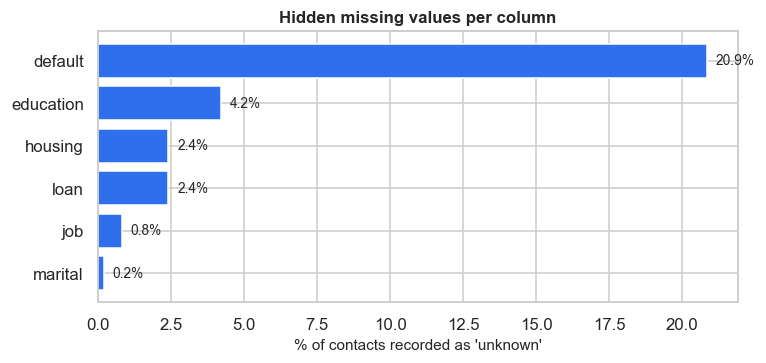

In [8]:
unk = ec.unknown_table(raw, CATEGORICAL_RAW)
unk_cols = unk[unk["unknown_rows"] > 0]
print("True NaN cells in the whole file:", int(raw.isna().sum().sum()))
display(unk_cols)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(unk_cols.index[::-1], unk_cols["unknown_pct"][::-1], color=C_MAIN)
for i, v in enumerate(unk_cols["unknown_pct"][::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of contacts recorded as 'unknown'"); ax.set_title("Hidden missing values per column")
save_fig("eda_unknown_share")

### 3.4 Is `unknown` just noise, or does it carry information?
**Question.** If clients with an `unknown` answer subscribe at a *different* rate from clients with a known answer, then deleting those rows or guessing the most common value (imputing the mode) would throw away signal. If the rates are the same, `unknown` is harmless noise. We compare the two groups for every column that has `unknown`, with a chi-square test (a p-value below 0.01 is treated as a real difference).

In [9]:
rows = []
for c in unk_cols.index:
    is_unk = eda[c] == "unknown"
    ct = pd.crosstab(is_unk, eda["y_bin"])
    p = stats.chi2_contingency(ct, correction=False)[1] if ct.shape == (2, 2) else np.nan
    rows.append(dict(column=c, contacts_unknown=int(is_unk.sum()),
                     rate_unknown_pct=100 * eda.loc[is_unk, "y_bin"].mean(), rate_known_pct=100 * eda.loc[~is_unk, "y_bin"].mean(),
                     p_value=p))
unk_info = pd.DataFrame(rows).set_index("column")
unk_info["difference_pp"] = unk_info["rate_unknown_pct"] - unk_info["rate_known_pct"]
unk_info["verdict"] = np.where(unk_info["p_value"] < 0.01, "differs: keep as its own category", "no clear difference")
display(unk_info.round(4))
for c, r in unk_info.iterrows():
    direction = "lower" if r["difference_pp"] < 0 else "higher"
    print(f"{c:<10}: 'unknown' clients subscribe {abs(r['difference_pp']):.1f} points {direction} than clients with a recorded answer ({r['verdict']}).")

,contacts_unknown,rate_unknown_pct,rate_known_pct,p_value,difference_pp,verdict
column,,,,,,
default,8597,5.153,12.878,0.000,-7.725,differs: keep as its own category
education,1731,14.500,11.123,0.000,3.377,differs: keep as its own category
housing,990,10.808,11.277,0.645,-0.469,no clear difference
loan,990,10.808,11.277,0.645,-0.469,no clear difference
job,330,11.212,11.266,0.976,-0.054,no clear difference
marital,80,15.000,11.258,0.290,3.742,no clear difference


default   : 'unknown' clients subscribe 7.7 points lower than clients with a recorded answer (differs: keep as its own category).
education : 'unknown' clients subscribe 3.4 points higher than clients with a recorded answer (differs: keep as its own category).
housing   : 'unknown' clients subscribe 0.5 points lower than clients with a recorded answer (no clear difference).
loan      : 'unknown' clients subscribe 0.5 points lower than clients with a recorded answer (no clear difference).
job       : 'unknown' clients subscribe 0.1 points lower than clients with a recorded answer (no clear difference).
marital   : 'unknown' clients subscribe 3.7 points higher than clients with a recorded answer (no clear difference).


### 3.5 Do the `unknown` answers occur together?
**Question.** If `unknown` marks the *same rows* in several columns, those rows are probably incomplete client records (a data-collection issue) rather than independent gaps, and imputing each column separately would be wrong.

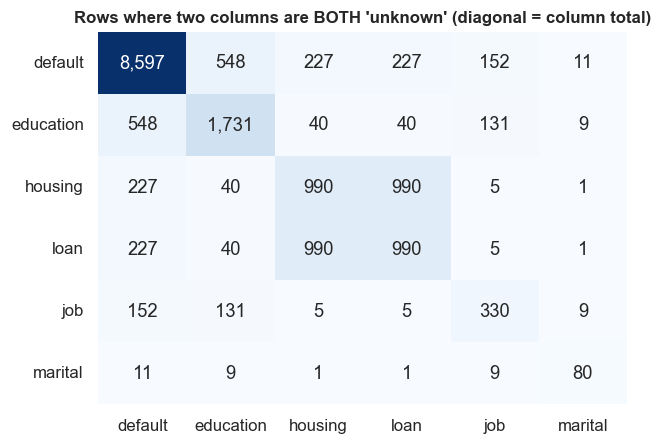

housing and loan are both 'unknown' in 990 rows = 100% of the housing 'unknown' rows.


In [10]:
unk_ind = pd.DataFrame({c: (eda[c] == "unknown").astype(int) for c in unk_cols.index})
co = unk_ind.T.dot(unk_ind)
plt.figure(figsize=(6.2, 4.4))
sns.heatmap(co, annot=True, fmt=",d", cmap="Blues", cbar=False)
plt.title("Rows where two columns are BOTH 'unknown' (diagonal = column total)")
save_fig("eda_unknown_cooccurrence")
if {"housing", "loan"} <= set(unk_ind.columns):
    both = int(((unk_ind["housing"] == 1) & (unk_ind["loan"] == 1)).sum())
    print(f"housing and loan are both 'unknown' in {both:,} rows = {100 * both / max(unk_ind['housing'].sum(), 1):.0f}% of the housing 'unknown' rows.")

**Reading and decision.** The sharing pattern tells us whether to treat gaps as one problem or several. The treatment is the same either way: **`unknown` is kept as its own category** (it is a real, observable state of the client record and may be informative), nothing is imputed with the mode, and no rows are dropped. The one exception is `education`, which is turned into an ordered number (illiterate < basic < high school < professional < university); there `unknown` cannot be placed on the scale, so it becomes a true missing value that is median-imputed *inside the pipeline* together with a missing-indicator column, so the model can still tell "unknown" apart.

`default = unknown` is by far the largest gap. Only a handful of clients are recorded as `default = yes`, so for the bank this column behaves more like "credit status verified / not verified" than a default flag.

### 3.6 The placeholder `pdays = 999`
**Question.** `pdays` is "days since the previous campaign contact". Which value means "never contacted before", and does the rest of the history agree?

In [11]:
hist = ec.history_consistency(eda)
display(hist)
contacted = eda[eda["pdays"] != 999]
print(f"pdays == 999 in {100 * (eda['pdays'] == 999).mean():.2f}% of rows. Among the {len(contacted):,} previously contacted clients pdays runs from "
      f"{contacted['pdays'].min()} to {contacted['pdays'].max()} days (median {contacted['pdays'].median():.0f}).")
print("Mean of pdays if 999 is wrongly treated as a number:", round(eda["pdays"].mean(), 1), "days  vs. the real median among contacted clients:", contacted["pdays"].median())

,rows
pdays == 999,39673
previous == 0,35563
poutcome == nonexistent,35563
all three agree,37078
pdays != 999 but previous == 0,0
pdays == 999 but previous > 0,4110


pdays == 999 in 96.32% of rows. Among the 1,515 previously contacted clients pdays runs from 0 to 27 days (median 6).
Mean of pdays if 999 is wrongly treated as a number: 962.5 days  vs. the real median among contacted clients: 6.0


**Reading and decision.** The three history columns describe one fact (was the client contacted in an earlier campaign?) and they agree row by row. `999` is a **code, not a number of days**; fed to a model as a number it would say "a never-contacted client was last contacted 999 days ago", which distorts distances and linear coefficients. **Decision:** add the flag `was_contacted_before` and replace the placeholder by 0 (the flag carries the information).

### 3.7 Ranges and outliers
**Question.** Are there impossible values, and are long right tails going to dominate a linear model or a neural network?

,min,median,p99,max,skew,outliers_iqr,outliers_pct
column,,,,,,,
age,17,38.000,71.000,98,0.780,469,1.140
campaign,1,2.000,14.000,56,4.760,2406,5.840
previous,0,0.000,2.000,7,3.830,5625,13.660
duration,0,180.000,"1,271.130",4918,3.260,2963,7.190


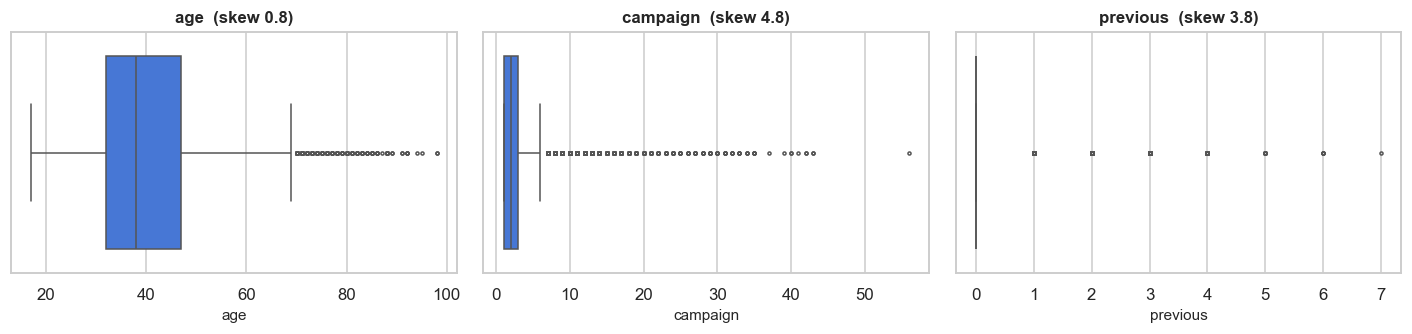

Clients with campaign >= 20 calls: 187 (max 56). Clients under 18: 5.


In [12]:
outl = ec.iqr_outlier_table(eda, ["age", "campaign", "previous", "duration"])
display(outl)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in zip(ax, ["age", "campaign", "previous"]):
    sns.boxplot(x=eda[c], ax=a, color=C_MAIN, fliersize=2); a.set_title(f"{c}  (skew {eda[c].skew():.1f})")
plt.tight_layout(); save_fig("eda_outlier_boxplots")
print(f"Clients with campaign >= 20 calls: {(eda['campaign'] >= 20).sum()} (max {eda['campaign'].max()}). Clients under 18: {(eda['age'] < 18).sum()}.")

**Reading and decision.** `campaign` has a long right tail (a few clients were called dozens of times) and is strongly right-skewed. These are **real behaviour, not errors**, so rows are **not removed**. Tree models are insensitive to the tail; logistic regression and the neural network are not, so a `log(1 + campaign)` copy is added in preprocessing (compared before and after in notebook 02, section 4). `age` is plausible throughout. `previous` is mostly 0 and is kept as is.

### Data-quality verdict
The file is unusually clean (no empty cells, a handful of duplicates, plausible ranges). The real quality issues are *semantic*: hidden missing values (`unknown`), a numeric placeholder (`pdays = 999`) and one post-call column (`duration`). All are handled explicitly in notebook 02.

---
## 4 · The target: how rare is a subscription?

**Purpose.** The share of subscribers decides which metrics are honest. If 9 in 10 clients say no, a model that predicts "no" for everyone is 90% accurate and worth nothing to the bank.

     contacts  share_%
y                     
no      36548   88.730
yes      4640   11.270

Overall subscription rate : 11.27%
Accuracy of 'always say no': 88.73%   <- looks excellent, identifies zero subscribers
Calls the bank makes per subscription when dialling at random: about 8.9


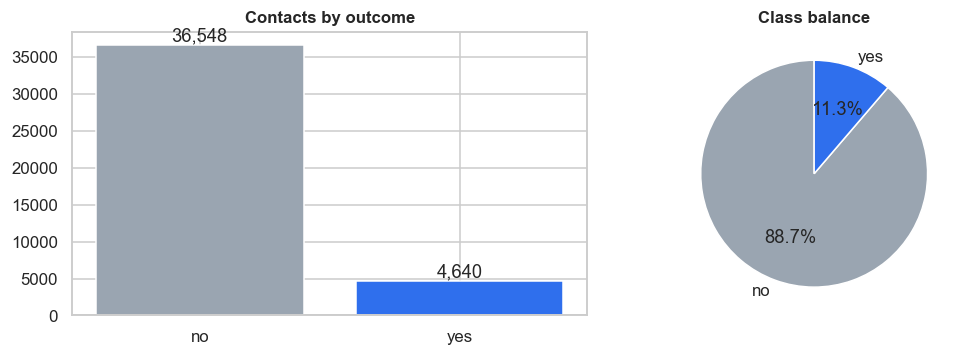

In [13]:
vc = eda["y"].value_counts()
rate = BASE
print(pd.DataFrame({"contacts": vc, "share_%": 100 * vc / vc.sum()}).round(2))
print(f"\nOverall subscription rate : {rate:.2%}")
print(f"Accuracy of 'always say no': {1 - rate:.2%}   <- looks excellent, identifies zero subscribers")
print(f"Calls the bank makes per subscription when dialling at random: about {1 / rate:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["no", "yes"], [vc["no"], vc["yes"]], color=[C_GREY, C_MAIN]); ax[0].set_title("Contacts by outcome")
for i, v in enumerate([vc["no"], vc["yes"]]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie([vc["no"], vc["yes"]], labels=["no", "yes"], colors=[C_GREY, C_MAIN], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class balance")
plt.tight_layout(); save_fig("eda_class_balance")

**Reading.** About one contact in nine ends in a subscription (11.27% in the official file), so a random call centre needs roughly **nine calls per sale**. This is exactly the waste the bank wants to reduce.

**Decisions for the rest of the project**
* **Accuracy is not reported as a success measure** (it is shown once, for the dummy model, to demonstrate why).
* Models are compared with **PR-AUC** (focuses on the rare class), **ROC-AUC**, and **budget metrics**: precision, recall and lift among the top `CALL_BUDGET` share of clients, which is what a call centre with limited capacity actually experiences.
* Imbalance handling (class weights, SMOTE, SMOTE-Tomek) is **tested, not assumed**, in notebook 04, always *inside* the training folds.

---
## 5 · Distributions: what does a typical contact look like?

**Purpose.** Before comparing subscribers with non-subscribers we need to know what the overall population looks like (who the bank phones, how often, through which channel), because a pattern among a tiny group cannot guide a whole campaign.

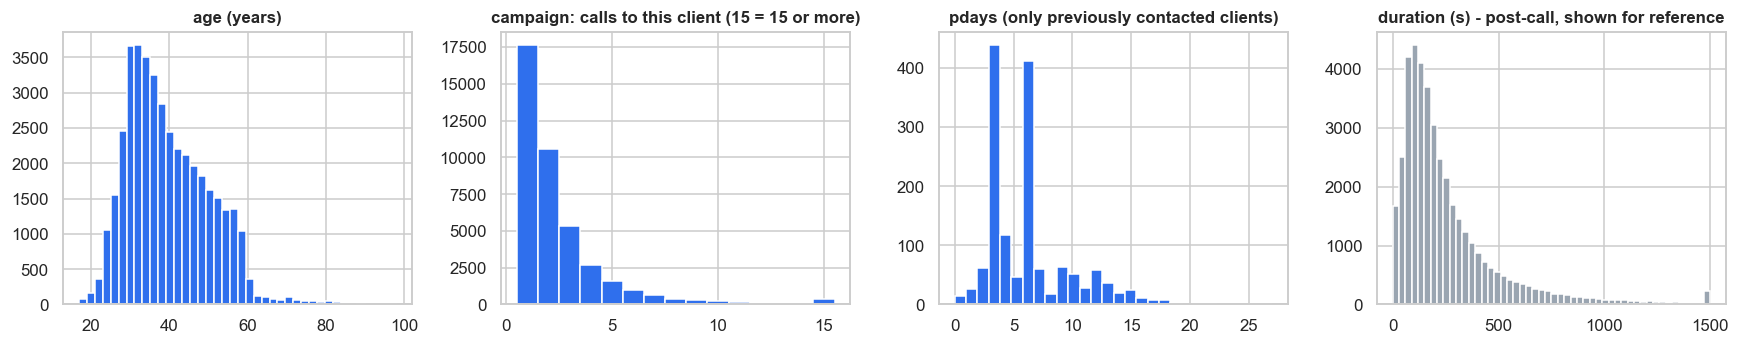

          age  campaign  previous  duration
mean   40.020     2.570     0.170   258.290
median 38.000     2.000     0.000   180.000
skew    0.780     4.760     3.830     3.260


In [14]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
ax[0].hist(eda["age"], bins=40, color=C_MAIN); ax[0].set_title("age (years)")
ax[1].hist(eda["campaign"].clip(upper=15), bins=range(1, 17), color=C_MAIN, align="left"); ax[1].set_title("campaign: calls to this client (15 = 15 or more)")
ax[2].hist(eda.loc[eda["pdays"] != 999, "pdays"], bins=28, color=C_MAIN); ax[2].set_title("pdays (only previously contacted clients)")
ax[3].hist(eda["duration"].clip(upper=1500), bins=50, color=C_GREY); ax[3].set_title("duration (s) - post-call, shown for reference")
plt.tight_layout(); save_fig("eda_numeric_distributions")
print(eda[["age", "campaign", "previous", "duration"]].agg(["mean", "median", "skew"]).round(2))

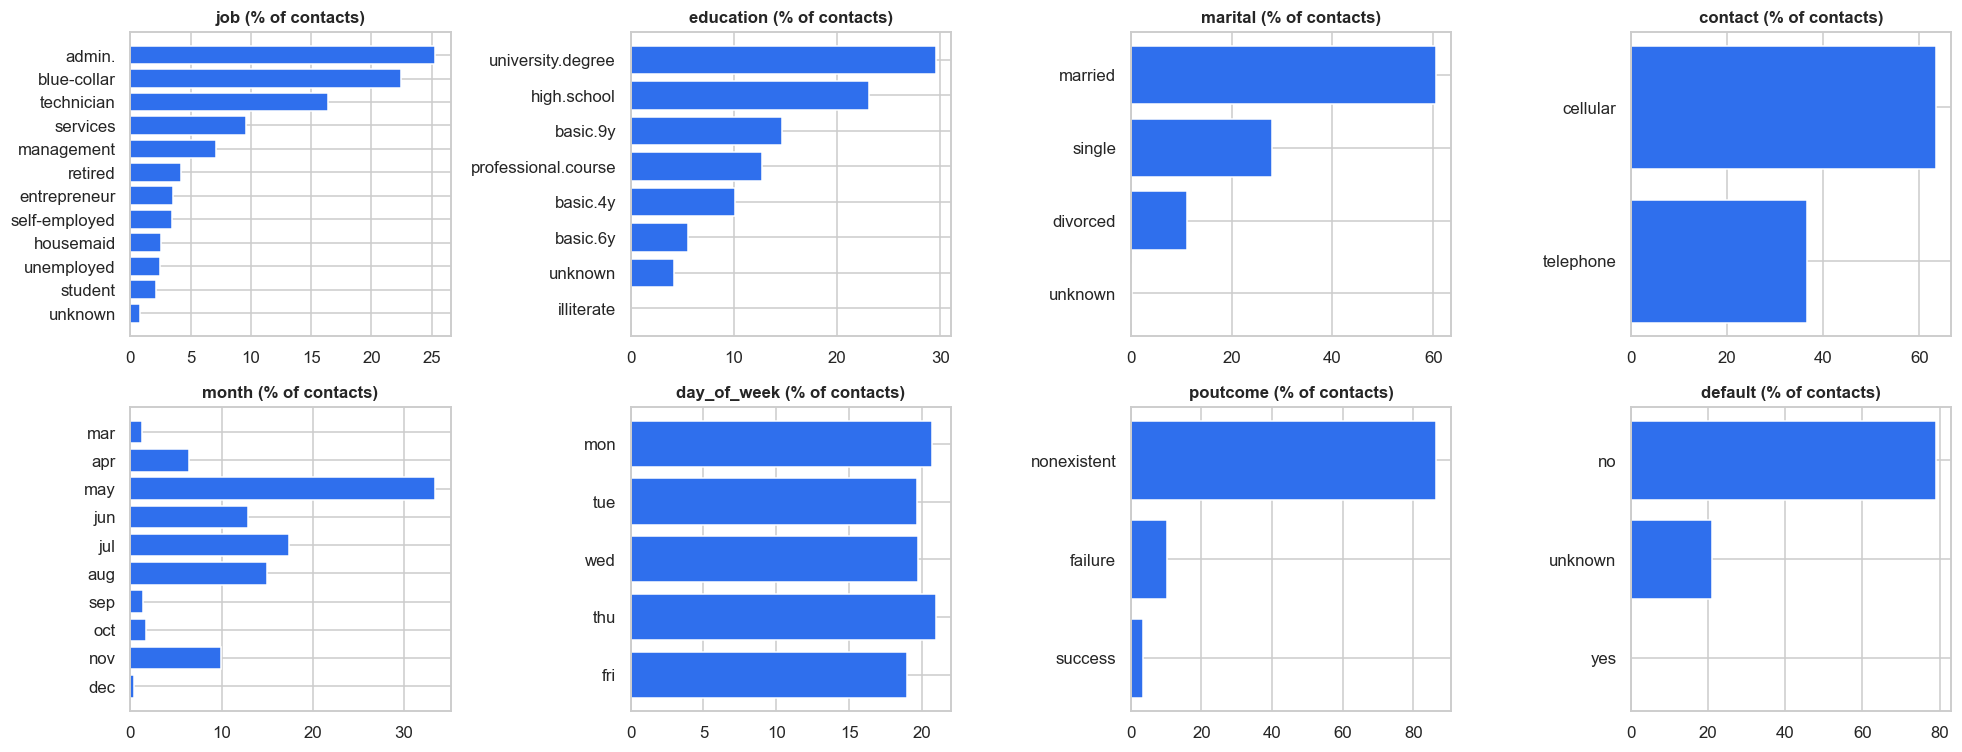

In [15]:
month_present = [m for m in MONTH_ORDER if m in set(eda["month"])]
panels = [("job", None), ("education", None), ("marital", None), ("contact", None),
          ("month", month_present), ("day_of_week", ["mon", "tue", "wed", "thu", "fri"]), ("poutcome", None), ("default", None)]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, (c, order) in zip(ax.ravel(), panels):
    vc = eda[c].value_counts(normalize=True) * 100
    vc = vc.reindex(order) if order else vc
    a.barh(vc.index[::-1].astype(str), vc.values[::-1], color=C_MAIN); a.set_title(f"{c} (% of contacts)")
plt.tight_layout(); save_fig("eda_categorical_distributions")

**Reading.** The population is dominated by a few job types, married clients with a university or high-school education, and contact by mobile phone. Three things deserve attention:

1. **`month` is very uneven.** A few summer months carry most of the calls, while other months (March, September, October, December) have very few. Rates computed on small months are noisy; the volume is shown beside every rate from here on.
2. **Almost all clients have never been contacted before** (`poutcome = nonexistent`), so the previous-campaign signal can only matter for a small group.
3. **`campaign` and `duration` are right-skewed**; `age` is roughly bell-shaped with a tail of older clients.

---
## 6 · Who subscribes? Rates by client, campaign and history attributes

**Purpose.** This is the core of the business question. For every attribute we compare the subscription rate of each group with the overall rate (red dashed line). Each bar carries a **95% confidence interval** and the **number of contacts** behind it: a tall bar on 30 contacts is not a finding.

### 6.1 Client attributes

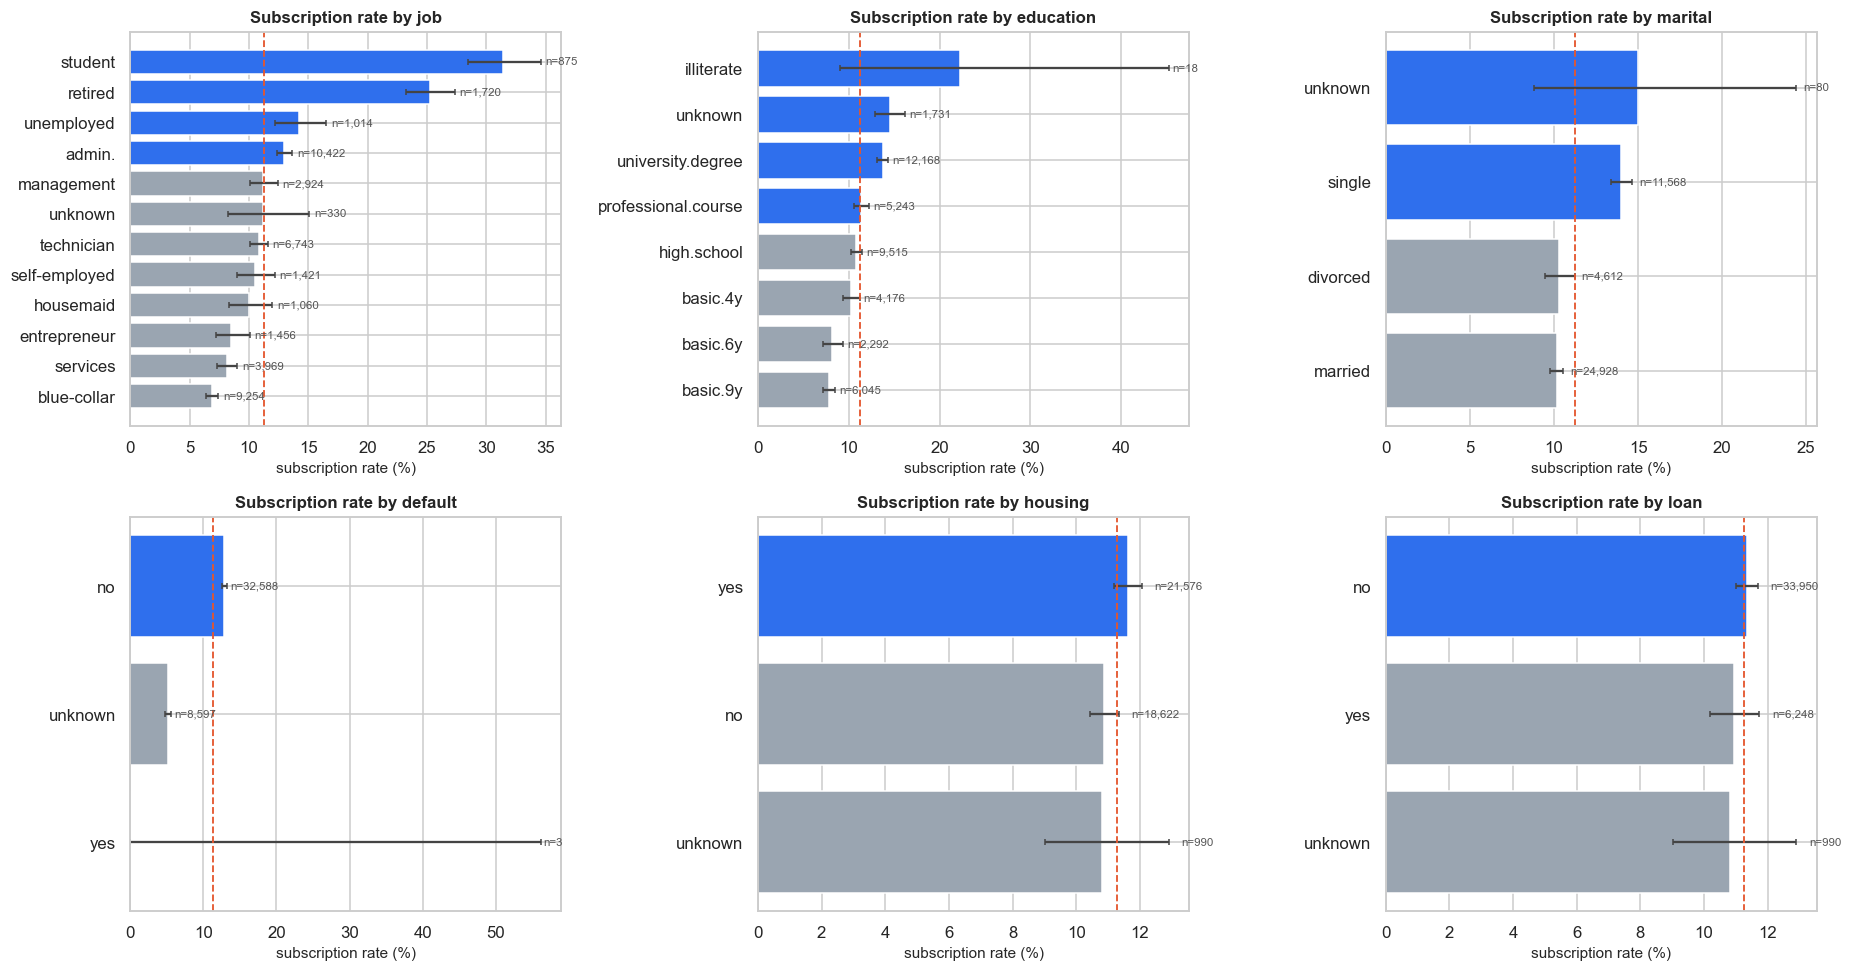

In [16]:
client_cats = ["job", "education", "marital", "default", "housing", "loan"]
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
rate_tabs = {}
for a, c in zip(ax.ravel(), client_cats):
    t = ec.rate_table(eda, c)
    rate_tabs[c] = t
    rate_bars(a, t, f"Subscription rate by {c}", BASE)
plt.tight_layout(); save_fig("eda_rate_client")

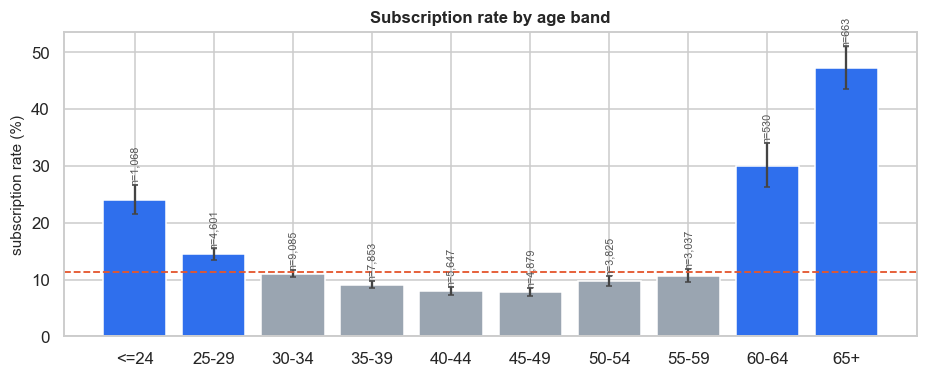

,contacts,rate_%,ci_low_%,ci_high_%,lift_vs_overall
age_band,,,,,
<=24,1068,23.970,21.510,26.620,2.130
25-29,4601,14.480,13.490,15.520,1.280
30-34,9085,11.010,10.380,11.670,0.980
35-39,7853,9.100,8.490,9.760,0.810
40-44,5647,8.020,7.340,8.760,0.710
45-49,4879,7.810,7.090,8.600,0.690
50-54,3825,9.730,8.830,10.710,0.860
55-59,3037,10.700,9.650,11.850,0.950
60-64,530,30.000,26.250,34.030,2.660


In [17]:
age_bins = [16, 24, 29, 34, 39, 44, 49, 54, 59, 64, 100]
age_labels = ["<=24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65+"]
eda["age_band"] = pd.cut(eda["age"], age_bins, labels=age_labels)
t_age = ec.rate_table(eda, "age_band", order=age_labels)
fig, ax = plt.subplots(figsize=(10, 3.6))
rate_bars(ax, t_age, "Subscription rate by age band", BASE, horizontal=False)
save_fig("eda_rate_age")
display(t_age[["contacts", "rate_%", "ci_low_%", "ci_high_%", "lift_vs_overall"]])

**Reading.** Rates differ clearly between job groups: **students and retired clients subscribe far more often than blue-collar or services clients** (in the official file roughly 31% and 25% against about 7-8%). Age shows the same story in another form: the youngest and the oldest bands subscribe most, the middle of the working-age range least (a U-shape), which is why age is kept as a number rather than reduced to a linear trend. Education, marital status and loans show weaker, smaller differences. **`default = unknown`** separates from `no`, matching the finding in 3.4.

*Caution for later.* Job, age and marital status describe protected or sensitive characteristics. A model may legitimately use them to rank clients, but a bank must check that it does not systematically deprioritise a group; this is audited in notebook 07.

### 6.2 Campaign attributes

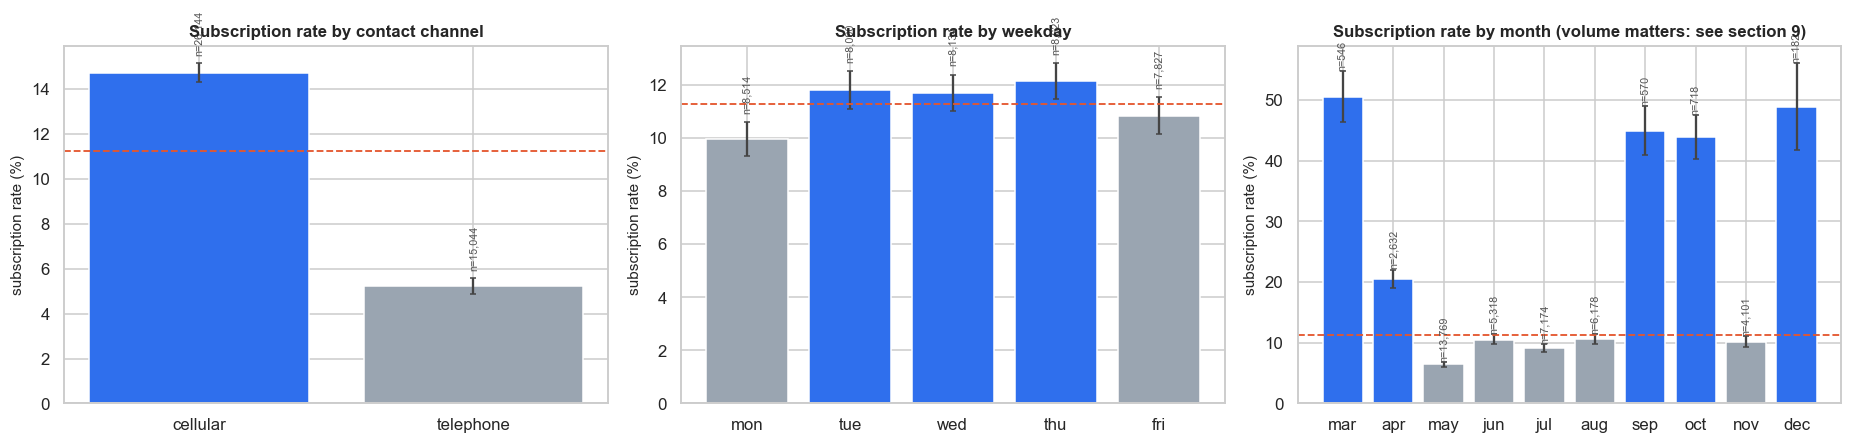

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
rate_bars(ax[0], ec.rate_table(eda, "contact"), "Subscription rate by contact channel", BASE, horizontal=False)
rate_bars(ax[1], ec.rate_table(eda, "day_of_week", order=["mon", "tue", "wed", "thu", "fri"]), "Subscription rate by weekday", BASE, horizontal=False)
rate_bars(ax[2], ec.rate_table(eda, "month", order=month_present), "Subscription rate by month (volume matters: see section 9)", BASE, horizontal=False)
plt.tight_layout(); save_fig("eda_rate_campaign")

**Reading.** The **channel** matters (mobile contact converts more often than the fixed telephone). The **weekday** barely matters. **Month looks like the strongest pattern of all**, but this is misleading: the months with the highest rates (March, September, October, December) are also the months with the *fewest calls*, and, as section 9 shows, they fall in different years with very different economic conditions. Month is therefore partly a **calendar proxy** and needs the time analysis before it can be interpreted.

### 6.3 Which attributes carry the most signal?
**Question.** A ranking on one scale helps decide where feature work should go. Categorical columns are scored by Cramér's V (0 = unrelated, 1 = perfectly related); numeric columns by a rank-based effect size; **mutual information** puts both on one comparable scale. `duration` is flagged in red: it will rank near the top because it is part of the outcome, not because it is useful.

,kind,effect_name,effect_size,p_value,mutual_info,flag
column,,,,,,
duration,numeric,|2*AUC-1|,0.637,0.000,0.072,post-call: leakage
nr.employed,numeric,|2*AUC-1|,0.498,0.000,0.062,
euribor3m,numeric,|2*AUC-1|,0.487,0.000,0.055,
previous,numeric,|2*AUC-1|,0.219,0.000,0.043,
pdays,numeric,|2*AUC-1|,0.194,0.000,0.042,
emp.var.rate,numeric,|2*AUC-1|,0.433,0.000,0.041,
poutcome,categorical,Cramer's V,0.320,0.000,0.030,
cons.conf.idx,numeric,|2*AUC-1|,0.075,0.000,0.027,
month,categorical,Cramer's V,0.274,0.000,0.026,


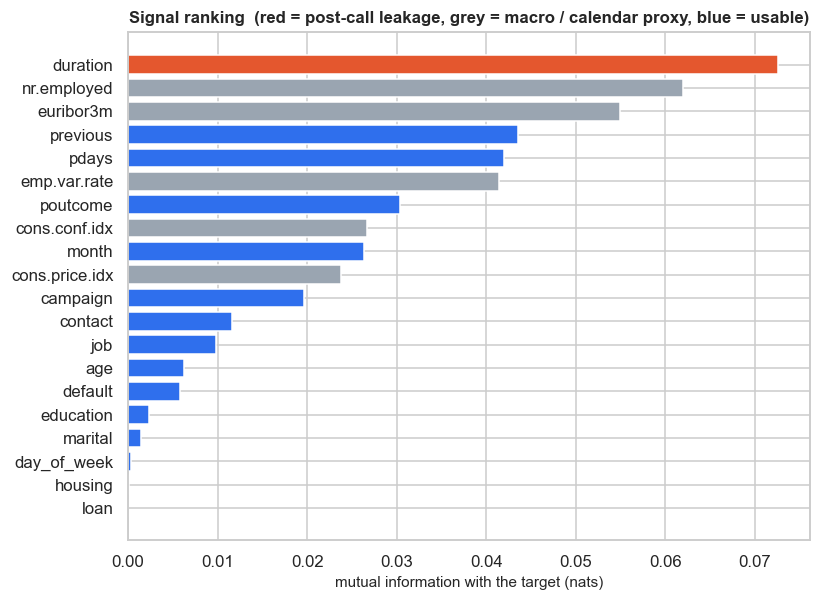

Strongest USABLE pre-call attributes: previous, pdays, poutcome, month, campaign


In [19]:
sig = ec.signal_table(eda, CATEGORICAL_RAW, NUMERIC_RAW)
sig.to_csv(TABLES_DIR / "eda_signal_ranking.csv")
display(sig[["kind", "effect_name", "effect_size", "p_value", "mutual_info", "flag"]].round(4))

fig, ax = plt.subplots(figsize=(8, 6))
s = sig["mutual_info"].sort_values()
cols = [C_WARN if c in LEAKY else (C_GREY if c in MACRO_COLS else C_MAIN) for c in s.index]
ax.barh(s.index, s.values, color=cols); ax.set_xlabel("mutual information with the target (nats)")
ax.set_title("Signal ranking  (red = post-call leakage, grey = macro / calendar proxy, blue = usable)")
save_fig("eda_signal_ranking")
usable = sig[(sig["flag"] == "") & (~sig.index.isin(MACRO_COLS))]
print("Strongest USABLE pre-call attributes:", ", ".join(usable.index[:5]))

**Reading.** Once `duration` (leakage) and the macro/calendar columns are set aside, the strongest attributes are the **previous-campaign outcome and history** (`poutcome`, `pdays`, `previous`), the **contact channel and month**, and then **job / education**. `age` scores close to zero here only because its effect is U-shaped (high for the youngest and oldest, low in between), which a monotone score cannot see: the age-band table in 6.1 shows it clearly matters. `housing` and `loan` are weak, and `default` matters mainly through its `unknown` level. This ranking is *univariate*: it says which single columns are informative, not which combination a model will use, and it makes no causal claim.

---
## 7 · Previous-campaign history

**Purpose.** A client who bought in an earlier campaign is the most natural person to call again. The question is how many such clients exist and how much of the campaign's success they explain.

,contacts,share_of_contacts_%,subscribers,rate_%,lift_vs_overall
poutcome,,,,,
success,1373,3.330,894,65.110,5.780
failure,4252,10.320,605,14.230,1.260
nonexistent,35563,86.340,3141,8.830,0.780


Clients who subscribed in an earlier campaign: 1,373 = 3.3% of all contacts, yet 19.3% of all subscribers; their rate is 65% vs 11.3% overall.


,contacts,rate_%,ci_low_%,ci_high_%
recency,,,,
0-3,541,65.250,61.140,69.140
4-6,576,66.150,62.190,69.890
7-10,194,60.310,53.290,66.930
11-15,166,57.830,50.230,65.080
16+,38,52.630,37.260,67.520


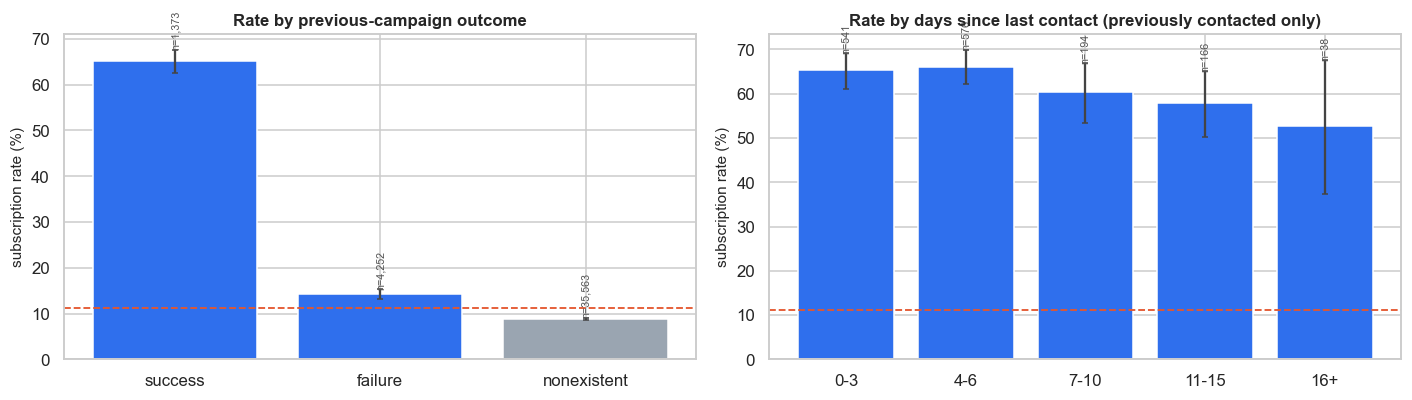

In [20]:
t_pout = ec.rate_table(eda, "poutcome")
display(t_pout[["contacts", "share_of_contacts_%", "subscribers", "rate_%", "lift_vs_overall"]])

succ = eda[eda["poutcome"] == "success"]
print(f"Clients who subscribed in an earlier campaign: {len(succ):,} = {100 * len(succ) / len(eda):.1f}% of all contacts, "
      f"yet {100 * succ['y_bin'].sum() / eda['y_bin'].sum():.1f}% of all subscribers; their rate is {100 * succ['y_bin'].mean():.0f}% vs {100 * BASE:.1f}% overall.")

contacted = eda[eda["pdays"] != 999].copy()
contacted["recency"] = pd.cut(contacted["pdays"], [-1, 3, 6, 10, 15, 100], labels=["0-3", "4-6", "7-10", "11-15", "16+"])
t_rec = ec.rate_table(contacted, "recency", order=["0-3", "4-6", "7-10", "11-15", "16+"])
display(t_rec[["contacts", "rate_%", "ci_low_%", "ci_high_%"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
rate_bars(ax[0], t_pout, "Rate by previous-campaign outcome", BASE, horizontal=False)
rate_bars(ax[1], t_rec, "Rate by days since last contact (previously contacted only)", BASE, horizontal=False)
plt.tight_layout(); save_fig("eda_history")

**Reading.** A previous **success** is by far the strongest single predictor available before the call: this small group (a few per cent of contacts) subscribes at several times the average rate and supplies a disproportionate share of all subscribers. Previous *failures* still subscribe somewhat above never-contacted clients (about 14% against 9%), but far below previous successes (about 65%). How *recently* a client was contacted shows a weaker, noisier pattern because each recency bucket holds few contacts.

**Decision.** Keep `poutcome`, `previous`, `pdays`; add `was_contacted_before`. The proposal's extra families (a "recent vs late" `pdays` split and a "previous success" flag) are tested, not assumed, in notebook 02 (section 6).

---
## 8 · Contact pressure: do repeated calls pay off?

**Purpose.** Calls cost money. If the tenth call to the same client almost never converts, the bank is spending effort on the wrong clients. `campaign` is the number of calls to a client during this campaign (so a client with `campaign = 5` consumed five calls).

,clients,calls,subscribers,rate_%,subscribers_per_100_calls,share_of_all_calls_%,share_of_subscribers_%
campaign,,,,,,,
1,17642,17642,2300,13.040,13.040,16.680,49.570
2,10570,21140,1211,11.460,5.730,19.990,26.100
3,5341,16023,574,10.750,3.580,15.150,12.370
4-5,4250,18599,369,8.680,1.980,17.590,7.950
6-9,2291,16024,147,6.420,0.920,15.150,3.170
10+,1094,16326,39,3.560,0.240,15.440,0.840


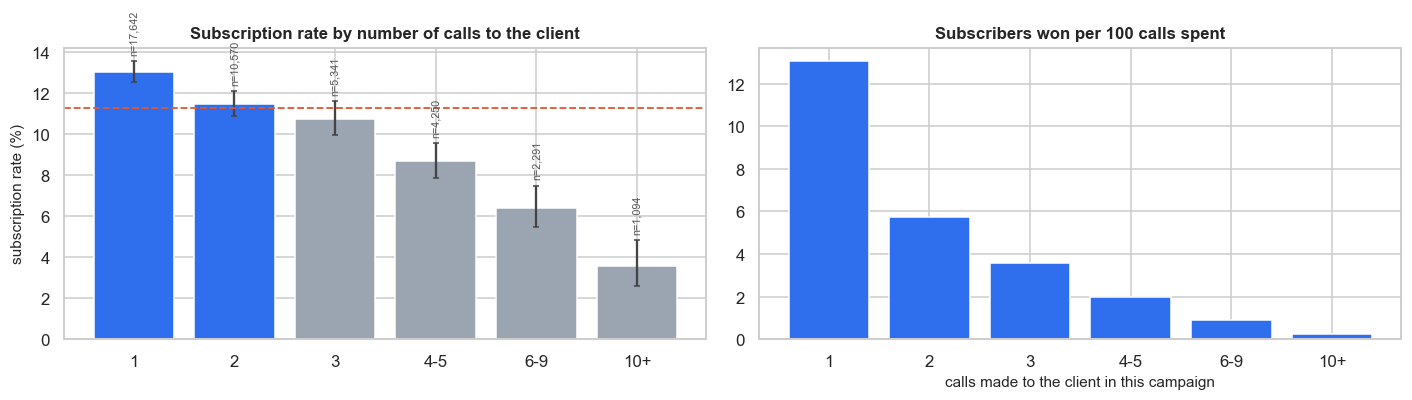

Clients called 6+ times absorb 30.6% of all calls but yield only 4.0% of subscribers.


In [21]:
bands = pd.cut(eda["campaign"], [0, 1, 2, 3, 5, 9, 100], labels=["1", "2", "3", "4-5", "6-9", "10+"])
g = eda.groupby(bands, observed=True).agg(clients=("y_bin", "size"), calls=("campaign", "sum"), subscribers=("y_bin", "sum"))
g["rate_%"] = 100 * g["subscribers"] / g["clients"]
g["subscribers_per_100_calls"] = 100 * g["subscribers"] / g["calls"]
g["share_of_all_calls_%"] = 100 * g["calls"] / g["calls"].sum()
g["share_of_subscribers_%"] = 100 * g["subscribers"] / g["subscribers"].sum()
display(g.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
t_c = ec.rate_table(eda.assign(cb=bands), "cb", order=list(g.index))
rate_bars(ax[0], t_c, "Subscription rate by number of calls to the client", BASE, horizontal=False)
ax[1].bar(g.index.astype(str), g["subscribers_per_100_calls"], color=C_MAIN); ax[1].set_title("Subscribers won per 100 calls spent")
ax[1].set_xlabel("calls made to the client in this campaign")
plt.tight_layout(); save_fig("eda_contact_pressure")
heavy = g.loc[g.index.isin(["6-9", "10+"])]
print(f"Clients called 6+ times absorb {heavy['share_of_all_calls_%'].sum():.1f}% of all calls but yield only {heavy['share_of_subscribers_%'].sum():.1f}% of subscribers.")

**Reading.** The success rate falls as the number of calls rises, and the *subscribers won per 100 calls* drops even faster: persistent calling is the least efficient use of call-centre time. This is a useful business message in its own right (a cap on repeat calls would free capacity), but it comes with a **causal caveat**: clients who say yes stop being called, so a high `campaign` count partly *records* a refusal rather than causing one. That is why `campaign` sits in the grey zone of section 2 and is stress-tested in notebook 02.

---
## 9 · Time structure and drift

**Purpose.** The calls span roughly two and a half years (May 2008 to November 2010), through a financial crisis. If the response behaviour changes over that period, a model that is trained and tested on randomly shuffled rows will look much better than it will in a real future campaign, and the bank would be misled about its value. This section is the evidence for the **validation design** of the whole project.

### 9.1 Recovering the calendar from the file
The file is sorted by contact date but has **no date column**: only the `month`. A new year starts whenever the month number falls back (for example December → March). We rebuild `year` and `period` this way and **check the result** against the documented range of the data.

In [22]:
per = ec.reconstruct_periods(eda)
eda = eda.join(per[["year", "period", "period_idx"]])
by_p = eda.groupby("period", sort=False).agg(contacts=("y_bin", "size"), subscribers=("y_bin", "sum"), euribor3m=("euribor3m", "mean"))
by_p["rate_%"] = 100 * by_p["subscribers"] / by_p["contacts"]
print(f"Reconstructed {by_p.shape[0]} month-periods: first = {by_p.index[0]}, last = {by_p.index[-1]} (documented range: 2008-05 to 2010-11)")
print("Rows per reconstructed year:", eda["year"].value_counts().sort_index().to_dict())
display(by_p.round(2).T)

Reconstructed 26 month-periods: first = 2008-05, last = 2010-11 (documented range: 2008-05 to 2010-11)
Rows per reconstructed year: {2008: 27690, 2009: 11440, 2010: 2058}


period,2008-05,2008-06,2008-07,2008-08,2008-10,2008-11,2008-12,2009-03,2009-04,2009-05,2009-06,2009-07,2009-08,2009-09,2009-10,2009-11,2009-12,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,2010-10,2010-11
contacts,"7,763.000","4,374.000","6,685.000","5,175.000",67.000,"3,616.000",10.000,282.000,"2,458.000","5,794.000",715.000,178.000,770.000,267.000,447.000,357.000,172.000,264.000,174.000,212.000,229.000,311.000,233.000,303.000,204.000,128.000
subscribers,240.000,188.000,407.000,271.000,42.000,190.000,1.000,126.000,442.000,524.000,264.000,66.000,264.000,106.000,180.000,168.000,88.000,150.000,97.000,122.000,107.000,176.000,120.000,150.000,93.000,58.000
euribor3m,4.860,4.930,4.960,4.960,4.920,4.110,3.490,1.650,1.410,1.290,1.260,1.030,0.870,0.780,0.740,0.720,0.710,0.650,0.650,0.690,0.730,0.850,0.900,0.880,1.000,1.040
rate_%,3.090,4.300,6.090,5.240,62.690,5.250,10.000,44.680,17.980,9.040,36.920,37.080,34.290,39.700,40.270,47.060,51.160,56.820,55.750,57.550,46.720,56.590,51.500,49.500,45.590,45.310


### 9.2 Volume, response rate and the economy over time

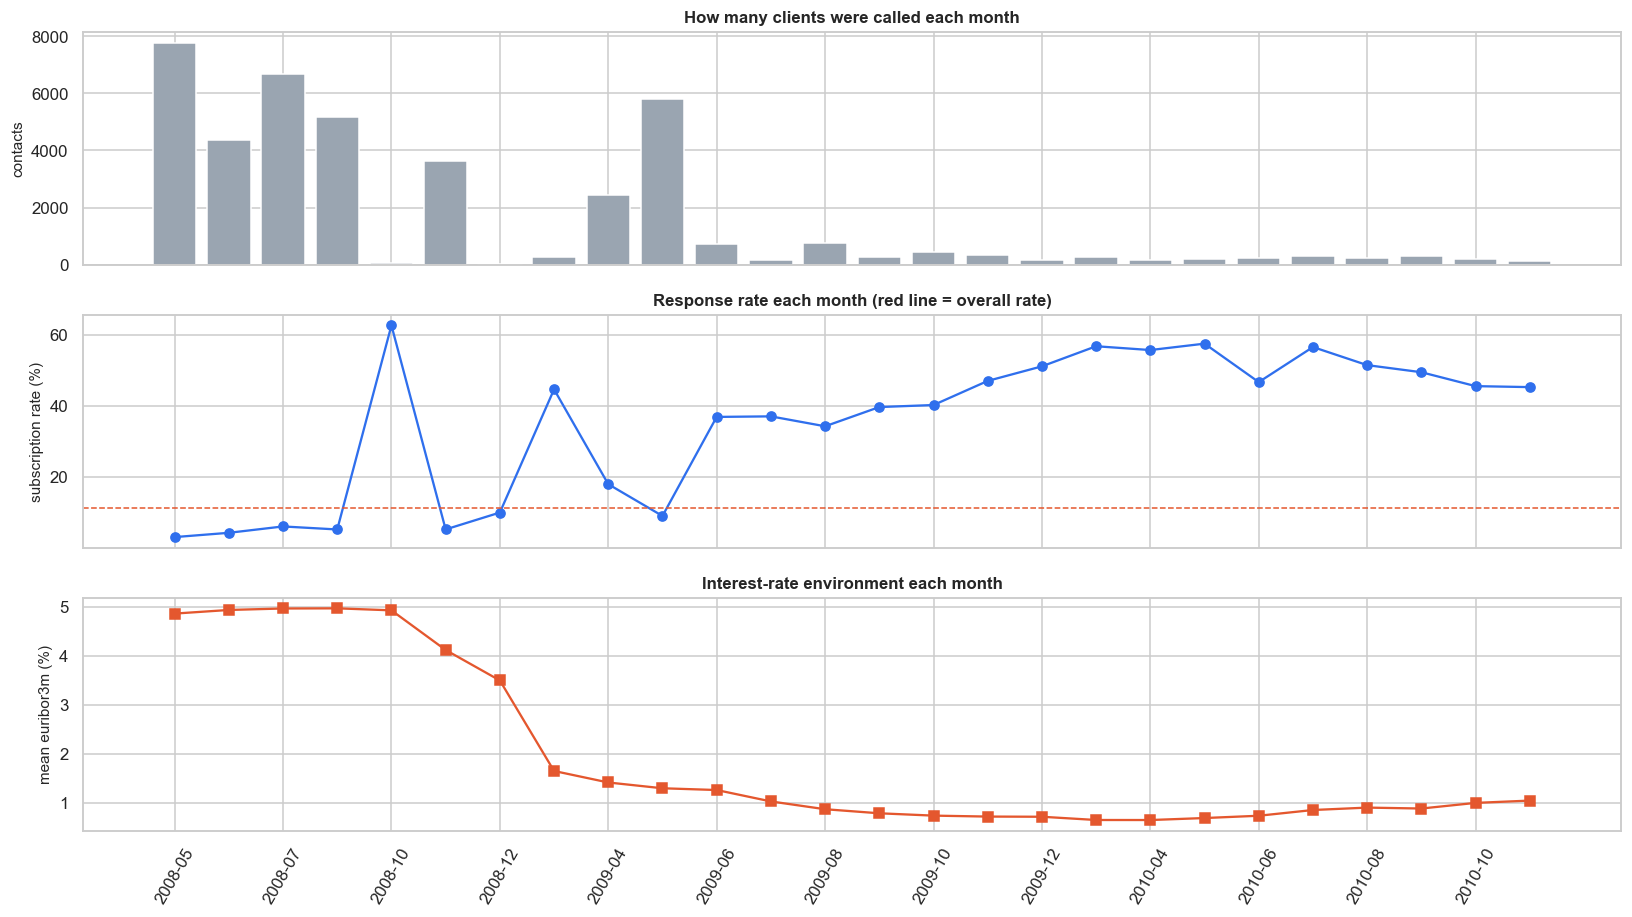

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(15, 8.5), sharex=True)
x = np.arange(len(by_p))
ax[0].bar(x, by_p["contacts"], color=C_GREY); ax[0].set_ylabel("contacts"); ax[0].set_title("How many clients were called each month")
ax[1].plot(x, by_p["rate_%"], marker="o", color=C_MAIN); ax[1].axhline(100 * BASE, color=C_WARN, ls="--", lw=1)
ax[1].set_ylabel("subscription rate (%)"); ax[1].set_title("Response rate each month (red line = overall rate)")
ax[2].plot(x, by_p["euribor3m"], marker="s", color=C_WARN); ax[2].set_ylabel("mean euribor3m (%)"); ax[2].set_title("Interest-rate environment each month")
ax[2].set_xticks(x[::2], by_p.index[::2], rotation=60)
plt.tight_layout(); save_fig("eda_time_drift")

### 9.3 Is `month` seasonality, or is it the year?
If a month's rate were seasonal, the same month would look similar in 2008, 2009 and 2010. The grid below shows the rate (top) and the number of contacts (bottom) for each month and year. Cells with fewer than 30 contacts are blanked: their rates are not reliable.

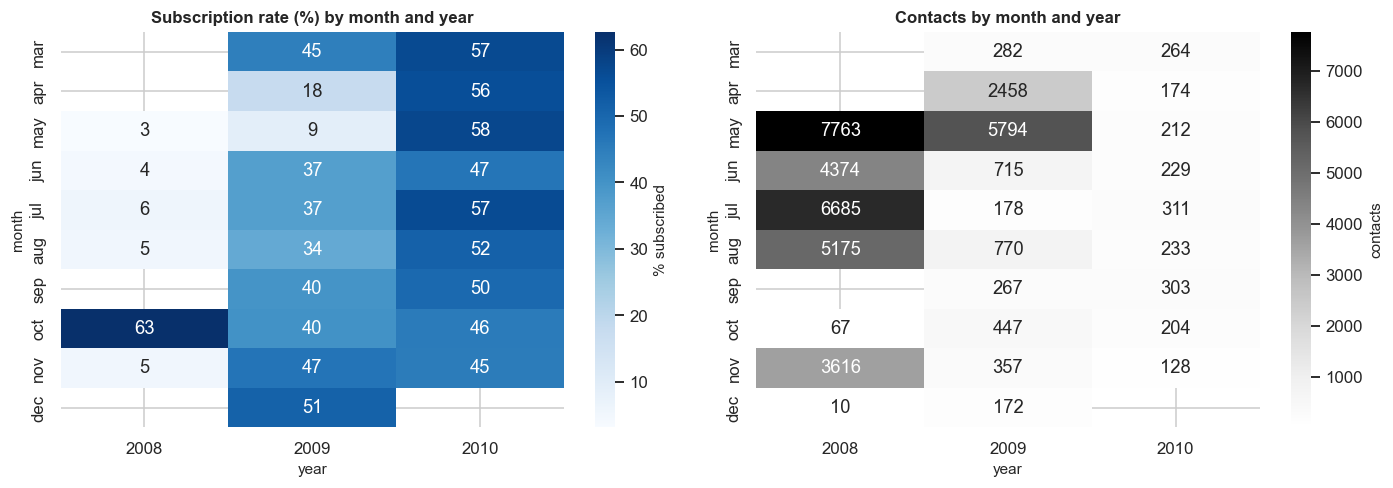

In [24]:
piv_rate = eda.pivot_table(index="month", columns="year", values="y_bin", aggfunc="mean").reindex(month_present) * 100
piv_n = eda.pivot_table(index="month", columns="year", values="y_bin", aggfunc="size").reindex(month_present)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(piv_rate.where(piv_n >= 30), annot=True, fmt=".0f", cmap="Blues", ax=ax[0], cbar_kws={"label": "% subscribed"})
ax[0].set_title("Subscription rate (%) by month and year")
sns.heatmap(piv_n, annot=True, fmt=".0f", cmap="Greys", ax=ax[1], cbar_kws={"label": "contacts"}); ax[1].set_title("Contacts by month and year")
plt.tight_layout(); save_fig("eda_month_year")

### 9.4 Did the *kind of client being called* change?
A rising response rate could mean clients became more willing, or that the bank started calling a different mix of clients. Both are drift; they call for different remedies.

In [25]:
comp = eda.groupby("year").agg(
    contacts=("y_bin", "size"), rate_pct=("y_bin", lambda s: 100 * s.mean()),
    mean_age=("age", "mean"),
    pct_cellular=("contact", lambda s: 100 * (s == "cellular").mean()),
    pct_previously_contacted=("pdays", lambda s: 100 * (s != 999).mean()),
    pct_retired_or_student=("job", lambda s: 100 * s.isin(["retired", "student"]).mean()),
    mean_calls_per_client=("campaign", "mean"),
    mean_euribor3m=("euribor3m", "mean"))
display(comp.round(2))

,contacts,rate_pct,mean_age,pct_cellular,pct_previously_contacted,pct_retired_or_student,mean_calls_per_client,mean_euribor3m
year,,,,,,,,
2008,27690,4.840,40.200,50.470,0.130,3.570,2.800,4.820
2009,11440,19.480,39.260,91.770,6.600,9.820,2.130,1.230
2010,2058,52.140,41.950,81.150,35.230,23.470,1.910,0.810


### 9.5 What this means for how we split and validate

,rows,subscribers,response_rate_%
part,,,
train,32940,2100,6.380
pilot,500,32,6.400
test,7736,2507,32.410


Response rate in each forward-chaining validation block (inside the training period): [4.4, 6.3, 5.5, 12.7] %
Overall rate 11.3%. A stratified random split would give every part about 11.3%, hiding all of this.


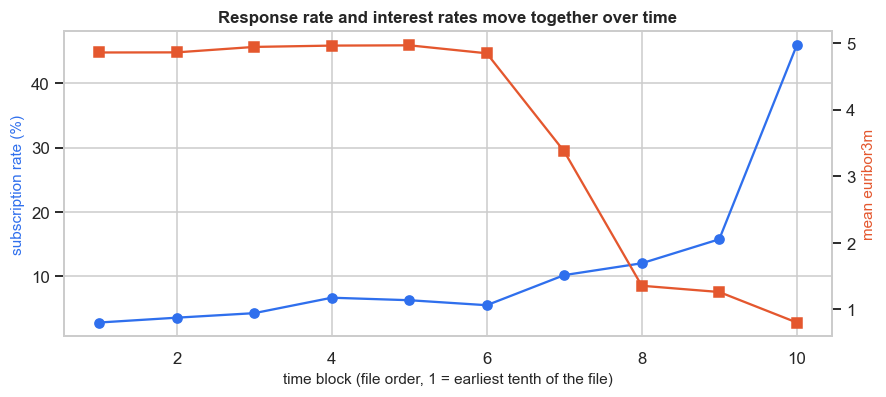

In [26]:
dedup = deduplicate(raw)
sp = chronological_split(dedup)
display(describe_split(sp).assign(response_rate=lambda d: (100 * d["response_rate"]).round(2)).rename(columns={"response_rate": "response_rate_%"}))

from sklearn.model_selection import TimeSeriesSplit
y_all = sp["y_all"][: sp["cut"]]
fc_rates = [round(100 * float(y_all[va].mean()), 1) for _, va in TimeSeriesSplit(n_splits=N_TS_SPLITS).split(y_all)]
print(f"Response rate in each forward-chaining validation block (inside the training period): {fc_rates} %")
print(f"Overall rate {100 * BASE:.1f}%. A stratified random split would give every part about {100 * BASE:.1f}%, hiding all of this.")

blocks = pd.qcut(np.arange(len(eda)), 10, labels=False) + 1
tb = eda.groupby(blocks).agg(rate=("y_bin", "mean"), euribor=("euribor3m", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tb.index, 100 * tb["rate"], marker="o", color=C_MAIN); ax.set_ylabel("subscription rate (%)", color=C_MAIN)
ax2 = ax.twinx(); ax2.plot(tb.index, tb["euribor"], marker="s", color=C_WARN); ax2.set_ylabel("mean euribor3m", color=C_WARN)
ax.set_xlabel("time block (file order, 1 = earliest tenth of the file)"); ax.set_title("Response rate and interest rates move together over time")
ax2.grid(False); save_fig("eda_time_blocks")

**Reading.** The response rate **does not stay level**: it is about 3-6% through 2008, rises from March 2009 once interest rates fall, and sits around 45-57% in 2010 (the held-out test period is about 32%, the training period about 6%). The mix of clients also shifts between years (9.4). Two consequences follow:

* The later part of the file is **a different world**. A chronological split (train on the past, test on the future) is the only honest simulation of a real campaign, and it will report a harder, lower, *more truthful* score than a random split. The size of that optimism is measured in notebook 05 (section 5).
* **Model selection inside the training period also uses forward-chaining folds**, not just shuffled folds, for the same reason (notebook 03).
* Because response rate differs so much between the training and the test period, **raw predicted probabilities will not match the later base rate**. The call policy therefore ranks clients and re-anchors the base rate with recent labelled calls (notebook 06).

---
## 10 · Correlation and redundancy

**Purpose.** Strongly overlapping columns carry the same information twice. For tree models that is harmless; for linear coefficients it makes them unstable; and if the overlap is *with the calendar* it is a warning that the column describes the period, not the client.

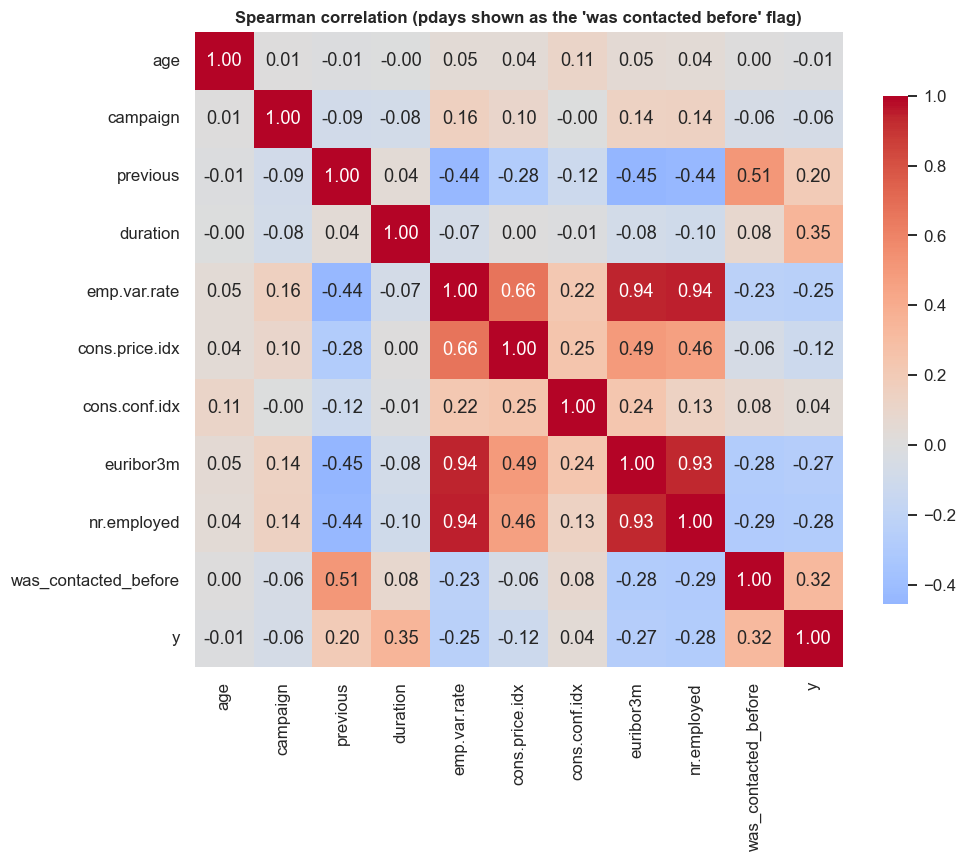

Macro-indicator pairs with |r| >= 0.9: 3 of 10  (highest 0.97)

Variance inflation factors (VIF > 10 = severe collinearity):


column,euribor3m,emp.var.rate,nr.employed,cons.price.idx,cons.conf.idx,previous,campaign,age
vif,64.300,33.100,31.600,6.300,2.600,1.300,1.000,1.000



Spearman correlation of each macro indicator with TIME (rank of the calendar period):


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
rho with time,-0.670,-0.760,-0.260,-0.630,-0.580


For comparison, usable client / history columns:


,age,campaign,previous
rho with time,-0.050,-0.110,0.460


In [27]:
num_view = eda[["age", "campaign", "previous", "duration"] + MACRO_COLS].copy()
num_view["was_contacted_before"] = (eda["pdays"] != 999).astype(int)
num_view["y"] = eda["y_bin"]
corr = num_view.corr(method="spearman")
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": .8})
plt.title("Spearman correlation (pdays shown as the 'was contacted before' flag)")
save_fig("eda_correlation")

macro_corr = pd.Series(eda[MACRO_COLS].corr().abs().values[np.triu_indices(5, 1)])
print(f"Macro-indicator pairs with |r| >= 0.9: {int((macro_corr >= 0.9).sum())} of {len(macro_corr)}  (highest {macro_corr.max():.2f})")
print("\nVariance inflation factors (VIF > 10 = severe collinearity):")
display(ec.vif_table(eda, MACRO_COLS + ["age", "campaign", "previous"]).T)
print("\nSpearman correlation of each macro indicator with TIME (rank of the calendar period):")
display(pd.Series({c: stats.spearmanr(eda[c], eda["period_idx"])[0] for c in MACRO_COLS}, name="rho with time").round(2).to_frame().T)
print("For comparison, usable client / history columns:")
display(pd.Series({c: stats.spearmanr(eda[c], eda["period_idx"])[0] for c in ["age", "campaign", "previous"]}, name="rho with time").round(2).to_frame().T)

**Reading.** Three of the five macro indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are almost the same variable (correlation about 0.9 or more, very high VIF), and they are all **strongly tied to the calendar**. They also correlate with the target in this period (the bank's response rose as rates fell), but a model that learns "low Euribor ⇒ subscribe" has learned *the 2010 economy*, not *which client is receptive*, and it would fail in a different year. Client and history columns, by contrast, hardly move with time.

**Decision (policy, tested later).** Macro indicators are **excluded by default** (`EXCLUDE_MACRO = True` in `src/config.py`), with the evidence demanded in notebook 03 (section 5: variants with and without macro features, scored on forward-chaining folds and the later hold-out) rather than a verdict from correlations alone. The rank correlation of `duration` with the outcome (about 0.35 in section 12) is by far the largest of any input and is *not* a virtue: see the leakage demonstration in notebook 02.

---
## 11 · Profile of a subscriber

**Purpose.** A campaign manager thinks in client types, not in p-values. This section restates the findings as one table (subscribers vs the rest) and then lists the single groups with the highest lift, restricted to groups large enough to be trusted.

In [28]:
def pct(mask): return 100 * mask.mean()
profile = pd.DataFrame({
    "subscribers": eda[eda["y_bin"] == 1].pipe(lambda d: pd.Series({
        "median age": d["age"].median(), "% retired or student": pct(d["job"].isin(["retired", "student"])),
        "% blue-collar or services": pct(d["job"].isin(["blue-collar", "services"])),
        "% university degree": pct(d["education"] == "university.degree"), "% with housing loan": pct(d["housing"] == "yes"),
        "% contacted by mobile": pct(d["contact"] == "cellular"), "% previously contacted": pct(d["pdays"] != 999),
        "% previous campaign success": pct(d["poutcome"] == "success"), "mean calls in this campaign": d["campaign"].mean()})),
    "non-subscribers": eda[eda["y_bin"] == 0].pipe(lambda d: pd.Series({
        "median age": d["age"].median(), "% retired or student": pct(d["job"].isin(["retired", "student"])),
        "% blue-collar or services": pct(d["job"].isin(["blue-collar", "services"])),
        "% university degree": pct(d["education"] == "university.degree"), "% with housing loan": pct(d["housing"] == "yes"),
        "% contacted by mobile": pct(d["contact"] == "cellular"), "% previously contacted": pct(d["pdays"] != 999),
        "% previous campaign success": pct(d["poutcome"] == "success"), "mean calls in this campaign": d["campaign"].mean()})),
})
profile["difference"] = profile["subscribers"] - profile["non-subscribers"]
display(profile.round(2))

rows = []
for c in ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome", "day_of_week"]:
    for lvl, r in ec.rate_table(eda, c, min_n=300).iterrows():
        rows.append(dict(group=f"{c} = {lvl}", contacts=int(r["contacts"]), rate_pct=r["rate_%"], lift=r["lift_vs_overall"]))
lifts = pd.DataFrame(rows).set_index("group").sort_values("lift", ascending=False)
print("Highest-lift single groups (at least 300 contacts):")
display(lifts.head(8).round(2))
print("Lowest-lift single groups:")
display(lifts.tail(5).round(2))

,subscribers,non-subscribers,difference
median age,37.000,38.000,-1.000
% retired or student,15.280,5.160,10.120
% blue-collar or services,20.710,33.550,-12.840
% university degree,35.990,28.720,7.270
% with housing loan,54.030,52.180,1.850
% contacted by mobile,83.040,60.990,22.050
% previously contacted,20.840,1.500,19.340
% previous campaign success,19.270,1.310,17.960
mean calls in this campaign,2.050,2.630,-0.580


Highest-lift single groups (at least 300 contacts):


,contacts,rate_pct,lift
group,,,
poutcome = success,1373,65.110,5.780
job = student,875,31.430,2.790
job = retired,1720,25.230,2.240
contact = cellular,26144,14.740,1.310
education = unknown,1731,14.500,1.290
poutcome = failure,4252,14.230,1.260
job = unemployed,1014,14.200,1.260
marital = single,11568,14.000,1.240


Lowest-lift single groups:


,contacts,rate_pct,lift
group,,,
job = services,3969,8.140,0.720
education = basic.9y,6045,7.820,0.690
job = blue-collar,9254,6.890,0.610
default = unknown,8597,5.150,0.460
contact = telephone,15044,5.230,0.460


**Reading.** The typical subscriber is **not** a different "kind of person" in every respect: they are more often retired or students, more often reached on a mobile phone, and far more often someone who subscribed before. Lift figures show where a single rule would already beat random calling (for instance "call previous-campaign successes first"), and also how limited any single-attribute rule is: it covers only a small share of subscribers. That is the argument for a model that combines attributes, which is what notebooks 03-04 build.

---
## 12 · EDA insight log

Every finding is recorded with the **evidence** (computed from the data just now, so it always matches the outputs above), the **consequence for the task**, and **where it is acted on**. This table is saved to `reports/tables/eda_insight_log.csv` and summarised in `docs/eda_insight_log.md`.

In [29]:
poutcome_s = ec.rate_table(eda, "poutcome").loc["success"] if "success" in set(eda["poutcome"]) else None
first_r, last_r = by_p["rate_%"].iloc[:3].mean(), by_p["rate_%"].iloc[-3:].mean()
insights = [
    ("E1", "Data quality", f"{int(raw.duplicated().sum())} exact duplicate rows and no empty cells in {len(raw):,} rows",
     "The file is clean apart from a few repeats; duplicates could leak across the split", "Drop duplicates, keep order (02 §3)"),
    ("E2", "Data quality", "Hidden missing values written as 'unknown': " + ", ".join(f"{c} {r.unknown_pct:.1f}%" for c, r in unk_cols.head(4).iterrows()),
     "Imputing would hide a real state of the client record; the label can be informative (3.4)", "Own category; education -> ordinal + missing indicator (02 §3)"),
    ("E3", "Data quality", f"pdays = 999 for {100 * (eda['pdays'] == 999).mean():.1f}% of rows; agrees with previous = 0 and poutcome = nonexistent",
     "999 is a code, not a number of days; a numeric 999 would distort distances and coefficients", "Flag was_contacted_before + replace by 0 (02 §3)"),
    ("E4", "Leakage", f"duration is the strongest column (Spearman with target {corr.loc['duration', 'y']:.2f}) but exists only after the call",
     "Would create an illusion of skill and cannot be used to build a call list", "Excluded from all deployable models; leakage demonstrated (02 §7)"),
    ("E5", "Target", f"Subscription rate {100 * BASE:.2f}%: about {1 / BASE:.1f} calls per subscription",
     "Accuracy is meaningless (always-no scores {:.1f}%)".format(100 * (1 - BASE)), "PR-AUC, ROC-AUC and budget metrics; imbalance tested (04)"),
    ("E6", "History", f"Previous-campaign successes: {100 * (eda['poutcome'] == 'success').mean():.1f}% of contacts, rate "
     f"{poutcome_s['rate_%'] if poutcome_s is not None else float('nan'):.0f}% (lift {poutcome_s['lift_vs_overall'] if poutcome_s is not None else float('nan'):.1f}x)",
     "Strongest pre-call predictor, but only for a small group", "Keep poutcome / previous / pdays; test extra pdays features (02 §6)"),
    ("E7", "Client", f"Highest-rate jobs: " + ", ".join(rate_tabs['job'].index[:2]) + "; lowest: " + ", ".join(rate_tabs['job'].index[-2:]),
     "Job and age separate clients (U-shape in age); sensitive attributes", "Keep job (one-hot) and age (numeric); fairness audit (07)"),
    ("E8", "Campaign", f"Clients called 6+ times use {heavy['share_of_all_calls_%'].sum():.0f}% of calls for {heavy['share_of_subscribers_%'].sum():.0f}% of subscribers",
     "Repeated calling is inefficient, but campaign partly records refusals (reverse causality)", "campaign kept + log copy; sensitivity test (02 §7)"),
    ("E9", "Campaign", "Month has the largest apparent effect; the high-rate months are the lowest-volume ones and belong to different years",
     "Month mixes seasonality with year / economy; rates on small months are noisy", "Keep month but validate chronologically (02 §5, 03)"),
    ("E10", "Drift", f"Response rate averages {first_r:.1f}% in the first three months of the file and {last_r:.1f}% in the last three",
     "The base rate and the client mix change over time; random splits would be over-optimistic", "Chronological train/pilot/test split; forward-chaining CV (02 §5, 03, 05)"),
    ("E11", "Macro", f"{int((macro_corr >= 0.9).sum())} macro pairs have |r| >= 0.9 and all five track the calendar (|rho with time| up to {max(abs(stats.spearmanr(eda[c], eda['period_idx'])[0]) for c in MACRO_COLS):.2f})",
     "Macro columns describe the period, not the client; collinear and time-proxy", "Excluded by default; tested with and without (03 §5)"),
    ("E12", "Skew", f"campaign skew {eda['campaign'].skew():.1f}, max {eda['campaign'].max()} calls; outliers are real behaviour",
     "A long tail hurts linear / neural models, not trees; removing rows would delete real clients", "Keep rows; add log1p(campaign) copy (02 §4)"),
]
insight_log = pd.DataFrame(insights, columns=["id", "theme", "evidence (computed)", "consequence for the task", "handled in"]).set_index("id")
insight_log.to_csv(TABLES_DIR / "eda_insight_log.csv")
with pd.option_context("display.max_colwidth", 200):
    display(insight_log)

,theme,evidence (computed),consequence for the task,handled in
id,,,,
E1,Data quality,"12 exact duplicate rows and no empty cells in 41,188 rows",The file is clean apart from a few repeats; duplicates could leak across the split,"Drop duplicates, keep order (02 §3)"
E2,Data quality,"Hidden missing values written as 'unknown': default 20.9%, education 4.2%, housing 2.4%, loan 2.4%",Imputing would hide a real state of the client record; the label can be informative (3.4),Own category; education -> ordinal + missing indicator (02 §3)
E3,Data quality,pdays = 999 for 96.3% of rows; agrees with previous = 0 and poutcome = nonexistent,"999 is a code, not a number of days; a numeric 999 would distort distances and coefficients",Flag was_contacted_before + replace by 0 (02 §3)
E4,Leakage,duration is the strongest column (Spearman with target 0.35) but exists only after the call,Would create an illusion of skill and cannot be used to build a call list,Excluded from all deployable models; leakage demonstrated (02 §7)
E5,Target,Subscription rate 11.27%: about 8.9 calls per subscription,Accuracy is meaningless (always-no scores 88.7%),"PR-AUC, ROC-AUC and budget metrics; imbalance tested (04)"
E6,History,"Previous-campaign successes: 3.3% of contacts, rate 65% (lift 5.8x)","Strongest pre-call predictor, but only for a small group",Keep poutcome / previous / pdays; test extra pdays features (02 §6)
E7,Client,"Highest-rate jobs: student, retired; lowest: services, blue-collar",Job and age separate clients (U-shape in age); sensitive attributes,Keep job (one-hot) and age (numeric); fairness audit (07)
E8,Campaign,Clients called 6+ times use 31% of calls for 4% of subscribers,"Repeated calling is inefficient, but campaign partly records refusals (reverse causality)",campaign kept + log copy; sensitivity test (02 §7)
E9,Campaign,Month has the largest apparent effect; the high-rate months are the lowest-volume ones and belong to different years,Month mixes seasonality with year / economy; rates on small months are noisy,"Keep month but validate chronologically (02 §5, 03)"


---
## 13 · Hand-off to preprocessing (notebook 02)

| Issue found in EDA | Decision | Where it is implemented | Where it is tested |
|---|---|---|---|
| 12 duplicate rows | Drop later copies, keep order | `src/data/splits.py::deduplicate` | notebook 02 §3 |
| `unknown` in job, marital, default, housing, loan | Keep as its own category | `OneHotEncoder` in `src/features/preprocessing.py` | notebook 02 §3 |
| `unknown` education | Ordinal + median imputation + missing indicator, inside the pipeline | `add_features`, `SimpleImputer(add_indicator=True)` | notebook 02 §3 |
| `pdays = 999` | `was_contacted_before` flag, placeholder → 0 | `add_features` | notebook 02 §3, `tests/` |
| Skewed `campaign` | Add `log1p` copy | `add_features` | notebook 02 §4 |
| Different scales | Standardise for linear / neural / SVM models only | `build_pipeline(scale=...)` | notebook 02 §4 |
| `duration` | Exclude (class C: known only after the call) | `build_pipeline` (never in `NUM_COLS`) | notebook 02 §7 |
| `campaign` grey zone | Keep, test its removal | `build_pipeline(exclude=...)` | notebook 02 §7 |
| Time drift | Chronological train / pilot / test split | `src/data/splits.py::chronological_split` | notebook 02 §5 |
| Macro indicators = calendar proxy | Excluded by default, tested | `EXCLUDE_MACRO` in `src/config.py` | notebook 03 §5 |
| Extra feature families named in the proposal | Adopt only if they help on forward-chaining folds | `add_features_v2`, `FE_GROUPS` | notebook 02 §6 |
| Rare class | Metrics that respect imbalance; resampling tested | `src/evaluation/metrics.py` | notebook 04 |

### What EDA cannot decide
EDA shows association, not prediction. Whether macro columns help *out of time*, whether the proposal's engineered features add anything, and whether resampling improves the ranking all need a model, a fair validation design and a pre-stated adoption rule. They are settled with evidence in notebooks 02-04, not asserted here.

---
---
# PART 2 of 8: PREPROCESSING AND FEATURE ENGINEERING
*(source notebook: `02_preprocessing.ipynb`)*

# 02 · Preprocessing and Feature Engineering
### IT3091 Machine Learning · Group 2026-AI-42 · Bank Marketing: ranking clients for a term-deposit telemarketing campaign

**Led by:** Preprocessing & feature-engineering lead  |  **Input:** the findings of `01_eda.ipynb`  |  **Output:** one leakage-safe pipeline, `src.features.preprocessing.build_pipeline`, used unchanged by notebooks 03-08

---

## What this notebook has to settle
EDA found six data issues. Each becomes a **decision** here, written in the same four parts: **Issue → Options considered → Evidence → Decision**. Where a choice can be tested cheaply, it is *tested* (with a rule stated before the result is seen) instead of argued.

| Section | Issue from EDA | Decision made here |
|---|---|---|
| 3 | Duplicates, `unknown` labels, `pdays = 999`, ordinal education | cleaning and encoding rules |
| 4 | Skewed `campaign`, different numeric scales | transforms and scaling |
| 5 | Drift over time | chronological train / pilot / test split |
| 6 | Extra features promised in the proposal | adopt a feature family only if it helps out of time |
| 7 | `duration` and `campaign` carry outcome information | leakage guard and a realism check |
| 8 | Everything above | the final pipeline, with automatic checks |

### The one rule that governs the whole notebook: no leakage
**Anything that learns from data** (a median to fill gaps, a mean and standard deviation to scale, the list of categories to encode) **must be learned from the training rows only.** If it is learned from the whole file, information about the future leaks into the training step and every score looks better than reality. We enforce this structurally: every learned step sits *inside* a scikit-learn `Pipeline`, which is re-fitted on the training part of each fold. Steps that use fixed constants and no data (re-coding `999`, mapping education to a number, taking a logarithm) are safe to apply row by row.

In [30]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.config import *
from src.data.loading import load_raw
from src.data.splits import deduplicate, chronological_split, describe_split
from src.data import eda_checks as ec
from src.features.preprocessing import (add_features, add_features_v2, active_columns, build_pipeline, family_pipeline,
                                        feature_log, FE_GROUPS, NUM_COLS, CAT_COLS)
from src.evaluation.metrics import cv_eval, fc_eval, summarise
from src.models.candidates import hgb
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170, "display.max_colwidth", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FAST = False      # True = fewer cross-validation folds for a quick dry run (numbers then differ slightly)

---
## 2 · The preprocessing blueprint

The order of operations matters, because some steps need the output of the previous one. Everything from the `ColumnTransformer` onward is fitted on training data only.

```
raw row
  │  (drop exact duplicates, keep file order)                                  ← before the split, uses no statistics
  ▼
add_features   ── pdays 999 → flag + 0  ·  education → ordinal  ·  log(1+campaign)   ← constants only, cannot leak
  │
  ▼  ColumnTransformer  (fitted on TRAINING rows only)
  ├── numeric columns  → median imputation (+ missing-indicator) → [standard scaling]
  └── categorical cols → one-hot encoding (rare levels < 20 rows grouped, unseen levels ignored)
  │
  ▼  (optional) resampler: SMOTE / SMOTE-Tomek     ← only ever sees the training part of a fold (notebook 04)
  ▼
model
```
Columns **never** entering the model: `duration` (class C in the EDA audit) and, by default, the five macro indicators (calendar proxies).

---
## 3 · Cleaning and encoding decisions

### 3.1 Duplicates
**Issue.** Twelve exact duplicate rows. **Options:** keep / drop. **Evidence and decision:** a repeated row in both train and test would be "remembered" rather than predicted; they are a negligible share of the file, so dropping costs nothing. We keep the **first** occurrence and the **original order**, because file order is time order.

In [31]:
raw = load_raw()
df = deduplicate(raw)
kept_positions = raw.drop_duplicates().index
print(f"Rows before: {len(raw):,} | after: {len(df):,} | removed: {len(raw) - len(df)}")
print("Original order preserved (kept row positions still increase):", bool(kept_positions.is_monotonic_increasing))

Loading local file: bank-additional-full.csv
Rows before: 41,188 | after: 41,176 | removed: 12
Original order preserved (kept row positions still increase): True


### 3.2 Hidden missing values (`unknown`)
**Issue.** `unknown` replaces a missing answer in `job`, `marital`, `default`, `housing`, `loan` and `education` (EDA 3.3).

| Option | What it does | Risk |
|---|---|---|
| **A. Own category** | `unknown` becomes one more level to one-hot encode | adds a few columns; none |
| **B. Mode imputation** | replace `unknown` by the most common level of the column (learned on the training fold) | invents an answer; erases the fact that it was missing |
| **C. Drop the rows** | remove every row with any `unknown` | loses a large share of the data (`default` alone is about a fifth of the rows) and changes who is in the data |

Option C is ruled out on volume alone. A and B are tested below on the same forward-chaining folds, with a rule fixed in advance: **B replaces A only if it is better in at least 3 of 4 folds.**

In [32]:
sp = chronological_split(df)
X_train, y_train, X_test, y_test = sp["X_train"], sp["y_train"], sp["X_test"], sp["y_test"]

UNK_COLS = ["job", "marital", "default", "housing", "loan"]
def fe_unknown_to_nan(X):
    X = add_features(X)
    for c in UNK_COLS:
        X[c] = X[c].astype(object).where(X[c] != "unknown", np.nan)
    return X

def pipe_mode_imputation(model, scale):
    num, cat = active_columns()
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    cat_steps = [("imp", SimpleImputer(strategy="most_frequent")),
                 ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False))]
    pre = ColumnTransformer([("num", Pipeline(num_steps), num), ("cat", Pipeline(cat_steps), cat)])
    return Pipeline([("fe", FunctionTransformer(fe_unknown_to_nan)), ("prep", pre), ("model", model)])

TEST_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
               "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
rows = []
for mname, (factory, scale) in TEST_MODELS.items():
    a = fc_eval(build_pipeline(factory(), scale=scale), X_train, y_train)
    b = fc_eval(pipe_mode_imputation(factory(), scale), X_train, y_train)
    d = b["pr_auc"] - a["pr_auc"]
    rows.append(dict(model=mname, pr_auc_own_category=a["pr_auc"].mean(), pr_auc_mode_imputation=b["pr_auc"].mean(),
                     mode_minus_own=d.mean(), folds_where_mode_better=f"{int((d > 0).sum())}/{len(d)}",
                     verdict="switch to mode imputation" if (d > 0).sum() >= 3 else "keep 'unknown' as its own category"))
unk_test = pd.DataFrame(rows).set_index("model")
display(unk_test.round(4))

,pr_auc_own_category,pr_auc_mode_imputation,mode_minus_own,folds_where_mode_better,verdict
model,,,,,
Logistic regression,0.098,0.099,0.001,2/4,keep 'unknown' as its own category
Hist. gradient boosting,0.088,0.086,-0.001,0/4,keep 'unknown' as its own category


**Decision.** Unless the table says otherwise, **`unknown` stays its own category (option A)**. It is simple, keeps all rows, and lets the model learn from the fact that an answer was missing. If the two options are within noise, the simpler, information-preserving one wins.

**Education is the one exception.** It has a natural order, so it is converted to a number (illiterate = 0 … university degree = 6). `unknown` cannot be placed on that scale, so it becomes a true missing value, filled with the **training** median inside the pipeline, and a **missing-indicator column** records which rows were filled, so no information is lost.

In [33]:
demo = add_features(df)
print("Education before and after the ordinal mapping:")
display(pd.crosstab(demo["education"], demo["education_ord"].fillna(-1).astype(int).replace({-1: "NaN (unknown)"}), margins=True))

Education before and after the ordinal mapping:


education_ord,0,1,2,3,4,5,6,NaN (unknown),All
education,,,,,,,,,
basic.4y,0,4176,0,0,0,0,0,0,4176
basic.6y,0,0,2291,0,0,0,0,0,2291
basic.9y,0,0,0,6045,0,0,0,0,6045
high.school,0,0,0,0,9512,0,0,0,9512
illiterate,18,0,0,0,0,0,0,0,18
professional.course,0,0,0,0,0,5240,0,0,5240
university.degree,0,0,0,0,0,0,12164,0,12164
unknown,0,0,0,0,0,0,0,1730,1730
All,18,4176,2291,6045,9512,5240,12164,1730,41176


### 3.3 The placeholder `pdays = 999`
**Issue.** `999` means "never contacted", not "999 days". **Options:** leave as is / set to missing and impute / flag + replace. **Decision: flag + replace by 0** (`was_contacted_before`, `pdays = 0`). Leaving 999 would tell a linear model that never-contacted clients were last contacted an enormous time ago. Imputing a median would invent a contact that never happened. The flag preserves the information exactly, and the zero is harmless because the flag already separates the two groups.

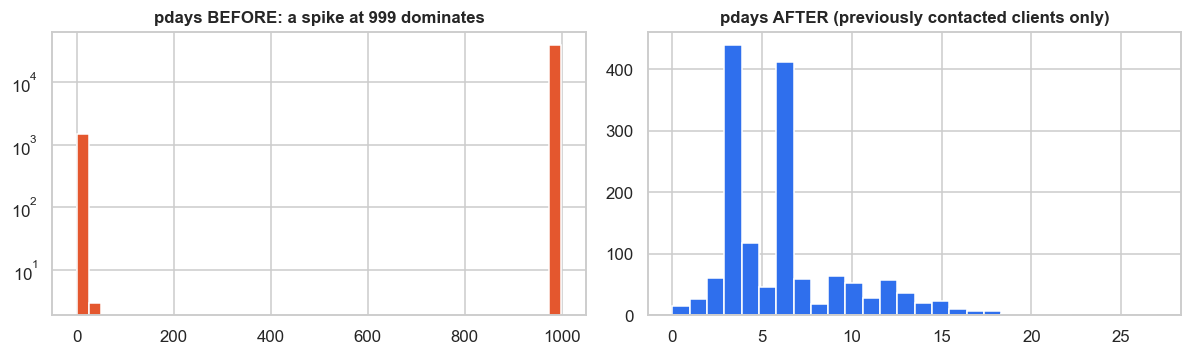

was_contacted_before = 1 for 1,515 rows (3.68%); pdays after re-coding runs 0 to 27.


In [34]:
fx = add_features(df)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["pdays"], bins=40, color=C_WARN); ax[0].set_title("pdays BEFORE: a spike at 999 dominates"); ax[0].set_yscale("log")
ax[1].hist(fx.loc[fx["was_contacted_before"] == 1, "pdays"], bins=28, color=C_MAIN); ax[1].set_title("pdays AFTER (previously contacted clients only)")
plt.tight_layout(); save_fig("prep_pdays")
print(f"was_contacted_before = 1 for {int(fx['was_contacted_before'].sum()):,} rows ({100 * fx['was_contacted_before'].mean():.2f}%); "
      f"pdays after re-coding runs {fx['pdays'].min()} to {fx['pdays'].max()}.")

---
## 4 · Skew and scale

### 4.1 `campaign`: a long right tail
**Options:** leave / clip at a cap / log transform. Clipping discards the difference between 10 and 50 calls; a log keeps the order and compresses the tail. **Decision: keep `campaign` and add `campaign_log = log(1 + campaign)`.** Tree models ignore monotone transforms, so the extra column is free for them and helps linear and neural models.

Skewness of campaign: 4.76  ->  of log(1 + campaign): 1.35  (0 = symmetric)


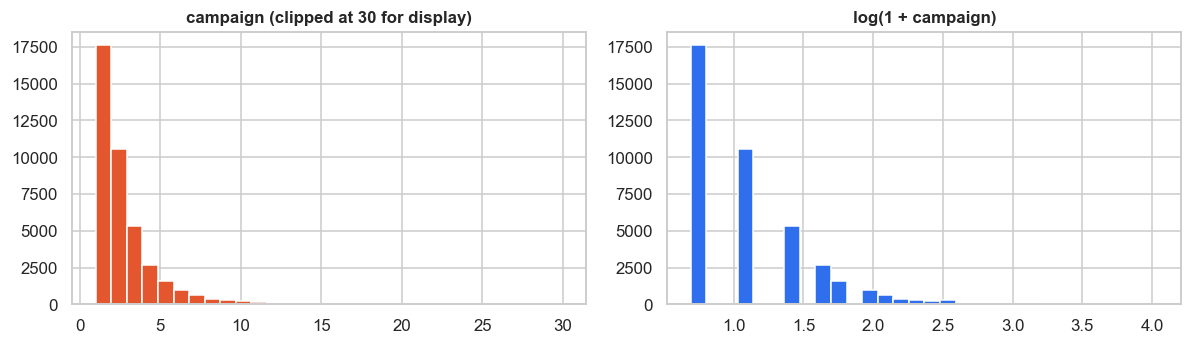

In [35]:
print(f"Skewness of campaign: {fx['campaign'].skew():.2f}  ->  of log(1 + campaign): {fx['campaign_log'].skew():.2f}  (0 = symmetric)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(fx["campaign"].clip(upper=30), bins=30, color=C_WARN); ax[0].set_title("campaign (clipped at 30 for display)")
ax[1].hist(fx["campaign_log"], bins=30, color=C_MAIN); ax[1].set_title("log(1 + campaign)")
plt.tight_layout(); save_fig("prep_campaign_log")

### 4.2 Scaling
Numeric columns live on very different scales (age in tens, `previous` in single digits, the removed macro columns in thousands). **Distance- or gradient-based models** (logistic regression, MLP, SVM) are sensitive to this; **tree models are not**. **Decision:** standardise numbers (mean 0, standard deviation 1, learned on the training rows) only for the models that need it, through the `scale` switch of `build_pipeline`. Quick evidence on the logistic regression:

In [36]:
num_cols, _ = active_columns()
scale_tbl = pd.DataFrame({"std before scaling": fx[num_cols].std(), "range before scaling": fx[num_cols].max() - fx[num_cols].min()}).round(2)
display(scale_tbl.T)
rows = []
for scale in (False, True):
    f = fc_eval(build_pipeline(LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), scale=scale), X_train, y_train)
    rows.append({"scaled": scale, "forward-chaining PR-AUC": f["pr_auc"].mean(), "ROC-AUC": f["roc_auc"].mean()})
display(pd.DataFrame(rows).set_index("scaled").round(4))

,age,campaign,campaign_log,pdays,previous,was_contacted_before,education_ord
std before scaling,10.420,2.770,0.490,1.350,0.490,0.190,1.640
range before scaling,81.000,55.000,3.350,27.000,7.000,1.000,6.000


,forward-chaining PR-AUC,ROC-AUC
scaled,,
False,0.099,0.543
True,0.098,0.539


**Reading.** Without scaling the regularised logistic regression penalises columns unevenly (a column with a large numeric range is penalised differently from a 0/1 flag), so scaling is part of a *fair* linear baseline. On this data the metric itself does not improve (the table above shows it unchanged or marginally lower), so scaling is kept for correctness and stable optimisation, not for a score gain.

---
## 5 · Splitting: respecting time

**Issue (EDA §9).** The response rate and the client mix drift. A shuffled split would put calls from the same month in both training and test and report an optimistic score.

**Options:** stratified random split (named in the proposal) / chronological split. **Decision: chronological.** The earliest 80% of rows are the *training period*; a block of 500 rows follows as a **pilot** (the first labelled calls of the new period; never scored); everything after is the **test period**, held out entirely and used once, in notebook 05. Model selection inside the training period uses *forward-chaining* folds (train on the past, validate on the next block) in addition to ordinary stratified folds.

The proposal asked for a stratified split. Stratification is still used where it is harmless, inside the cross-validation folds of notebooks 03-04, and notebook 05 (section 5) **measures how much a stratified random split would have flattered the results**, which turns the deviation into evidence.

In [37]:
per = ec.reconstruct_periods(df)
cut, pend = sp["cut"], sp["pilot_end"]
def span(a, b): return f"{per['period'].iloc[a]} -> {per['period'].iloc[b - 1]}"
summary = describe_split(sp)
summary["calendar span"] = [span(0, cut), span(cut, pend), span(pend, len(df))]
summary["mean euribor3m"] = [df["euribor3m"].iloc[:cut].mean(), df["euribor3m"].iloc[cut:pend].mean(), df["euribor3m"].iloc[pend:].mean()]
summary["response_rate"] = 100 * summary["response_rate"]
display(summary.rename(columns={"response_rate": "response_rate_%"}).round(2))
print("A stratified random split would give every part a response rate of about", round(100 * sp["y_all"].mean(), 1), "%.")

,rows,subscribers,response_rate_%,calendar span,mean euribor3m
part,,,,,
train,32940,2100,6.380,2008-05 -> 2009-05,4.270
pilot,500,32,6.400,2009-05 -> 2009-05,1.290
test,7736,2507,32.410,2009-05 -> 2010-11,1.010


A stratified random split would give every part a response rate of about 11.3 %.


**Reading.** Training, pilot and test periods differ in response rate and in the economic setting. That is **not a flaw in the split; it is the reality the bank would face**, and the final evaluation must show how the model copes with it. Two things follow for later notebooks: ranking quality is judged **within time blocks** and raw probabilities are **re-anchored** to the recent base rate (notebook 06).

**Why "fit on the training rows only" matters, shown with numbers.** A statistic learned from the whole file differs from the one learned from the training period; using the whole-file value would leak the future.

In [38]:
fx_all, fx_tr = add_features(df), add_features(sp["X_train"])
leak_demo = pd.DataFrame({
    "median education_ord": [fx_tr["education_ord"].median(), fx_all["education_ord"].median()],
    "mean age": [fx_tr["age"].mean(), fx_all["age"].mean()],
    "mean campaign": [fx_tr["campaign"].mean(), fx_all["campaign"].mean()],
    "share cellular %": [100 * (fx_tr["contact"] == "cellular").mean(), 100 * (fx_all["contact"] == "cellular").mean()],
}, index=["learned from TRAINING rows (what the pipeline does)", "learned from the WHOLE file (leaks the future)"])
display(leak_demo.round(3))

,median education_ord,mean age,mean campaign,share cellular %
learned from TRAINING rows (what the pipeline does),4.000,40.027,2.672,57.350
learned from the WHOLE file (leaks the future),4.000,40.024,2.568,63.471


---
## 6 · Feature engineering: the families promised in the proposal

The initial submission (section 15, step 4) promised four engineered feature families. Rather than add them and hope, each is tested against the baseline pipeline on the **same forward-chaining and stratified folds**.

| Family | Columns added | Why a bank might expect it to help |
|---|---|---|
| job / education groups | `job_group`, `edu_group` | 12 job levels are sparse; broader groups may generalise |
| loan interaction | `debt_load` (0-2), `housing_loan` | clients with both loans may be more cash-constrained |
| quarter indicators | `quarter` | coarser seasonality than `month` |
| `pdays` recency + previous success | `pdays_recent`, `pdays_late`, `pdays_log`, `prev_success` | fresh contacts and past successes are the strongest history signal |

**Adoption rule, stated before looking at any number:** a family is adopted only if it **improves mean forward-chaining PR-AUC, in at least 3 of 4 folds, and does not lower the stratified-CV PR-AUC.** A feature that helps only on shuffled folds is probably exploiting the calendar rather than the client.

fc_pr_auc  fc_delta fc_folds_better  cv_pr_auc  cv_delta        verdict
model                   features                                                                                                
Logistic regression     baseline                             0.098     0.000             0/4      0.201     0.000              -
                        + job/education groups               0.097    -0.001             2/4      0.201    -0.001  keep baseline
                        + loan interaction                   0.098     0.000             3/4      0.201    -0.000  keep baseline
                        + quarter indicators                 0.096    -0.002             1/4      0.201     0.000  keep baseline
                        + pdays recency + prev. success      0.098    -0.000             0/4      0.200    -0.002  keep baseline
                        + all four families                  0.096    -0.002             2/4      0.199    -0.002  keep baseline
Hist. gradient boosting baseline                             0.088     0.000             0/4      0.209     0.000              -
                        + job/education groups               0.088     0.000             3/4      0.209    -0.000  keep baseline
                        + loan interaction                   0.085    -0.002             0/4      0.209     0.000  keep baseline
                        + quarter indicators                 0.086    -0.001             0/4      0.211     0.002  keep baseline
                        + pdays recency + prev. success      0.088     0.000             0/4      0.210     0.001  keep baseline
                        + all four families                  0.084    -0.004             1/4      0.211     0.003  keep baseline

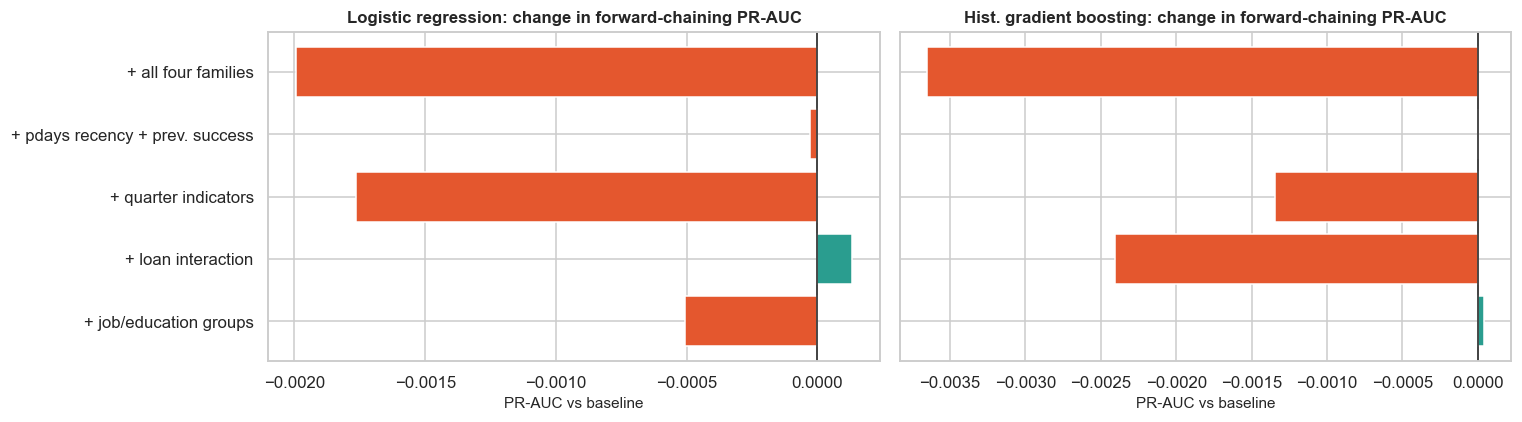

Families that pass the rule for at least one model: none


In [39]:
fe_configs = {"baseline": []}
fe_configs.update({f"+ {k}": [k] for k in FE_GROUPS})
fe_configs["+ all four families"] = list(FE_GROUPS)
FAM_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
              "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
cv_folds = 3 if FAST else 5
fe_fc, fe_cv = {}, {}
for mname, (factory, scale) in FAM_MODELS.items():
    for cname, groups in fe_configs.items():
        p = family_pipeline(factory(), groups, scale)
        fe_fc[(mname, cname)] = fc_eval(p, X_train, y_train)
        fe_cv[(mname, cname)] = cv_eval(p, X_train, y_train, cv_folds)

rows = []
for (mname, cname), f in fe_fc.items():
    f0, c0 = fe_fc[(mname, "baseline")], fe_cv[(mname, "baseline")]
    d = f["pr_auc"] - f0["pr_auc"]
    dc = fe_cv[(mname, cname)]["pr_auc"].mean() - c0["pr_auc"].mean()
    adopt = cname != "baseline" and d.mean() > 0 and (d > 0).sum() >= 3 and dc >= 0
    rows.append(dict(model=mname, features=cname, fc_pr_auc=f["pr_auc"].mean(), fc_delta=d.mean(),
                     fc_folds_better=f"{int((d > 0).sum())}/{len(d)}", cv_pr_auc=fe_cv[(mname, cname)]["pr_auc"].mean(), cv_delta=dc,
                     verdict="ADOPT" if adopt else ("-" if cname == "baseline" else "keep baseline")))
fe_table = pd.DataFrame(rows).set_index(["model", "features"])
display(fe_table.round(4))
fe_table.to_csv(TABLES_DIR / "preprocessing_feature_families.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, mname in zip(ax, FAM_MODELS):
    t = fe_table.loc[mname].drop("baseline")
    a.barh(t.index, t["fc_delta"], color=[C_OK if v > 0 else C_WARN for v in t["fc_delta"]]); a.axvline(0, color="k", lw=1)
    a.set_title(f"{mname}: change in forward-chaining PR-AUC"); a.set_xlabel("PR-AUC vs baseline")
plt.tight_layout(); save_fig("prep_feature_families")
adopted = sorted({c.replace("+ ", "") for (_, c), r in fe_table["verdict"].items() if r == "ADOPT" and not c.startswith("+ all")})
print("Families that pass the rule for at least one model:", adopted or "none")

**Decision rule in action.** If the table shows `ADOPT` for a family, list it in `ADOPTED_FAMILIES` in `src/config.py` (the one switch every later notebook reads) and re-run notebooks 03 onward. If every row says `keep baseline`, the baseline pipeline stays; this is a legitimate, evidence-based outcome, and it should be reported as such. The baseline columns already contain the information the families re-express (tree models can learn thresholds on `pdays`; `month` already covers quarters), which is the usual reason such families add little.

---
## 7 · Leakage and realism audit

### 7.1 Why `duration` must go: measured, not assumed
The same model, the same folds, with and without `duration`. If adding it makes the model look far better, that is not skill: it is information from the *future* of the call.

,roc_auc,pr_auc,lift_at_budget,recall_at_budget
"WITH duration (leaky, not deployable)",0.953 +/- 0.002,0.527 +/- 0.013,4.752 +/- 0.043,0.95 +/- 0.009
WITHOUT duration (honest),0.671 +/- 0.003,0.202 +/- 0.009,2.169 +/- 0.015,0.434 +/- 0.003


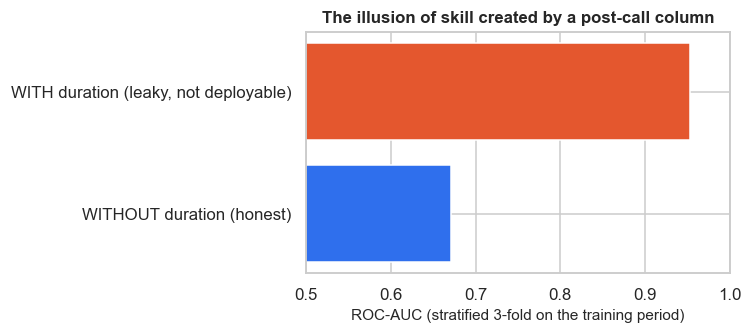

In [40]:
leak = {
    "WITH duration (leaky, not deployable)": cv_eval(build_pipeline(hgb(), scale=False, include_duration=True), X_train, y_train, 3),
    "WITHOUT duration (honest)": cv_eval(build_pipeline(hgb(), scale=False), X_train, y_train, 3),
}
leak_mean, leak_txt = summarise(leak)
display(leak_txt[["roc_auc", "pr_auc", "lift_at_budget", "recall_at_budget"]])
leak_mean.to_csv(TABLES_DIR / "preprocessing_leakage_duration.csv")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(list(leak_mean.index)[::-1], leak_mean["roc_auc"][::-1], color=[C_MAIN, C_WARN]); ax.set_xlim(0.5, 1); ax.set_xlabel("ROC-AUC (stratified 3-fold on the training period)")
ax.set_title("The illusion of skill created by a post-call column")
plt.tight_layout(); save_fig("prep_leakage_duration")

**Reading.** The gap between the two rows is created entirely by information that does not exist when the call list is built. A campaign manager cannot know how long a call *will* last. In the group's first run the leaky model reached a ROC-AUC of about 0.95 against about 0.67 for the honest one. Only the honest model answers the business question, so `duration` is never in `NUM_COLS`, and a test (`tests/test_preprocessing.py`) fails if it ever appears in a deployable pipeline.

### 7.2 A realism check for the grey-zone column `campaign`
`campaign` counts the calls to a client in this campaign, including the last one (EDA §2, §8). Clients who agree stop being called; clients who refuse are called again, so the final count partly records the outcome. If the model's skill depended mostly on this column, it would be *looking at the answer* in a mild form. Test: remove `campaign` and `campaign_log` and compare on forward-chaining folds.

**Rule fixed in advance:** if removing the column changes forward-chaining PR-AUC by **less than one standard deviation across folds**, the model is not relying on it, so it stays (as in the proposal) with the caveat documented. If removing it *improves* or barely changes the score, the group should seriously consider dropping it.

In [41]:
rows = []
for mname, (factory, scale) in FAM_MODELS.items():
    with_c = fc_eval(build_pipeline(factory(), scale=scale), X_train, y_train)
    without = fc_eval(build_pipeline(factory(), scale=scale, exclude=("campaign", "campaign_log")), X_train, y_train)
    d = (without["pr_auc"] - with_c["pr_auc"])
    sd = with_c["pr_auc"].std()
    rows.append(dict(model=mname, pr_auc_with_campaign=with_c["pr_auc"].mean(), pr_auc_without=without["pr_auc"].mean(),
                     change_when_removed=d.mean(), fold_sd=sd,
                     verdict="not relying on campaign: keep, document caveat" if abs(d.mean()) < sd else ("removing it HURTS: campaign carries signal (check reverse causality)" if d.mean() < 0 else "removing it HELPS: consider dropping campaign")))
campaign_test = pd.DataFrame(rows).set_index("model")
display(campaign_test.round(4))
campaign_test.to_csv(TABLES_DIR / "preprocessing_campaign_sensitivity.csv")

,pr_auc_with_campaign,pr_auc_without,change_when_removed,fold_sd,verdict
model,,,,,
Logistic regression,0.098,0.098,0.000,0.083,"not relying on campaign: keep, document caveat"
Hist. gradient boosting,0.088,0.084,-0.004,0.062,"not relying on campaign: keep, document caveat"


---
## 8 · The final pipeline and its automatic checks

`build_pipeline` assembles every decision above. We fit it on the **training period only** and then verify the properties that matter. Each check is an assertion: the notebook stops if one fails.

In [42]:
final_pipe = build_pipeline(LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), scale=True).fit(X_train, y_train)
pre = final_pipe.named_steps["prep"]
Z_train = final_pipe[:-1].transform(X_train)
Z_test = final_pipe[:-1].transform(X_test)

# 1. nothing missing reaches the model
assert not np.isnan(Z_train).any() and not np.isnan(Z_test).any(); print("OK  no missing values after preprocessing (train or test)")
# 2. same columns for train and test
assert Z_train.shape[1] == Z_test.shape[1]; print(f"OK  {Z_train.shape[1]} model inputs, identical for train and test")
# 3. leakage columns are absent
names = list(pre.get_feature_names_out())
assert not any("duration" in n for n in names); print("OK  `duration` is not a model input")
if EXCLUDE_MACRO:
    assert not any(any(m in n for m in MACRO_COLS) for n in names); print("OK  macro indicators are not model inputs (EXCLUDE_MACRO = True)")
# 4. the imputer learned its medians from TRAINING rows only
med = pre.named_transformers_["num"].named_steps["imp"].statistics_
expected = add_features(X_train)[active_columns()[0]].median().values
assert np.allclose(med, expected, equal_nan=True); print("OK  imputer medians equal the TRAINING medians")
# 5. an unseen category does not crash the pipeline
odd = X_test.iloc[:3].copy(); odd["job"] = "astronaut"
final_pipe.predict_proba(odd); print("OK  unseen category ('astronaut') is handled")
# 6. standardised numeric columns have mean ~0 and sd ~1 on training data
n_num = len(active_columns()[0])
assert np.allclose(Z_train[:, :n_num].mean(0), 0, atol=1e-6); print("OK  scaled numeric columns are centred on the training data")

OK  no missing values after preprocessing (train or test)
OK  52 model inputs, identical for train and test
OK  `duration` is not a model input
OK  macro indicators are not model inputs (EXCLUDE_MACRO = True)
OK  imputer medians equal the TRAINING medians
OK  unseen category ('astronaut') is handled
OK  scaled numeric columns are centred on the training data


In [43]:
flog = feature_log(final_pipe, X_train)
flog.to_csv(TABLES_DIR / "final_feature_list.csv", index=False)
print(f"{len(flog)} model inputs built from {flog['source_column'].nunique()} source columns")
display(flog.groupby("source_column").agg(inputs=("model_input", "size"), treatment=("treatment", "first")).sort_values("inputs", ascending=False))
display(flog.head(12))

52 model inputs built from 16 source columns


,inputs,treatment
source_column,,
job,12,one-hot indicator
month,9,one-hot indicator
day_of_week,5,one-hot indicator
marital,4,one-hot indicator
loan,3,one-hot indicator
default,3,one-hot indicator
housing,3,one-hot indicator
poutcome,3,one-hot indicator
contact,2,one-hot indicator


,model_input,source_column,treatment,mean_after,std_after
0,num__age,age,median-imputed + standardised,-0.000,1.000
1,num__campaign,campaign,median-imputed + standardised,-0.000,1.000
2,num__campaign_log,campaign_log,median-imputed + standardised,0.000,1.000
3,num__pdays,pdays,median-imputed + standardised,0.000,1.000
4,num__previous,previous,median-imputed + standardised,0.000,1.000
5,num__was_contacted_before,was_contacted_before,median-imputed + standardised,-0.000,1.000
6,num__education_ord,education_ord,median-imputed + standardised,-0.000,1.000
7,num__missingindicator_education_ord,education_ord,missing-value indicator (1 = was 'unknown'),0.000,1.000
8,cat__job_admin.,job,one-hot indicator,0.244,0.430
9,cat__job_blue-collar,job,one-hot indicator,0.242,0.428


---
## 9 · Preprocessing decision log

| # | Issue | Options considered | Decision | Evidence |
|---|---|---|---|---|
| P1 | 12 duplicate rows | keep / drop | Drop, keep first and original order | §3.1 |
| P2 | `unknown` in categorical columns | own category / mode imputation / drop rows | Own category (verdict printed in §3.2) | §3.2 forward-chaining test, EDA 3.4 |
| P3 | `unknown` education | one-hot / ordinal | Ordinal; `unknown` → NaN → training median + missing indicator | §3.2 |
| P4 | `pdays = 999` | leave / impute / flag + 0 | Flag `was_contacted_before`, placeholder → 0 | §3.3, EDA 3.6 |
| P5 | Skewed `campaign` | leave / clip / log | Keep + `campaign_log` | §4.1 |
| P6 | Scales differ | none / standardise | Standardise for linear, neural, SVM models only | §4.2 |
| P7 | Drift over time | stratified random / chronological | Chronological train / pilot / test; forward-chaining CV | §5, EDA §9 |
| P8 | Proposal feature families | baseline / each / all | Adopt only if ≥ 3 of 4 forward-chaining folds improve and CV does not fall (verdict in §6) | §6 |
| P9 | `duration` | keep / drop | Drop: known only after the call | §7.1 |
| P10 | `campaign` reverse causality | keep / drop | Keep, caveat; sensitivity test (verdict in §7.2) | §7.2 |
| P11 | Macro indicators | include / exclude | Exclude by default; tested in notebook 03 §5 | EDA §10 |
| P12 | Leakage control | manual / structural | Every learned step inside one `Pipeline`; asserted in §8 and `tests/` | §8 |

**Hand-off.** Notebooks 03-08 import `build_pipeline` and the split from `src/` and **do not re-implement any preprocessing**. The feature list is saved to `reports/tables/final_feature_list.csv`; the group-level write-up of these decisions is `docs/preprocessing_log.md`.

---
---
# PART 3 of 8: MODEL COMPARISON
*(source notebook: `03_model_comparison.ipynb`)*

# 03 · Model Comparison
### IT3091 Machine Learning · Group 2026-AI-42 · Modelling & comparison lead

**Question.** Which family of model ranks clients best, and is the difference larger than the noise?
**Input:** the cleaned data and pipeline from notebook 02. **Output:** the model family selected for tuning (`artifacts/selection.json`).

Every candidate sits behind the **same preprocessing pipeline** and is scored on the **same folds**, so differences come from the model, not from the data handling.

| Model | Why included | Interpretability |
|---|---|---|
| **Dummy (prior)** | Baseline: what do we get with no information? | n/a |
| **Logistic regression** (balanced) | Strong, transparent benchmark; coefficients can be explained to compliance | High |
| **Random forest** (balanced) | Non-linear interactions, robust to scale and outliers | Medium |
| **Hist. gradient boosting** | Typically strongest on tabular data | Medium |
| **MLP (64-32)** | Does a neural model add anything on tabular data? | Low |
| Decision tree, gradient boosting, XGBoost, LightGBM, SVM | The remaining models named in the proposal (section 6 below) | varies |

**Two validation views.** Stratified 5-fold CV (shuffled; keeps class balance per fold) and **forward-chaining** CV (train on the past, validate on the next block). The data drift over time (EDA §9), so **forward-chaining is the better guide to a real campaign** and decides the selection.

In [44]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

from src.config import *
from src.data.prepare import load_modelling_data
from src.data.loading import load_bank_full
from src.data.splits import deduplicate, split_xy
from src.evaluation.metrics import cv_eval, fc_eval, summarise, metric_row, scores_of
from src.features.preprocessing import build_pipeline, add_features, NUM_COLS, CAT_COLS, MACRO
from src.models.candidates import build_main_models, build_challenger_specs, hgb, MAIN_FAMILIES
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
FAST = False      # True = fewer folds, skips the slowest challenger, for a dry run
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
models = build_main_models()

Loading local file: bank-additional-full.csv


Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Stratified cross-validation on the training period
Metrics are ranking- and budget-based because accuracy hides the minority class: **PR-AUC**, **ROC-AUC**, and precision / recall / **lift among the top `CALL_BUDGET` share of clients**. The dummy model's accuracy is shown once, to show why it is not used.

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,accuracy_at_0_5,fit_seconds
Dummy (prior),0.5 +/- 0.0,0.064 +/- 0.0,0.065 +/- 0.003,0.205 +/- 0.01,1.026 +/- 0.048,0.936 +/- 0.0,0.273 +/- 0.032
Logistic regression,0.668 +/- 0.019,0.201 +/- 0.028,0.133 +/- 0.008,0.419 +/- 0.025,2.092 +/- 0.123,0.73 +/- 0.009,0.428 +/- 0.054
Random forest,0.66 +/- 0.01,0.197 +/- 0.023,0.139 +/- 0.008,0.435 +/- 0.026,2.173 +/- 0.128,0.909 +/- 0.002,2.087 +/- 0.036
Hist. gradient boosting,0.668 +/- 0.012,0.21 +/- 0.021,0.141 +/- 0.005,0.442 +/- 0.017,2.209 +/- 0.085,0.778 +/- 0.006,0.878 +/- 0.149
MLP (64-32),0.668 +/- 0.016,0.204 +/- 0.032,0.136 +/- 0.009,0.426 +/- 0.029,2.128 +/- 0.144,0.936 +/- 0.001,3.488 +/- 0.652


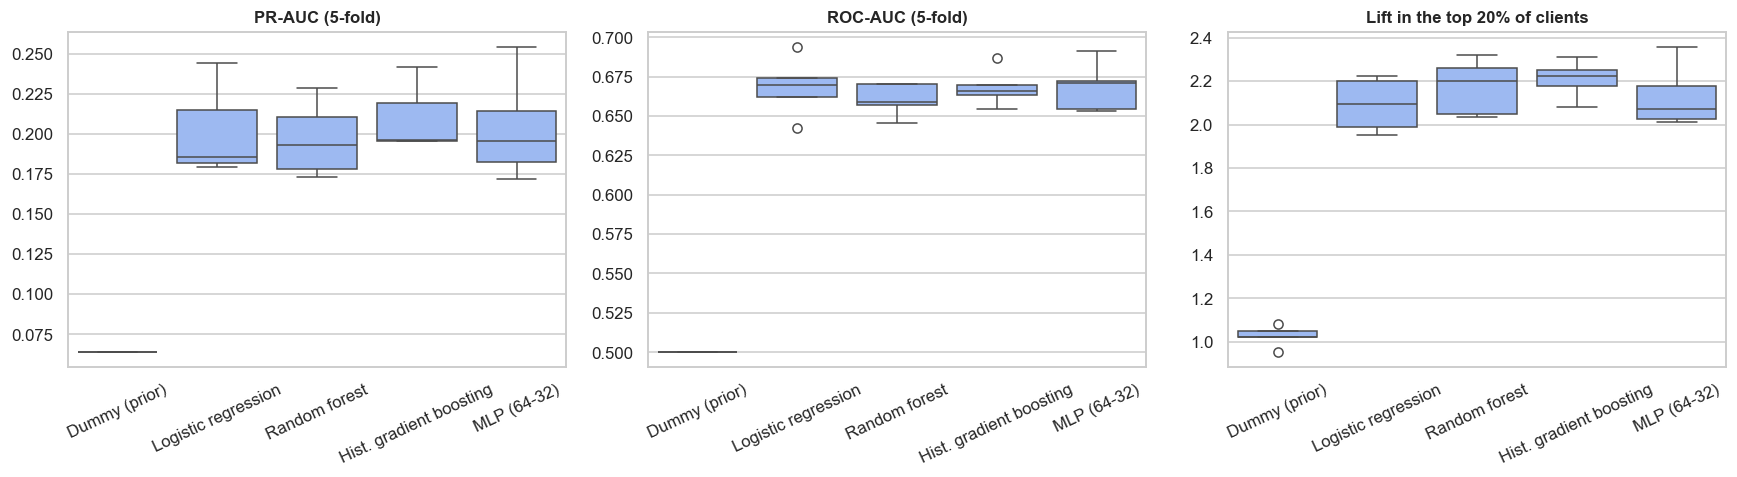

Dummy accuracy at 0.5 = 0.936 -> a good-looking number with zero business value.


In [45]:
cv_results = {name: cv_eval(p, X_train, y_train, 3 if FAST else 5) for name, p in models.items()}
cv_mean, cv_txt = summarise(cv_results)
display(cv_txt[["roc_auc", "pr_auc", "precision_at_budget", "recall_at_budget", "lift_at_budget", "accuracy_at_0_5", "fit_seconds"]])
cv_mean.to_csv(TABLES_DIR / "model_comparison_stratified_cv.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric, title in zip(ax, ["pr_auc", "roc_auc", "lift_at_budget"], ["PR-AUC (5-fold)", "ROC-AUC (5-fold)", f"Lift in the top {CALL_BUDGET:.0%} of clients"]):
    sns.boxplot(data=pd.DataFrame({k: v[metric] for k, v in cv_results.items()}), ax=a, color="#8fb4ff"); a.set_title(title); a.tick_params(axis="x", rotation=25)
plt.tight_layout(); save_fig("model_cv_boxplots")
print("Dummy accuracy at 0.5 =", cv_mean.loc["Dummy (prior)", "accuracy_at_0_5"].round(3), "-> a good-looking number with zero business value.")

In [46]:
# Paired comparison: all models were scored on the SAME folds, so fold-wise differences are meaningful.
ref = "Hist. gradient boosting"
rows = []
for name, r in cv_results.items():
    if name in (ref, "Dummy (prior)"):
        continue
    d, da = cv_results[ref]["pr_auc"] - r["pr_auc"], cv_results[ref]["roc_auc"] - r["roc_auc"]
    rows.append({"vs model": name, "mean PR-AUC gain of HGB": d.mean(), "SD of gain": d.std(), "folds HGB better (PR-AUC)": f"{int((d > 0).sum())}/{len(d)}",
                 "mean ROC-AUC gain of HGB": da.mean(), "folds HGB better (ROC-AUC)": f"{int((da > 0).sum())}/{len(da)}"})
display(pd.DataFrame(rows).set_index("vs model").round(4))
print("Rule of thumb: with five folds, a gain below ~1-2x its SD, or one that does not appear in every fold, is NOT evidence of a real difference.")

,mean PR-AUC gain of HGB,SD of gain,folds HGB better (PR-AUC),mean ROC-AUC gain of HGB,folds HGB better (ROC-AUC)
vs model,,,,,
Logistic regression,0.009,0.008,4/5,-0.000,2/5
Random forest,0.013,0.008,5/5,0.008,3/5
MLP (64-32),0.006,0.014,4/5,-0.000,2/5


Rule of thumb: with five folds, a gain below ~1-2x its SD, or one that does not appear in every fold, is NOT evidence of a real difference.


**Reading.** Compare models on PR-AUC and lift, and check the fold-to-fold spread. If two models overlap within noise, prefer the simpler, more interpretable one. Stratified folds mix early and late contacts, so they are a *first* look; the next section is the one that decides.

---
## 2 · Time-aware comparison (forward-chaining)
Every fold trains on the **past** and validates on the **next block**: the way a model would really be used. Random CV flatters models that exploit the *time period* rather than the *client*, so if the ranking here differs from section 1, the forward-chaining ranking is the better guide.

In [47]:
fc_models = {k: models[k] for k in ["Logistic regression", "Random forest", "Hist. gradient boosting", "MLP (64-32)"]}
fc_results = {name: fc_eval(p, X_train, y_train) for name, p in fc_models.items()}
fc_mean, fc_txt = summarise(fc_results)
display(fc_txt[["roc_auc", "pr_auc", "lift_at_budget"]])
fc_mean.to_csv(TABLES_DIR / "model_comparison_forward_chaining.csv")
print("Validation base rate per forward-chaining fold:", fc_results["Logistic regression"]["val_base_rate"].round(3).tolist())

,roc_auc,pr_auc,lift_at_budget
Logistic regression,0.539 +/- 0.081,0.098 +/- 0.083,1.229 +/- 0.491
Random forest,0.526 +/- 0.071,0.087 +/- 0.064,1.214 +/- 0.326
Hist. gradient boosting,0.53 +/- 0.07,0.088 +/- 0.065,1.218 +/- 0.273
MLP (64-32),0.52 +/- 0.021,0.081 +/- 0.048,1.189 +/- 0.203


Validation base rate per forward-chaining fold: [0.044, 0.063, 0.055, 0.127]


**Reading.** Absolute scores are lower and more variable here than in section 1, and the validation blocks have different base rates. That gap *is* the honest estimate of deployment risk: a model trained on yesterday's market is scored on tomorrow's. PR-AUC also depends on the base rate, so across folds compare **lift** and **ROC-AUC** as well.

---
## 3 · The remaining models named in the proposal
The proposal also lists a Decision Tree, Gradient Boosting, an optional SVM (§11) and XGBoost / LightGBM (§15). They enter as **challengers** with the same pipeline, folds and metrics. An exact RBF-kernel SVM scales quadratically with rows, so the SVM is approximated by **Nystroem features + a linear SVM** (it outputs a decision value, so only its *ranking* is compared). Fit time is reported because the proposal also judges operational feasibility.

**Rule for a challenger to displace the incumbent (fixed before running):** higher mean forward-chaining PR-AUC **and** better in at least 3 of 4 folds. Otherwise the simpler or already-chosen model stays.

,group,cv_pr_auc,cv_pr_auc_sd,fc_pr_auc,fc_pr_auc_sd,fc_roc_auc,fc_lift,fit_seconds
model,,,,,,,,
Logistic regression,main,0.201,0.028,0.098,0.083,0.539,1.229,0.428
Hist. gradient boosting,main,0.210,0.021,0.088,0.065,0.530,1.218,0.878
SVM (RBF approx.),challenger,0.192,0.026,0.088,0.068,0.526,1.138,5.614
Random forest,main,0.197,0.023,0.087,0.064,0.526,1.214,2.087
XGBoost,challenger,0.205,0.023,0.083,0.057,0.520,1.095,1.004
MLP (64-32),main,0.204,0.032,0.081,0.048,0.520,1.189,3.488
LightGBM,challenger,0.201,0.028,0.079,0.050,0.512,1.045,1.235
Decision tree,challenger,0.173,0.018,0.078,0.052,0.501,1.030,0.323
Gradient boosting (sklearn),challenger,0.202,0.019,0.075,0.041,0.511,1.008,4.703


,incumbent,mean_pr_auc_gain,sd_of_gain,folds_better,verdict
challenger,,,,,
Decision tree,Logistic regression,-0.019,0.032,0/4,keep incumbent
Gradient boosting (sklearn),Logistic regression,-0.023,0.043,1/4,keep incumbent
XGBoost,Logistic regression,-0.014,0.027,1/4,keep incumbent
LightGBM,Logistic regression,-0.018,0.034,1/4,keep incumbent
SVM (RBF approx.),Logistic regression,-0.010,0.015,0/4,keep incumbent


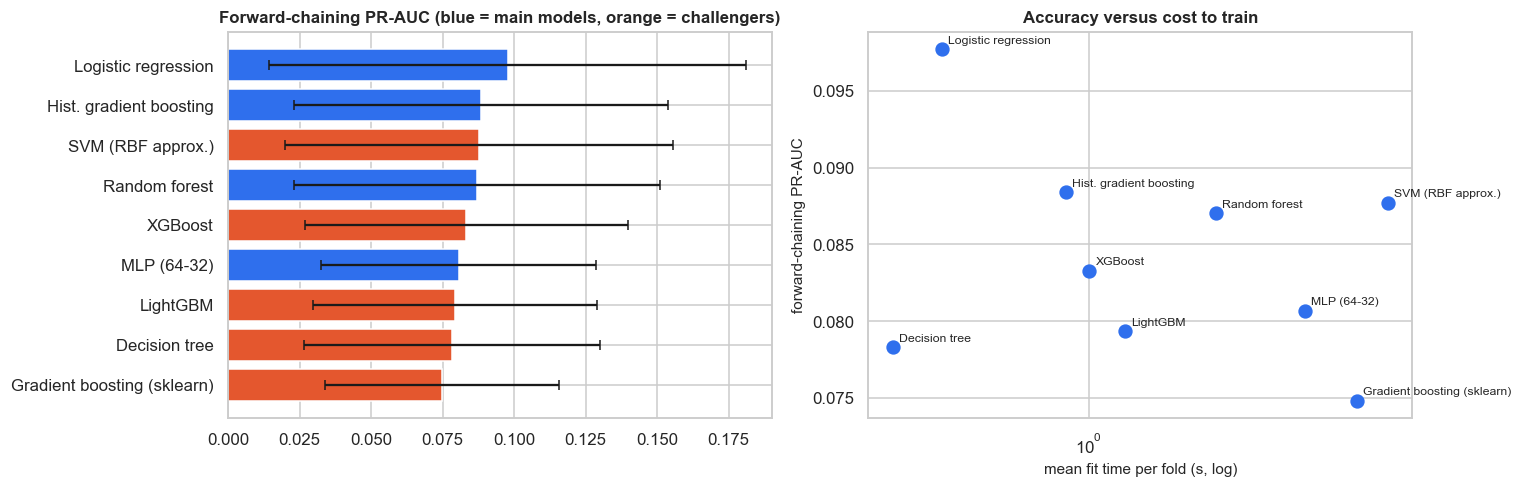

In [48]:
zoo_specs = build_challenger_specs(y_train)
if FAST:
    zoo_specs.pop("Gradient boosting (sklearn)")
zoo_cv = {k: cv_eval(build_pipeline(m, scale=sc), X_train, y_train, 3 if FAST else 5) for k, (m, sc) in zoo_specs.items()}
zoo_fc = {k: fc_eval(build_pipeline(m, scale=sc), X_train, y_train) for k, (m, sc) in zoo_specs.items()}

rows = []
for src_, names, cvd, fcd in [("main", list(fc_results), cv_results, fc_results), ("challenger", list(zoo_specs), zoo_cv, zoo_fc)]:
    for k in names:
        rows.append(dict(model=k, group=src_, cv_pr_auc=cvd[k]["pr_auc"].mean(), cv_pr_auc_sd=cvd[k]["pr_auc"].std(),
                         fc_pr_auc=fcd[k]["pr_auc"].mean(), fc_pr_auc_sd=fcd[k]["pr_auc"].std(), fc_roc_auc=fcd[k]["roc_auc"].mean(),
                         fc_lift=fcd[k]["lift_at_budget"].mean(), fit_seconds=cvd[k]["fit_seconds"].mean()))
zoo_table = pd.DataFrame(rows).set_index("model").sort_values("fc_pr_auc", ascending=False)
display(zoo_table.round(3))
zoo_table.to_csv(TABLES_DIR / "model_comparison_all_models.csv")

ref_main = max(MAIN_FAMILIES, key=lambda k: fc_results[k]["pr_auc"].mean())
rows = []
for k in zoo_specs:
    d = zoo_fc[k]["pr_auc"] - fc_results[ref_main]["pr_auc"]
    rows.append(dict(challenger=k, incumbent=ref_main, mean_pr_auc_gain=d.mean(), sd_of_gain=d.std(), folds_better=f"{int((d > 0).sum())}/{len(d)}",
                     verdict="consider switching" if (d.mean() > 0 and (d > 0).sum() >= 3) else "keep incumbent"))
display(pd.DataFrame(rows).set_index("challenger").round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
t = zoo_table.sort_values("fc_pr_auc")
ax[0].barh(t.index, t["fc_pr_auc"], xerr=t["fc_pr_auc_sd"], color=[C_MAIN if g == "main" else C_WARN for g in t["group"]], capsize=3)
ax[0].set_title("Forward-chaining PR-AUC (blue = main models, orange = challengers)")
ax[1].scatter(zoo_table["fit_seconds"], zoo_table["fc_pr_auc"], s=70, color=C_MAIN)
for k, r in zoo_table.iterrows():
    ax[1].annotate(k, (r["fit_seconds"], r["fc_pr_auc"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("mean fit time per fold (s, log)"); ax[1].set_ylabel("forward-chaining PR-AUC"); ax[1].set_title("Accuracy versus cost to train")
plt.tight_layout(); save_fig("model_zoo")

---
## 4 · Selecting the family to tune
The family is chosen by **forward-chaining PR-AUC among the three main families** (logistic regression, random forest, histogram gradient boosting), the same rule that notebook 04 reads. Challengers are reported, not silently promoted: they displace the incumbent only under the rule in section 3.

In [49]:
best_family = max(MAIN_FAMILIES, key=lambda k: fc_results[k]["pr_auc"].mean())
print("Family chosen by forward-chaining PR-AUC:", best_family, f"({fc_results[best_family]['pr_auc'].mean():.3f})")
print("Highest stratified-CV PR-AUC            :", cv_mean["pr_auc"].idxmax(), f"({cv_mean['pr_auc'].max():.3f})")
(ARTIFACTS_DIR / "selection.json").write_text(json.dumps({"best_family": best_family}, indent=2))

Family chosen by forward-chaining PR-AUC: Logistic regression (0.098)
Highest stratified-CV PR-AUC            : Hist. gradient boosting (0.210)


42

---
## 5 · Which data version, and do the macro indicators help out of time?

Two data decisions were deliberately left open by the proposal and the EDA, and are settled with a measurement here. Three variants, the same model settings, the same chronological design:

* **A** `bank-full.csv`: the proposal's choice (16 attributes; it has `balance` and `day`, which the other file lacks)
* **B** `bank-additional-full.csv`: client and campaign attributes only (no macro indicators): **this project's default**
* **C** `bank-additional-full.csv` plus the five macro indicators

*A vs B* asks "does the file version matter?"; *B vs C* asks "do the macro indicators add anything that survives the time split?". Base rates differ between files, so compare **lift** and ROC-AUC rather than raw PR-AUC. **Rule fixed in advance:** keep B unless A beats B and C on **both** forward-chaining and hold-out lift. This is a *data* comparison, not model selection: the hold-out values here are for the version decision only and do not touch the final model.

Loading local file: bank-full.csv


train_rate  fc_pr_auc  fc_roc_auc  fc_lift  fc_lift_sd  hold_roc_auc  hold_pr_auc  hold_lift
version                 model                                                                                                                
A  bank-full (proposal) Logistic regression           0.067      0.093       0.555    1.260       0.152         0.678        0.496      1.748
                        Hist. gradient boosting       0.067      0.094       0.546    1.243       0.139         0.679        0.484      1.644
B  additional, no macro Logistic regression           0.064      0.098       0.539    1.229       0.491         0.691        0.502      1.725
                        Hist. gradient boosting       0.064      0.088       0.530    1.198       0.245         0.660        0.466      1.648
C  additional + 5 macro Logistic regression           0.064      0.076       0.516    0.920       0.291         0.695        0.511      1.783
                        Hist. gradient boosting       0.064      0.079       0.517    1.145       0.140         0.608        0.416      1.540

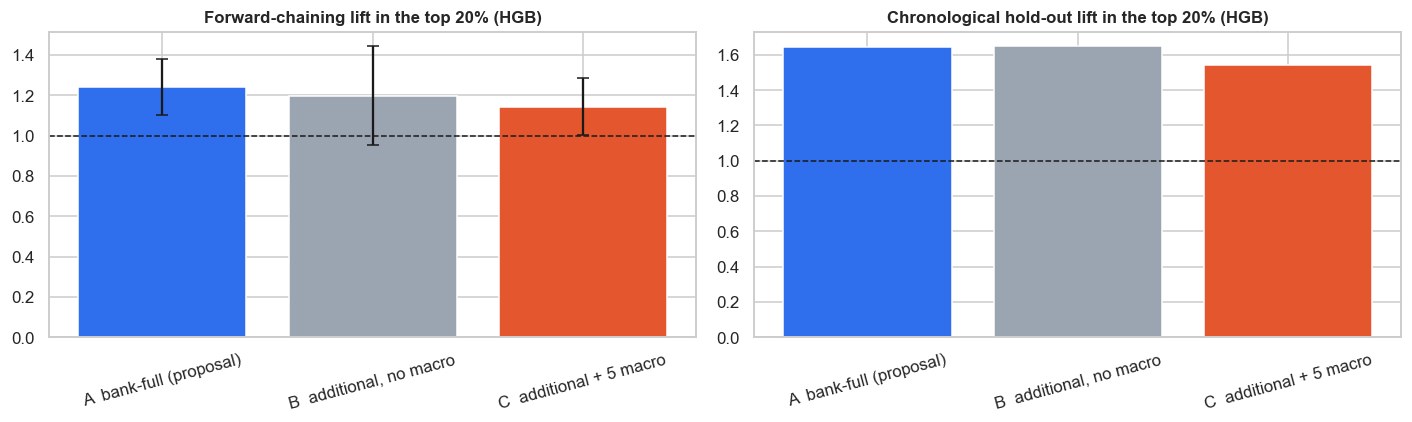

In [50]:
try:
    bf_raw = load_bank_full()
    HAVE_BF = True
except Exception as e:
    print("bank-full.csv is not available (", type(e).__name__, "); variants B and C are still compared.")
    HAVE_BF = False

def bf_features(X):
    X = X.copy()
    X["was_contacted_before"] = (X["pdays"] != -1).astype(int)
    X["pdays"] = X["pdays"].where(X["pdays"] != -1, 0)
    X["campaign_log"] = np.log1p(X["campaign"])
    X["balance_slog"] = np.sign(X["balance"]) * np.log1p(np.abs(X["balance"]))     # heavy-tailed, can be negative
    X["education_ord"] = X["education"].map({"primary": 1, "secondary": 2, "tertiary": 3})
    return X
BF_NUM = ["age", "balance_slog", "day", "campaign", "campaign_log", "pdays", "previous", "was_contacted_before", "education_ord"]
BF_CAT = ["job", "marital", "default", "housing", "loan", "contact", "month", "poutcome"]

def chrono(X_, y_):
    c = int(len(X_) * (1 - TEST_FRACTION))                       # same design as notebook 02, including the pilot gap
    return X_.iloc[:c].reset_index(drop=True), y_[:c], X_.iloc[c + PILOT_ROWS:].reset_index(drop=True), y_[c + PILOT_ROWS:]

no_macro = [c for c in NUM_COLS if c not in MACRO]
versions = {"B  additional, no macro": dict(fe=add_features, num=no_macro, cat=CAT_COLS, d=(X_train, y_train, X_test, y_test)),
            "C  additional + 5 macro": dict(fe=add_features, num=NUM_COLS, cat=CAT_COLS, d=(X_train, y_train, X_test, y_test))}
if HAVE_BF:
    bf = deduplicate(bf_raw); bf_X, bf_y = split_xy(bf)
    versions = {"A  bank-full (proposal)": dict(fe=bf_features, num=BF_NUM, cat=BF_CAT, d=chrono(bf_X, bf_y)), **versions}

VER_MODELS = {"Logistic regression": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True),
              "Hist. gradient boosting": (lambda: hgb(learning_rate=0.06, max_iter=200, class_weight="balanced"), False)}
rows = []
for vname, v in versions.items():
    Xtr, ytr, Xte, yte = v["d"]
    for mname, (factory, scale) in VER_MODELS.items():
        p = build_pipeline(factory(), scale=scale, fe=v["fe"], num=v["num"], cat=v["cat"])
        f = fc_eval(p, Xtr, ytr)
        h = metric_row(yte, scores_of(clone(p).fit(Xtr, ytr), Xte))
        rows.append(dict(version=vname, model=mname, train_rate=ytr.mean(), fc_pr_auc=f["pr_auc"].mean(), fc_roc_auc=f["roc_auc"].mean(),
                         fc_lift=f["lift_at_budget"].mean(), fc_lift_sd=f["lift_at_budget"].std(),
                         hold_roc_auc=h["roc_auc"], hold_pr_auc=h["pr_auc"], hold_lift=h["lift_at_budget"]))
ver_table = pd.DataFrame(rows).set_index(["version", "model"])
display(ver_table.round(3))
ver_table.to_csv(TABLES_DIR / "model_comparison_dataset_version.csv")

hg = ver_table.xs("Hist. gradient boosting", level="model")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cols = [C_MAIN, C_GREY, C_WARN][-len(hg):]
ax[0].bar(hg.index, hg["fc_lift"], yerr=hg["fc_lift_sd"], color=cols, capsize=4); ax[0].set_title(f"Forward-chaining lift in the top {CALL_BUDGET:.0%} (HGB)")
ax[1].bar(hg.index, hg["hold_lift"], color=cols); ax[1].set_title(f"Chronological hold-out lift in the top {CALL_BUDGET:.0%} (HGB)")
for a in ax:
    a.axhline(1, color="k", ls="--", lw=1); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); save_fig("model_dataset_version")

**How to read it.** The macro question is *B vs C* on the **forward-chaining** columns: if C is not clearly better than B there (and not better on the hold-out for the same reason), the indicators are acting as a time proxy rather than adding stable client information, which supports `EXCLUDE_MACRO = True`. The data-version question is *A vs B*: if A is clearly better on both views, the proposal's original dataset choice was the stronger one and the group should say so. Either outcome is a legitimate, evidence-based reading; record it as decision D11 in `docs/decision_log.md`.

---
---
# PART 4 of 8: IMBALANCE HANDLING AND TUNING
*(source notebook: `04_imbalance_and_tuning.ipynb`)*

# 04 · Imbalance Handling and Hyper-parameter Tuning
### IT3091 Machine Learning · Group 2026-AI-42 · Modelling & comparison lead

**Questions.** (1) Does re-balancing the classes improve the **ranking** of clients, or only change the scale of the scores? (2) Which settings of the selected model family work best on time-aware folds?
**Input:** `artifacts/selection.json` from notebook 03. **Output:** `artifacts/tuned_pipeline.joblib` and `artifacts/tuned_params.json`.

Only about one contact in nine subscribes, so it is tempting to assume "imbalance needs SMOTE". We **test** it. All resampling happens **inside** the training part of each fold through an imbalanced-learn pipeline, never before splitting (that would copy information from validation rows into training).

In [51]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import cv_eval, summarise
from src.features.preprocessing import build_pipeline, HAS_IMB
from src.models.candidates import hgb, tuning_spaces
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train = data["X_train"], data["y_train"]
print("imbalanced-learn available:", HAS_IMB)

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)
imbalanced-learn available: True


---
## 1 · Class weights and SMOTE
Re-weighting and resampling mostly change the **scale** of predicted probabilities, not the **ranking**, so ranking metrics usually move little. The business decision that really depends on imbalance is the **cut-off**, which is set from economics and recent data in notebook 06.

In [52]:
imb = {
    "HGB: no weighting": build_pipeline(hgb(learning_rate=0.05, max_iter=300), scale=False),
    "HGB: class weights": build_pipeline(hgb(learning_rate=0.05, max_iter=300, class_weight="balanced"), scale=False),
    "LR: no weighting": build_pipeline(LogisticRegression(max_iter=3000, C=0.5), scale=True),
    "LR: class weights": build_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5), scale=True),
}
if HAS_IMB:
    imb["HGB: SMOTE"] = build_pipeline(hgb(learning_rate=0.05, max_iter=300), scale=False, smote=True)
imb_results = {k: cv_eval(p, X_train, y_train, 3) for k, p in imb.items()}
imb_mean, imb_txt = summarise(imb_results)
display(imb_txt[["roc_auc", "pr_auc", "lift_at_budget", "recall_at_budget"]])

,roc_auc,pr_auc,lift_at_budget,recall_at_budget
HGB: no weighting,0.676 +/- 0.003,0.207 +/- 0.009,2.212 +/- 0.07,0.442 +/- 0.014
HGB: class weights,0.67 +/- 0.002,0.209 +/- 0.009,2.226 +/- 0.041,0.445 +/- 0.008
LR: no weighting,0.669 +/- 0.01,0.203 +/- 0.011,2.145 +/- 0.069,0.429 +/- 0.014
LR: class weights,0.67 +/- 0.009,0.201 +/- 0.014,2.119 +/- 0.103,0.424 +/- 0.021
HGB: SMOTE,0.659 +/- 0.006,0.19 +/- 0.011,2.136 +/- 0.075,0.427 +/- 0.015


---
## 2 · SMOTE-Tomek: the resampler named in the proposal
SMOTE-Tomek first creates synthetic minority points (SMOTE), then removes **Tomek links** (majority / minority pairs that are each other's nearest neighbours) to clean the class boundary. It is applied **inside** each training fold only. We compare it with *no weighting* and *class weights* on **ranking quality and on probability quality**, because resampling is known to shift predicted probabilities: `score_inflation` far above 1.0 and a worse Brier score mean the model overstates every client's chance of subscribing.

*Caveat:* SMOTE on one-hot columns creates fractional category values, a known limitation of the method on mixed data.

,roc_auc,pr_auc,lift_at_budget,brier,mean_score,base_rate,score_inflation,fit_seconds
HGB: no weighting,0.676,0.207,2.212,0.055,0.064,0.064,1.002,0.924
HGB: class weights,0.670,0.209,2.226,0.192,0.423,0.064,6.634,1.042
HGB: SMOTE-Tomek,0.662,0.192,2.114,0.057,0.075,0.064,1.172,3.838
LR: no weighting,0.669,0.203,2.145,0.056,0.064,0.064,0.999,0.318
LR: class weights,0.670,0.201,2.119,0.211,0.447,0.064,7.018,0.292
LR: SMOTE-Tomek,0.665,0.202,2.124,0.207,0.437,0.064,6.853,2.034


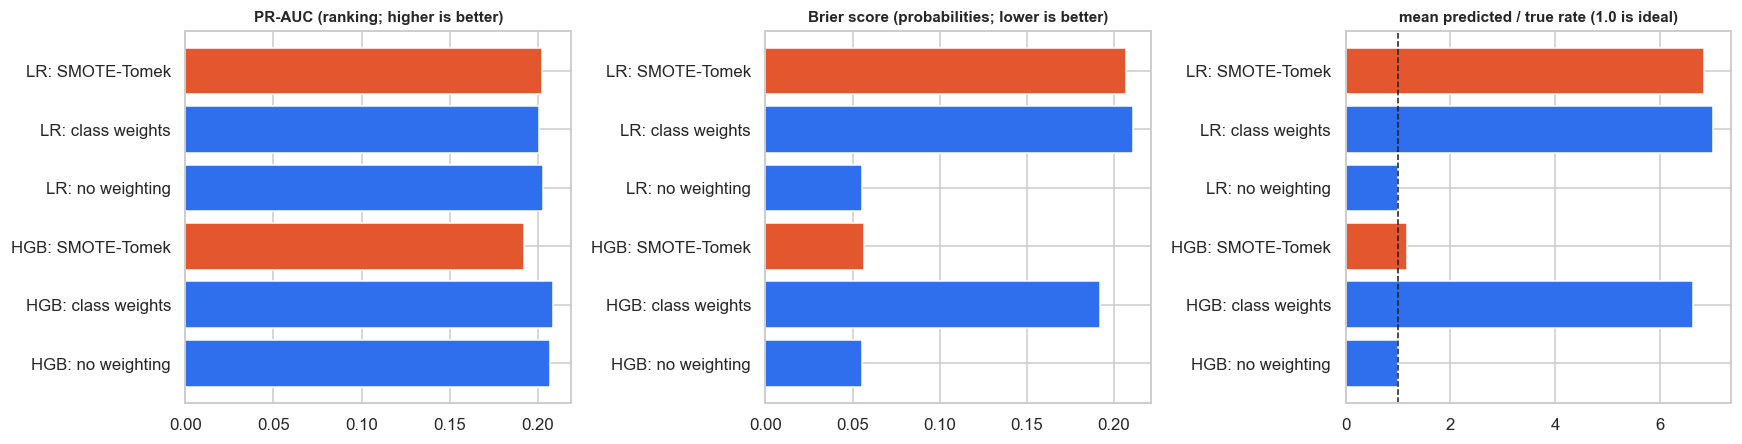

In [53]:
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks
smt_specs = {   # name -> (model factory, scale?, sampler factory or None)
    "HGB: no weighting": (lambda: hgb(learning_rate=0.05, max_iter=300), False, None),
    "HGB: class weights": (lambda: hgb(learning_rate=0.05, max_iter=300, class_weight="balanced"), False, None),
    "HGB: SMOTE-Tomek": (lambda: hgb(learning_rate=0.05, max_iter=300), False, lambda: SMOTETomek(random_state=SEED, tomek=TomekLinks(n_jobs=-1))),
    "LR: no weighting": (lambda: LogisticRegression(max_iter=3000, C=0.5), True, None),
    "LR: class weights": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True, None),
    "LR: SMOTE-Tomek": (lambda: LogisticRegression(max_iter=3000, C=0.5), True, lambda: SMOTETomek(random_state=SEED, tomek=TomekLinks(n_jobs=-1))),
}
smt_results = {k: cv_eval(build_pipeline(mf(), scale=sc, sampler=(sf() if sf else None)), X_train, y_train, 3) for k, (mf, sc, sf) in smt_specs.items()}
smt_mean = pd.DataFrame({k: v.mean() for k, v in smt_results.items()}).T
smt_mean["score_inflation"] = smt_mean["mean_score"] / smt_mean["base_rate"]       # 1.0 = scores average out to the true rate
cols = ["roc_auc", "pr_auc", "lift_at_budget", "brier", "mean_score", "base_rate", "score_inflation", "fit_seconds"]
display(smt_mean[cols].round(4))
smt_mean[cols].to_csv(TABLES_DIR / "imbalance_comparison.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, ttl in zip(ax, ["pr_auc", "brier", "score_inflation"], ["PR-AUC (ranking; higher is better)", "Brier score (probabilities; lower is better)", "mean predicted / true rate (1.0 is ideal)"]):
    a.barh(smt_mean.index, smt_mean[col], color=[C_WARN if "SMOTE" in k else C_MAIN for k in smt_mean.index]); a.set_title(ttl, fontsize=10)
ax[2].axvline(1, color="k", ls="--", lw=1)
plt.tight_layout(); save_fig("imbalance_comparison")

**How to read it.** Two separate questions. *Ranking*: do `roc_auc`, `pr_auc` and `lift_at_budget` move? Usually barely. *Probabilities*: is `score_inflation` near 1.0? Class weights and resampling tell the model the minority class is more common than it is, so their scores cannot be compared with the economic break-even `c / v` of notebook 06 without recalibration, which is why that notebook recalibrates the base rate from recent labelled calls. **Decision rule (decision D14):** prefer the simpler option (no resampling) unless SMOTE-Tomek improves the *ranking*.

---
## 3 · Hyper-parameter tuning of the selected family
The family comes from notebook 03 (forward-chaining PR-AUC). The search uses **forward-chaining folds inside the training period** (`TimeSeriesSplit`, 3 splits) and a randomised search, so the tuned settings are chosen for the setting that matters, predicting the future from the past. The test period is **not** touched.

In [54]:
best_family = json.loads((ARTIFACTS_DIR / "selection.json").read_text())["best_family"]
grid, factory = tuning_spaces()[best_family]
n_combos = int(np.prod([len(v) for v in grid.values()]))
search = RandomizedSearchCV(factory(), grid, n_iter=min(12, n_combos), scoring="average_precision", cv=TimeSeriesSplit(n_splits=3),
                            random_state=SEED, n_jobs=-1, refit=True)
search.fit(X_train, y_train)
print("Family tuned                :", best_family)
print("Best forward-chaining PR-AUC:", round(search.best_score_, 4))
print("Best params                 :", search.best_params_)
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(res[["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]].head(8).round(4))

Family tuned                : Logistic regression
Best forward-chaining PR-AUC: 0.1044
Best params                 : {'model__class_weight': None, 'model__C': 3}


,rank_test_score,mean_test_score,std_test_score,param_model__class_weight,param_model__C
10,1,0.104,0.062,NaN,3.000
8,2,0.104,0.061,NaN,1.000
6,3,0.097,0.062,NaN,0.300
11,4,0.095,0.058,balanced,3.000
9,5,0.093,0.057,balanced,1.000
7,6,0.091,0.054,balanced,0.300
5,7,0.088,0.048,balanced,0.100
4,8,0.087,0.046,NaN,0.100


In [55]:
best_pipe = search.best_estimator_
TUNED_NAME = "Tuned " + best_family
joblib.dump(best_pipe, ARTIFACTS_DIR / "tuned_pipeline.joblib")
(ARTIFACTS_DIR / "tuned_params.json").write_text(json.dumps({"name": TUNED_NAME, "family": best_family,
                                                             "params": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in search.best_params_.items()},
                                                             "cv_pr_auc": float(search.best_score_)}, indent=2))
print("Saved", TUNED_NAME, "to artifacts/tuned_pipeline.joblib")

Saved Tuned Logistic regression to artifacts/tuned_pipeline.joblib


**Honest reading.** A forward-chaining score of the best trial is the *selection* score, optimistically biased because the best of several trials was picked. It is **not** a performance estimate: the only unbiased estimate is the later hold-out in notebook 05, which was never used for any choice. If tuning improves little over the fixed settings of notebook 03, that is expected on a hard, drifting problem, and says the defaults were already reasonable.

---
---
# PART 5 of 8: FINAL EVALUATION
*(source notebook: `05_final_evaluation.ipynb`)*

# 05 · Final Evaluation on the Later Time Period
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

**Question.** How does the chosen model perform on a *future* period it has never seen, and how much would a naive random split have overstated that?
**Input:** the tuned pipeline from notebook 04. **Output:** `reports/tables/holdout_results.csv`.

Every model is re-fitted on the **training period** and scored **once** on the later **test period**. The test period was not used for any selection or tuning decision; nothing is chosen from this table, so it stays honest evidence.

In [56]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, train_test_split

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import cv_eval, metric_row, scores_of, topk_metrics
from src.features.preprocessing import build_pipeline
from src.models.candidates import build_main_models, build_challenger_specs
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
X_all, y_all = data["X_all"], data["y_all"]
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
TUNED_NAME = json.loads((ARTIFACTS_DIR / "tuned_params.json").read_text())["name"]
models = build_main_models()

Loading local file: bank-additional-full.csv


Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Held-out results for the main models and the tuned model

In [57]:
final_models = dict(models); final_models[TUNED_NAME] = best_pipe
rows, test_scores = [], {}
for name, p in final_models.items():
    m = clone(p).fit(X_train, y_train)
    s = scores_of(m, X_test)
    test_scores[name] = s
    r = metric_row(y_test, s); r["accuracy_at_0_5"] = accuracy_score(y_test, (s >= 0.5).astype(int))
    rows.append(dict(model=name, **r))
holdout = pd.DataFrame(rows).set_index("model").round(3)
display(holdout)
holdout.to_csv(TABLES_DIR / "holdout_results.csv")
np.savez(ARTIFACTS_DIR / "test_scores.npz", **{k: v for k, v in test_scores.items()})
print(f"Test base rate: {y_test.mean():.3%}  | budget = contact the best-scored {CALL_BUDGET:.0%} of clients")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,accuracy_at_0_5
model,,,,,,
Dummy (prior),0.500,0.324,0.304,0.187,0.937,0.676
Logistic regression,0.691,0.502,0.559,0.345,1.725,0.548
Random forest,0.687,0.507,0.590,0.364,1.821,0.701
Hist. gradient boosting,0.659,0.463,0.531,0.328,1.640,0.597
MLP (64-32),0.717,0.563,0.639,0.394,1.971,0.676
Tuned Logistic regression,0.689,0.499,0.557,0.344,1.719,0.681


Test base rate: 32.407%  | budget = contact the best-scored 20% of clients


**Reading.** Compare each model with the dummy row: the dummy's PR-AUC *is* the base rate of the test period, so any model above it has learned something. Because the test period has a very different base rate from training (EDA §9), **do not compare PR-AUC across periods**: compare **lift** and ROC-AUC. The global ROC-AUC mixes two skills: telling *periods* apart (some blocks simply respond more) and telling *clients* apart within a period. Notebook 06 separates them.

---
## 2 · The remaining proposal models on the same period (report only)
Decision Tree, Gradient Boosting, XGBoost, LightGBM and SVM are scored once on the later period for completeness. **Nothing is selected from this table**: the family was chosen on forward-chaining folds (notebook 03) and tuned in notebook 04.

In [58]:
zoo_specs = build_challenger_specs(y_train)
zoo_test = {}
for k, (m, sc) in zoo_specs.items():
    fitted = clone(build_pipeline(m, scale=sc)).fit(X_train, y_train)
    zoo_test[k] = metric_row(y_test, scores_of(fitted, X_test))
cols = ["roc_auc", "pr_auc", "precision_at_budget", "recall_at_budget", "lift_at_budget"]
zoo_holdout = pd.concat([holdout[cols], pd.DataFrame(zoo_test).T.round(3)]).sort_values("pr_auc", ascending=False)
display(zoo_holdout)
zoo_holdout.to_csv(TABLES_DIR / "holdout_results_with_challengers.csv")
print("The SVM row ranks by decision value, so its numbers are comparable on ranking metrics only.")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget
MLP (64-32),0.717,0.563,0.639,0.394,1.971
SVM (RBF approx.),0.697,0.534,0.644,0.398,1.989
Random forest,0.687,0.507,0.590,0.364,1.821
Logistic regression,0.691,0.502,0.559,0.345,1.725
Tuned Logistic regression,0.689,0.499,0.557,0.344,1.719
XGBoost,0.673,0.491,0.559,0.345,1.723
Gradient boosting (sklearn),0.667,0.481,0.546,0.337,1.685
LightGBM,0.673,0.478,0.558,0.344,1.721
Hist. gradient boosting,0.659,0.463,0.531,0.328,1.640
Decision tree,0.645,0.418,0.548,0.338,1.689


The SVM row ranks by decision value, so its numbers are comparable on ranking metrics only.


---
## 3 · Do the three evidence sources agree?
Selection used stratified CV and forward-chaining inside the training period; this notebook adds the future hold-out. If the three disagree on the best model, the differences between models are within noise and the **simplest, most interpretable** model is the defensible choice.

In [59]:
cv_tab = pd.read_csv(TABLES_DIR / "model_comparison_stratified_cv.csv", index_col=0)
fc_tab = pd.read_csv(TABLES_DIR / "model_comparison_forward_chaining.csv", index_col=0)
print(f"1. Highest stratified-CV PR-AUC     : {cv_tab['pr_auc'].idxmax()} ({cv_tab['pr_auc'].max():.3f})")
print(f"2. Highest forward-chaining PR-AUC  : {fc_tab['pr_auc'].idxmax()} ({fc_tab['pr_auc'].max():.3f})")
print(f"3. Highest hold-out PR-AUC (main)   : {holdout['pr_auc'].idxmax()} ({holdout['pr_auc'].max():.3f})")
print(f"4. Highest hold-out PR-AUC (all)    : {zoo_holdout['pr_auc'].idxmax()} ({zoo_holdout['pr_auc'].max():.3f})")
print(f"5. Highest hold-out lift (main)     : {holdout['lift_at_budget'].idxmax()} ({holdout['lift_at_budget'].max():.2f}x)")

1. Highest stratified-CV PR-AUC     : Hist. gradient boosting (0.210)
2. Highest forward-chaining PR-AUC  : Logistic regression (0.098)
3. Highest hold-out PR-AUC (main)   : MLP (64-32) (0.563)
4. Highest hold-out PR-AUC (all)    : MLP (64-32) (0.563)
5. Highest hold-out lift (main)     : MLP (64-32) (1.97x)


---
## 4 · Robustness: how much would a random split have overstated performance?

### 4.1 Random cross-validation versus forward-chaining
The tuned model on the whole file: shuffled 5-fold CV against five forward-chaining folds. If forward-chaining is lower and more variable, that gap is the honest deployment risk, and the reason the bank would need to **monitor and periodically retrain**.

In [60]:
rand_auc = cv_eval(clone(best_pipe), X_train, y_train, 5)["roc_auc"]
ts_rows = []
for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(X_all)):
    m = clone(best_pipe).fit(X_all.iloc[tr], y_all[tr]); s = scores_of(m, X_all.iloc[va])
    ts_rows.append(dict(fold=i + 1, train_rows=len(tr), val_rows=len(va), val_rate=y_all[va].mean(), roc_auc=roc_auc_score(y_all[va], s), pr_auc=average_precision_score(y_all[va], s)))
ts = pd.DataFrame(ts_rows).set_index("fold").round(3)
display(ts)
print(f"ROC-AUC  random 5-fold CV: {rand_auc.mean():.3f} +/- {rand_auc.std():.3f}  |  forward-chaining: {ts['roc_auc'].mean():.3f} +/- {ts['roc_auc'].std():.3f}")
print(f"Chronological hold-out ROC-AUC (section 1): {roc_auc_score(y_test, test_scores[TUNED_NAME]):.3f}")

,train_rows,val_rows,val_rate,roc_auc,pr_auc
fold,,,,,
1,6866,6862,0.046,0.555,0.055
2,13728,6862,0.065,0.540,0.074
3,20590,6862,0.053,0.446,0.049
4,27452,6862,0.127,0.663,0.233
5,34314,6862,0.355,0.676,0.511


ROC-AUC  random 5-fold CV: 0.667 +/- 0.021  |  forward-chaining: 0.576 +/- 0.095
Chronological hold-out ROC-AUC (section 1): 0.689


### 4.2 What the proposal's stratified split would have reported
The proposal described a *stratified* train-test split; this project evaluates on a *later* period instead. Here is the difference for the tuned model: three stratified random 80/20 splits of the whole file versus the chronological hold-out. The gap is the **optimism** a random split would have added.

In [61]:
rows = []
for sd in range(3):
    Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=TEST_FRACTION, stratify=y_all, random_state=SEED + sd)
    r = metric_row(yb, scores_of(clone(best_pipe).fit(Xa, ya), Xb)); r["base_rate"] = yb.mean(); r["split"] = f"stratified random #{sd + 1}"; rows.append(r)
rand_split = pd.DataFrame(rows).set_index("split")
chrono_row = pd.Series({**metric_row(y_test, test_scores[TUNED_NAME]), "base_rate": y_test.mean()}, name="chronological hold-out")
split_table = pd.concat([rand_split, chrono_row.to_frame().T])
display(split_table.round(3))
split_table.to_csv(TABLES_DIR / "split_optimism.csv")
opt = rand_split.mean() - chrono_row
print("Optimism of a stratified random split (mean of 3 splits minus chronological hold-out):")
print(opt[["roc_auc", "lift_at_budget"]].round(3).to_string())
print("PR-AUC is not compared here: it depends on the base rate, which differs between a random sample and the later period.")

,roc_auc,pr_auc,precision_at_budget,recall_at_budget,lift_at_budget,base_rate
stratified random #1,0.765,0.406,0.323,0.573,2.867,0.113
stratified random #2,0.759,0.403,0.312,0.554,2.770,0.113
stratified random #3,0.763,0.411,0.315,0.558,2.791,0.113
chronological hold-out,0.689,0.499,0.557,0.344,1.719,0.324


Optimism of a stratified random split (mean of 3 splits minus chronological hold-out):
roc_auc          0.073
lift_at_budget   1.090
PR-AUC is not compared here: it depends on the base rate, which differs between a random sample and the later period.


**Reading.** A positive optimism means a random split lets the model train on contacts from the *same period* it is tested on, so it benefits from time proxies (month, response-rate regime) that will not be available in a real future campaign. That is why the final evaluation here is chronological even though the proposal named a stratified split; stratification is still used inside cross-validation, where class balance per fold matters.

---
## 5 · Underfitting or overfitting? Training score against validation score

**Question.** Is the model too simple to learn the pattern (underfitting), or does it memorise the training period (overfitting)? 

**Method.** For each model we fit on a growing slice of the *past* and score it twice: on the slice it was trained on, and on the *next* time block it has never seen (the forward-chaining folds of the training period; the hold-out is not touched). Reading the two scores together:

| Training score | Validation score | Meaning |
|---|---|---|
| low | low | **underfitting**: the model cannot even fit its own data |
| high | much lower | **overfitting**: it memorised the training slice |
| moderate | similar, both modest | the information in the inputs is the limit, not the model |

Because the periods differ in response rate, we compare ROC-AUC (rank quality), which does not depend on the base rate.

In [62]:
def fit_gap(pipe, X, y, n_splits=N_TS_SPLITS):
    rows = []
    for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(X), 1):
        m = clone(pipe).fit(X.iloc[tr], y[tr])
        rows.append(dict(fold=i, train_rows=len(tr),
                         train_auc=roc_auc_score(y[tr], scores_of(m, X.iloc[tr])),
                         valid_auc=roc_auc_score(y[va], scores_of(m, X.iloc[va]))))
    return pd.DataFrame(rows).set_index("fold")

fit_models = {k: v for k, v in final_models.items() if k != "Dummy (prior)"}
gap_rows, gap_detail = [], {}
for name, p in fit_models.items():
    g = fit_gap(p, X_train, y_train)
    gap_detail[name] = g
    gap_rows.append(dict(model=name, train_auc=g["train_auc"].mean(), valid_auc=g["valid_auc"].mean(),
                         gap=(g["train_auc"] - g["valid_auc"]).mean()))
fit_table = pd.DataFrame(gap_rows).set_index("model").round(3).sort_values("valid_auc", ascending=False)
display(fit_table)
fit_table.to_csv(TABLES_DIR / "fit_diagnostics.csv")

,train_auc,valid_auc,gap
model,,,
Tuned Logistic regression,0.616,0.543,0.072
Logistic regression,0.616,0.539,0.077
Hist. gradient boosting,0.806,0.530,0.276
Random forest,0.993,0.526,0.466
MLP (64-32),0.546,0.520,0.026


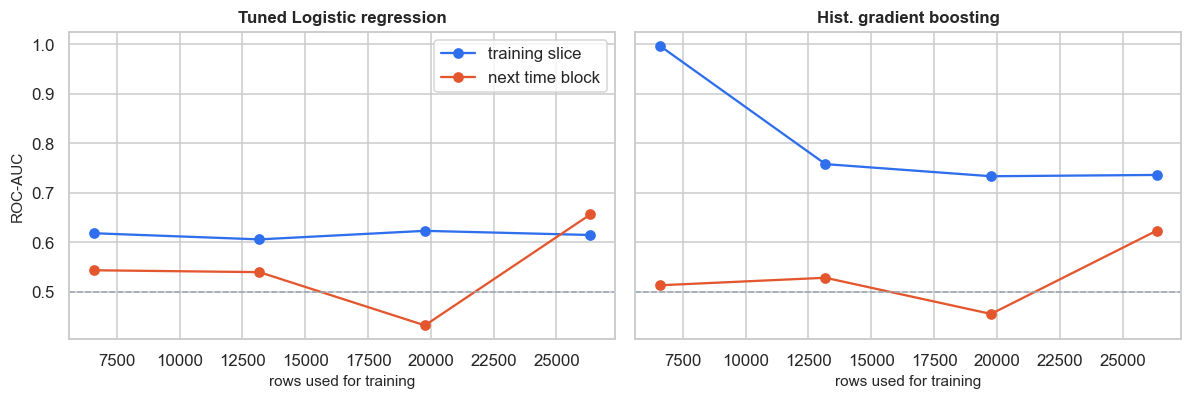

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, name in zip(ax, [TUNED_NAME, "Hist. gradient boosting"]):
    g = gap_detail[name]
    a.plot(g["train_rows"], g["train_auc"], "o-", color=C_MAIN, label="training slice")
    a.plot(g["train_rows"], g["valid_auc"], "o-", color=C_WARN, label="next time block")
    a.axhline(0.5, color=C_GREY, ls="--", lw=1); a.set_title(name); a.set_xlabel("rows used for training")
ax[0].set_ylabel("ROC-AUC"); ax[0].legend()
plt.tight_layout(); save_fig("fit_learning_curve")

**Reading.** The models fall into three groups.

* **Overfitting: random forest and boosting.** The random forest scores about 0.99 on its own training slice but about 0.52 on the next block, and boosting about 0.81 against 0.53. They memorise the past and gain nothing on the future, which fits their weaker hold-out results.
* **Little to no overfitting, but a low ceiling: logistic regression.** Training about 0.62 against validation about 0.54. The gap is small, yet even the training score is modest, so the pre-call inputs simply carry limited signal.
* **Underfitting: the MLP.** It scores only about 0.55 on its own training slice, so it barely learned the pattern with its current settings; its hold-out score should not be read as a ceiling for neural networks.

Conclusion: the weak forward-looking score is mainly a limit of the information available before the call plus drift, not an under-powered model. Adding model complexity makes the training score rise but not the validation score, which is why the simple, regularised logistic regression is the defensible choice.

---
---
# PART 6 of 8: CALL POLICY AND RECALIBRATION
*(source notebook: `06_call_policy.ipynb`)*

# 06 · From Scores to a Call Policy
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

**Question.** Given a ranked list, *whom exactly should the call centre dial*, and how many?
**Input:** the tuned pipeline (notebook 04). **Output:** `artifacts/policy_scores.npz`, `reports/tables/policy_comparison.csv`, `reports/tables/test_blocks.csv`.

The data are **non-stationary** (EDA §9): the response rate and the economy drift, and a relationship learned in one period may not hold in the next. So this notebook does three things:

1. **Diagnose** whether the ranking is stable over time (§1).
2. **Never let a calibration step re-order clients.** The ranking comes from the raw model scores and is measured **within time blocks**, which removes the "this period simply responds more" effect and isolates client-level skill.
3. **Keep probabilities usable** with rolling intercept recalibration: before scoring each block, only labels that are already known (the previous block) update the base rate.

> **Business figures are illustrative.** `CALL_BUDGET`, `COST_PER_CALL` and `VALUE_PER_SUBSCRIPTION` in `src/config.py` are placeholders (the dataset has no financial data). The *method* is the deliverable; a real bank would plug in its own numbers.

In [64]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import decile_table, rank_order, topk_metrics
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_pilot, y_pilot, X_test, y_test = (data[k] for k in ["X_train", "y_train", "X_pilot", "y_pilot", "X_test", "y_test"])
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
TUNED_NAME = json.loads((ARTIFACTS_DIR / "tuned_params.json").read_text())["name"]
test_scores = dict(np.load(ARTIFACTS_DIR / "test_scores.npz"))
s_raw = test_scores[TUNED_NAME]
BLOCK = PILOT_ROWS

Loading local file: bank-additional-full.csv


Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Is the ranking stable over time?
**(i) Stability check.** Train on the first 75% of the training period, then look *forward*: does the ranking hold on the next training block and on the test period? An AUC below 0.5 means the learned pattern **reversed** in the next period.

**(ii) Within-block skill.** Cut the test period into blocks of 500 contacts. Each block has its own base rate, so the AUC *inside* a block measures how well the model separates clients on a given day, which is the skill a campaign manager can use.

Trained on first 75% of training -> AUC on the NEXT training block: 0.626 | on the test period: 0.637
Trained on ALL training rows      -> AUC on the test period       : 0.689
(an AUC below 0.5 means the learned pattern REVERSED in the next period)



block,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
base_rate,0.084,0.092,0.080,0.108,0.130,0.258,0.384,0.348,0.336,0.404,0.468,0.540,0.524,0.564,0.462
auc,0.668,0.544,0.620,0.533,0.525,0.596,0.594,0.587,0.605,0.551,0.581,0.645,0.710,0.719,0.656
lift_at_budget,1.548,1.196,2.000,0.833,1.154,1.434,1.458,1.408,1.518,1.262,1.047,1.463,1.431,1.418,1.082


Global test ROC-AUC 0.689 | mean WITHIN-block ROC-AUC 0.609 | mean within-block lift@20% 1.35x


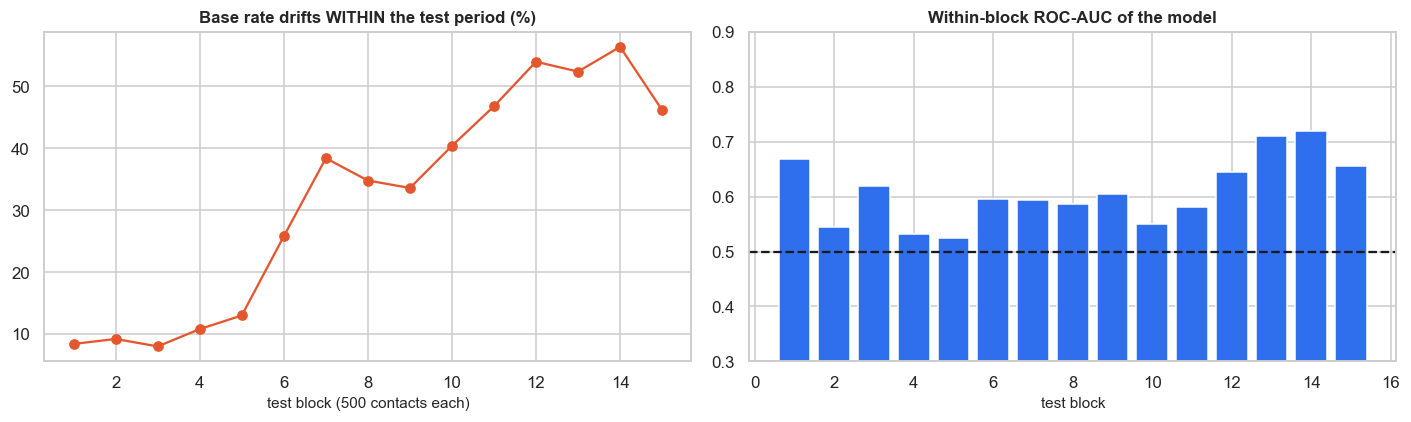

In [65]:
def valid_block(yb): return len(yb) >= BLOCK // 2 and 5 <= yb.sum() < len(yb)
def block_auc(s):
    return float(np.mean([roc_auc_score(y_test[a:a + BLOCK], s[a:a + BLOCK]) for a in range(0, len(y_test), BLOCK) if valid_block(y_test[a:a + BLOCK])]))

cut_cal = int(len(X_train) * 0.75)
fit_pipe = clone(best_pipe).fit(X_train.iloc[:cut_cal], y_train[:cut_cal])
raw_cal = fit_pipe.predict_proba(X_train.iloc[cut_cal:])[:, 1]
y_cal = y_train[cut_cal:]
s_fit75 = fit_pipe.predict_proba(X_test)[:, 1]
print(f"Trained on first 75% of training -> AUC on the NEXT training block: {roc_auc_score(y_cal, raw_cal):.3f} | on the test period: {roc_auc_score(y_test, s_fit75):.3f}")
print(f"Trained on ALL training rows      -> AUC on the test period       : {roc_auc_score(y_test, s_raw):.3f}")
print("(an AUC below 0.5 means the learned pattern REVERSED in the next period)\n")

rows = []
for i, a in enumerate(range(0, len(y_test), BLOCK)):
    yb, sb = y_test[a:a + BLOCK], s_raw[a:a + BLOCK]
    if not valid_block(yb):
        continue
    rows.append(dict(block=i + 1, base_rate=yb.mean(), auc=roc_auc_score(yb, sb), lift_at_budget=topk_metrics(yb, sb, CALL_BUDGET)[2]))
blocks = pd.DataFrame(rows).set_index("block")
display(blocks.round(3).T)
blocks.to_csv(TABLES_DIR / "test_blocks.csv")
print(f"Global test ROC-AUC {roc_auc_score(y_test, s_raw):.3f} | mean WITHIN-block ROC-AUC {blocks['auc'].mean():.3f} | mean within-block lift@{CALL_BUDGET:.0%} {blocks['lift_at_budget'].mean():.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(blocks.index, blocks["base_rate"] * 100, marker="o", color=C_WARN); ax[0].set_title("Base rate drifts WITHIN the test period (%)"); ax[0].set_xlabel("test block (500 contacts each)")
ax[1].bar(blocks.index, blocks["auc"], color=C_MAIN); ax[1].axhline(0.5, color="k", ls="--"); ax[1].set_title("Within-block ROC-AUC of the model"); ax[1].set_xlabel("test block"); ax[1].set_ylim(0.3, 0.9)
plt.tight_layout(); save_fig("policy_within_block")

**How to read it.** The global AUC mixes two skills: telling *periods* apart and telling *clients* apart within a period. Only the second is what a campaign manager can use on a given day, so the **within-block AUC and lift are the honest client-level numbers**. A big gap between the first and second figures means part of the global score is just riding the time trend. Note also how far the base rate moves inside the test period: one static base-rate estimate cannot describe it.

---
## 2 · Rolling-intercept recalibration: probabilities that follow the drift
Before scoring each block we use only labels that are already known (the previous block) to shift the score's intercept so that predictions average to the *recently observed* rate. The slope stays 1, so **the ranking is untouched**.

Intercept shift applied per block: [0.1, 0.28, 0.28, 0.22, 0.74, 0.77, 1.18, 1.69, 1.89, 1.69, -0.88, 1.28, 0.8, 1.9, 2.59, 0.83]


Platt slope fitted on the last 25% of training: +0.420  (negative = it flips the ranking)


,roc_auc_global,roc_auc_within_block,brier,mean_predicted,distinct_values
version,,,,,
Raw scores (full-train model),0.690,0.609,0.235,0.184,7376
Rolling intercept (FINAL),0.708,0.609,0.215,0.322,7514
Platt on last 25% of train (free slope),0.637,0.555,0.250,0.135,7209
"Isotonic, train-era",0.667,0.564,0.260,0.091,47


Observed test base rate 0.324 | Brier of a constant base-rate predictor: 0.2190 (a useful model must beat this)


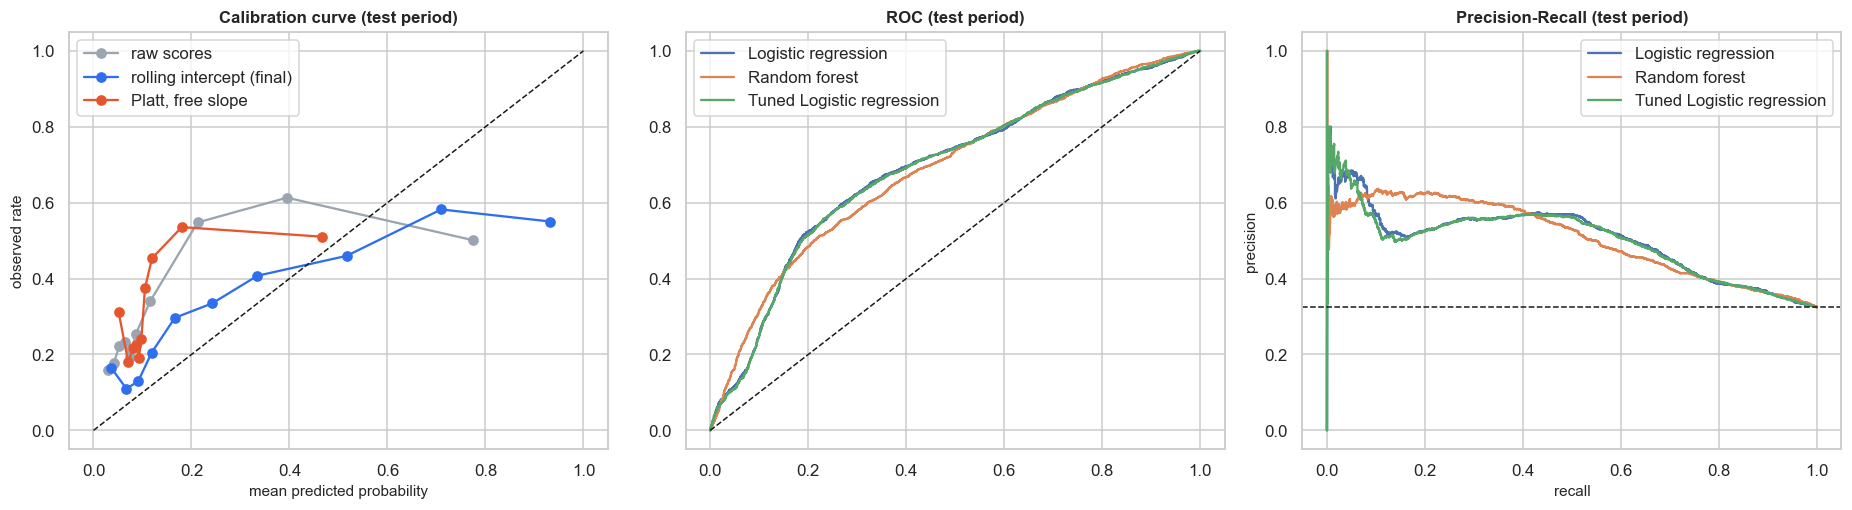

In [66]:
_clip = lambda p: np.clip(p, 1e-4, 1 - 1e-4)
def fit_intercept(p, rate):
    """Intercept b such that mean(expit(logit(p) + b)) equals the observed rate. Slope stays 1, so ranking is untouched."""
    z = logit(_clip(p)); rate = float(np.clip(rate, 0.01, 0.99))
    f = lambda b: expit(z + b).mean() - rate
    if f(-8) > 0: return -8.0
    if f(8) < 0: return 8.0
    return brentq(f, -8, 8)

s_cal = np.empty(len(X_test)); shifts = []
prev_p, prev_y = best_pipe.predict_proba(X_pilot)[:, 1], y_pilot
for a in range(0, len(X_test), BLOCK):
    b = fit_intercept(prev_p, prev_y.mean())
    s_cal[a:a + BLOCK] = expit(logit(_clip(s_raw[a:a + BLOCK])) + b); shifts.append(b)
    prev_p, prev_y = s_raw[a:a + BLOCK], y_test[a:a + BLOCK]
print("Intercept shift applied per block:", np.round(shifts, 2).tolist())

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(_clip(raw_cal)).reshape(-1, 1), y_cal)
s_platt = platt.predict_proba(logit(_clip(s_fit75)).reshape(-1, 1))[:, 1]
s_iso = CalibratedClassifierCV(clone(best_pipe), method="isotonic", cv=3).fit(X_train, y_train).predict_proba(X_test)[:, 1]
print(f"Platt slope fitted on the last 25% of training: {platt.coef_[0][0]:+.3f}  (negative = it flips the ranking)")

const_brier = y_test.mean() * (1 - y_test.mean())
rows = []
for name, s in [("Raw scores (full-train model)", s_raw), ("Rolling intercept (FINAL)", s_cal), ("Platt on last 25% of train (free slope)", s_platt), ("Isotonic, train-era", s_iso)]:
    rows.append(dict(version=name, roc_auc_global=roc_auc_score(y_test, s), roc_auc_within_block=block_auc(s), brier=brier_score_loss(y_test, s),
                     mean_predicted=s.mean(), distinct_values=len(np.unique(np.round(s, 6)))))
display(pd.DataFrame(rows).set_index("version").round(4))
print(f"Observed test base rate {y_test.mean():.3f} | Brier of a constant base-rate predictor: {const_brier:.4f} (a useful model must beat this)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for s, lab, c in [(s_raw, "raw scores", C_GREY), (s_cal, "rolling intercept (final)", C_MAIN), (s_platt, "Platt, free slope", C_WARN)]:
    fp, mp = calibration_curve(y_test, s, n_bins=10, strategy="quantile"); ax[0].plot(mp, fp, marker="o", label=lab, color=c)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("mean predicted probability"); ax[0].set_ylabel("observed rate"); ax[0].set_title("Calibration curve (test period)"); ax[0].legend()
show = [n for n in ["Logistic regression", "Random forest", TUNED_NAME] if n in test_scores]
for name in show:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name]); ax[1].plot(fpr, tpr, label=name)
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC (test period)"); ax[1].legend()
for name in show:
    p_, r_, _ = precision_recall_curve(y_test, test_scores[name]); ax[2].plot(r_, p_, label=name)
ax[2].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[2].set_title("Precision-Recall (test period)"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precision"); ax[2].legend()
plt.tight_layout(); save_fig("policy_calibration")

In [67]:
naive = np.empty(len(y_test)); prev_rate = float(y_pilot.mean())
for a in range(0, len(y_test), BLOCK):
    naive[a:a + BLOCK] = np.clip(prev_rate, 0.01, 0.99); prev_rate = y_test[a:a + BLOCK].mean()
print(f"Brier : naive rolling base rate (no model) {brier_score_loss(y_test, naive):.4f} | model + rolling intercept {brier_score_loss(y_test, s_cal):.4f} | constant oracle {const_brier:.4f}")
print(f"AUC   : naive rolling base rate {roc_auc_score(y_test, naive):.4f} (pure 'which period' signal) | model + rolling intercept {roc_auc_score(y_test, s_cal):.4f} | within-block model skill {block_auc(s_cal):.4f}")

Brier : naive rolling base rate (no model) 0.1928 | model + rolling intercept 0.2153 | constant oracle 0.2190
AUC   : naive rolling base rate 0.7128 (pure 'which period' signal) | model + rolling intercept 0.7081 | within-block model skill 0.6089


**Reading.** Part of the global AUC and Brier improvement from rolling recalibration is just *tracking the period* (the naive line gets that for free). The model's own contribution is the **within-block** AUC: report that as client-level skill and the rest as period-level tracking.

**Why not Platt or isotonic fitted in the training era?** Both learn a mapping from *one* period and apply it to another. Isotonic collapses most future clients onto a handful of steps (see `distinct_values`). Platt with a free slope is worse here as well: it is fitted on a model refit on part of the training period, scores the later period lower (ROC-AUC about 0.64 against 0.69), and would **flip the ranking** if the scores were negatively related to the outcome in its calibration window (the slope printed above is positive, +0.42, so it did not flip here). Rolling intercept recalibration only moves the base rate and can never re-order clients within a block.

---
## 3 · Gain and lift (ranking quality from the raw scores)

,clients,subscribers,response_rate,lift,cum_capture
decile,,,,,
1,774,388,0.501,1.547,0.155
2,774,474,0.612,1.890,0.344
3,773,424,0.549,1.693,0.513
4,774,263,0.340,1.049,0.618
5,773,197,0.255,0.786,0.696
6,774,149,0.193,0.594,0.756
7,774,180,0.233,0.718,0.828
8,773,171,0.221,0.683,0.896
9,774,138,0.178,0.550,0.951


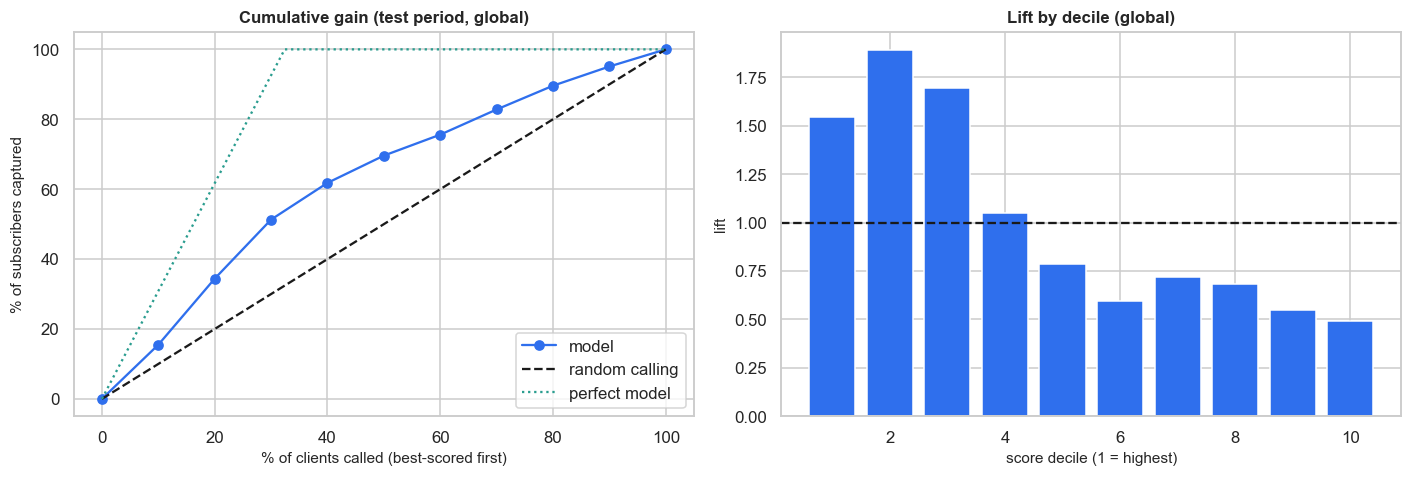

In [68]:
dt = decile_table(y_test, s_raw)
display(dt)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x_ = np.r_[0, dt.index * 10]; g_ = np.r_[0, dt["cum_capture"].values * 100]
ax[0].plot(x_, g_, marker="o", color=C_MAIN, label="model"); ax[0].plot([0, 100], [0, 100], "k--", label="random calling")
ax[0].plot([0, y_test.mean() * 100, 100], [0, 100, 100], color=C_OK, ls=":", label="perfect model")
ax[0].set_xlabel("% of clients called (best-scored first)"); ax[0].set_ylabel("% of subscribers captured"); ax[0].set_title("Cumulative gain (test period, global)"); ax[0].legend()
ax[1].bar(dt.index, dt["lift"], color=C_MAIN); ax[1].axhline(1, color="k", ls="--"); ax[1].set_xlabel("score decile (1 = highest)"); ax[1].set_ylabel("lift"); ax[1].set_title("Lift by decile (global)")
plt.tight_layout(); save_fig("policy_gain_lift")

**Sanity check.** Lift should be above 1 in the first deciles and fall towards the last. This *global* view includes the period effect; the within-block lift from section 1 is the stricter number.

---
## 4 · Profit-maximising call policy
If a call costs *c* and a subscription is worth *v*, a call is worth making when `p * v > c`, so the break-even probability is **c / v**, valid only if *p* matches the **current** base rate (hence the rolling recalibration). For a **fixed call capacity** the natural policy is rank-based: each block, call the top `CALL_BUDGET` share by score. The fair baseline is **random calling at the same volume**.

,called_pct,precision,subscribers_captured_pct,profit_per_client
policy,,,,
Call nobody,0.000,NaN,0.000,0.000
Call everyone (no model),100.000,0.324,100.000,2.241
Model: top 20% of each block (fixed capacity),19.997,0.436,26.925,0.673
Random: 20% of clients (expected),20.000,0.324,20.000,0.448
Model: c/v=0.10 on raw scores (no recalibration),37.991,0.509,59.673,1.554
Model: c/v=0.10 on rolling-recalibrated probabilities,71.161,0.400,87.914,2.137
Oracle threshold 0.01 (NOT deployable),99.871,0.324,99.801,2.236


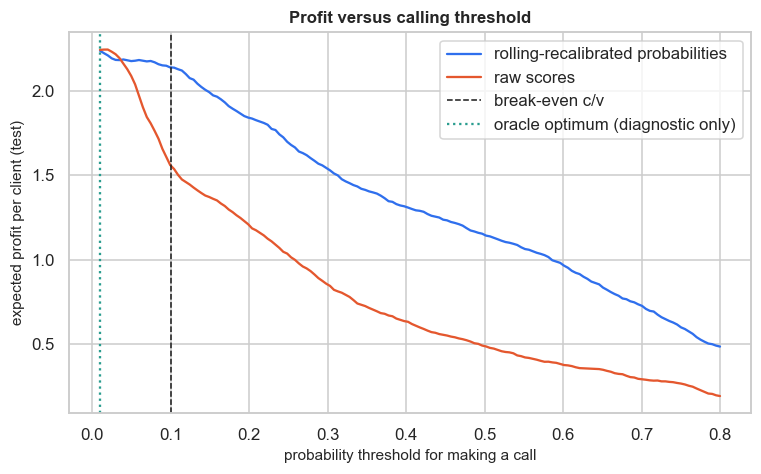

In [69]:
grid = np.linspace(0.01, 0.80, 160)
thr_theory = COST_PER_CALL / VALUE_PER_SUBSCRIPTION

def profit_per_client(y_true, score, thr):
    called = score >= thr
    return (VALUE_PER_SUBSCRIPTION * y_true[called].sum() - COST_PER_CALL * called.sum()) / len(y_true)
def policy_row(name, mask):
    n_called = int(mask.sum()); subs = int(y_test[mask].sum()) if n_called else 0
    return dict(policy=name, called_pct=100 * n_called / len(y_test), precision=subs / n_called if n_called else np.nan,
                subscribers_captured_pct=100 * subs / y_test.sum(), profit_per_client=(VALUE_PER_SUBSCRIPTION * subs - COST_PER_CALL * n_called) / len(y_test))
def per_block_topk_mask(score, frac):
    mask = np.zeros(len(score), bool)
    for a in range(0, len(score), BLOCK):
        idx = np.arange(a, min(a + BLOCK, len(score))); k = max(1, int(round(frac * len(idx))))
        mask[idx[rank_order(score[idx])[:k]]] = True
    return mask

budget_mask = per_block_topk_mask(s_raw, CALL_BUDGET)
test_profit = np.array([profit_per_client(y_test, s_cal, t) for t in grid])
thr_oracle = float(grid[test_profit.argmax()])
base = y_test.mean()
P_NOBODY, P_ALL = "Call nobody", "Call everyone (no model)"
P_BUDGET = f"Model: top {CALL_BUDGET:.0%} of each block (fixed capacity)"
P_RANDOM = f"Random: {CALL_BUDGET:.0%} of clients (expected)"
P_STALE = f"Model: c/v={thr_theory:.2f} on raw scores (no recalibration)"
P_FINAL = f"Model: c/v={thr_theory:.2f} on rolling-recalibrated probabilities"
P_ORACLE = f"Oracle threshold {thr_oracle:.2f} (NOT deployable)"
policies = pd.DataFrame([
    policy_row(P_NOBODY, np.zeros(len(y_test), bool)), policy_row(P_ALL, np.ones(len(y_test), bool)), policy_row(P_BUDGET, budget_mask),
    dict(policy=P_RANDOM, called_pct=100 * CALL_BUDGET, precision=base, subscribers_captured_pct=100 * CALL_BUDGET,
         profit_per_client=CALL_BUDGET * (VALUE_PER_SUBSCRIPTION * base - COST_PER_CALL)),
    policy_row(P_STALE, s_raw >= thr_theory), policy_row(P_FINAL, s_cal >= thr_theory), policy_row(P_ORACLE, s_cal >= thr_oracle),
]).set_index("policy").round(3)
display(policies)
policies.to_csv(TABLES_DIR / "policy_comparison.csv")
np.savez(ARTIFACTS_DIR / "policy_scores.npz", s_raw=s_raw, s_cal=s_cal, budget_mask=budget_mask)
json.dump({"P_BUDGET": P_BUDGET, "P_RANDOM": P_RANDOM, "P_ALL": P_ALL, "thr_theory": thr_theory}, open(ARTIFACTS_DIR / "policy_labels.json", "w"))

plt.figure(figsize=(8, 4.5))
plt.plot(grid, test_profit, label="rolling-recalibrated probabilities", color=C_MAIN)
plt.plot(grid, [profit_per_client(y_test, s_raw, t) for t in grid], label="raw scores", color=C_WARN)
plt.axvline(thr_theory, color="k", ls="--", lw=1, label="break-even c/v"); plt.axvline(thr_oracle, color=C_OK, ls=":", label="oracle optimum (diagnostic only)")
plt.xlabel("probability threshold for making a call"); plt.ylabel("expected profit per client (test)"); plt.title("Profit versus calling threshold"); plt.legend()
save_fig("policy_profit_curve")

**Sensitivity matters.** Cost and value are assumptions, and `c / v` must be compared with the base rate: if it is *below* the base rate, calling everyone is already profitable and a model only helps when call capacity is capped. The table shows how the picture changes with the value of a subscription.

In [70]:
rows = []
for v in [2, 3, 5, 10, 20]:
    thr = COST_PER_CALL / v; mask = s_cal >= thr
    n_called, subs = int(mask.sum()), int(y_test[mask].sum())
    rows.append(dict(value_per_subscription=v, break_even_prob=thr, called_pct=100 * mask.mean(), precision=subs / n_called if n_called else np.nan,
                     model_profit_per_client=(v * subs - COST_PER_CALL * n_called) / len(y_test), call_everyone_profit=v * y_test.mean() - COST_PER_CALL))
display(pd.DataFrame(rows).set_index("value_per_subscription").round(3))
print(f"Train base rate {y_train.mean():.3f} vs test base rate {y_test.mean():.3f}.")

,break_even_prob,called_pct,precision,model_profit_per_client,call_everyone_profit
value_per_subscription,,,,,
2,0.500,25.711,0.545,0.023,-0.352
3,0.333,34.540,0.517,0.191,-0.028
5,0.200,50.271,0.466,0.668,0.620
10,0.100,71.161,0.400,2.137,2.241
20,0.050,91.313,0.338,5.263,5.481


Train base rate 0.064 vs test base rate 0.324.


---
## 5 · Operating-point report: validation-tuned cut-offs, F1 / precision / recall and confusion matrices
The proposal promised **threshold tuning on validation data** and the classic classification metrics. Sections 2-4 answer the business question with a profit-based cut-off; this section adds the textbook version for comparison.

**Design (chronological throughout):** fit on the first 75% of the training period, choose cut-offs on the remaining 25% (**validation**), then apply the *same fitted model and fixed cut-offs* to the later test period. Candidate rules: max F1, max F2 (recall weighted twice as much as precision), "highest cut-off that still reaches 70% recall", and the break-even `c / v`, compared with a **static top-20% cut-off** and the **rank-based top 20% of each block**. The static rules show what happens when a score threshold learned in one period meets a drifting base rate.

,threshold,val_called_pct,test_called_pct,val_f1,test_precision,test_recall,test_f1,test_f2,calls_per_subscriber,test_profit_per_client
policy,,,,,,,,,,
Max F1 (validation),0.099,23.157,20.747,0.267,0.518,0.331,0.404,0.357,1.931,0.867
"Max F2, recall-weighted (validation)",0.073,49.047,27.637,0.240,0.506,0.431,0.465,0.444,1.978,1.121
Recall >= 70% (validation),0.058,56.515,35.315,0.230,0.485,0.529,0.506,0.519,2.062,1.360
Break-even c/v = 0.10,0.100,21.712,20.450,0.266,0.520,0.328,0.402,0.354,1.925,0.858
Static top-20% cut-off (validation),0.102,20.000,20.075,0.263,0.522,0.323,0.400,0.350,1.915,0.848
Rank-based top-20% of each block,NaN,20.000,19.997,NaN,0.403,0.249,0.307,0.269,2.483,0.605


Test base rate 32.407% | validation base rate 11.075%. A big gap between val_called_pct and test_called_pct means the cut-off did not transfer across periods.


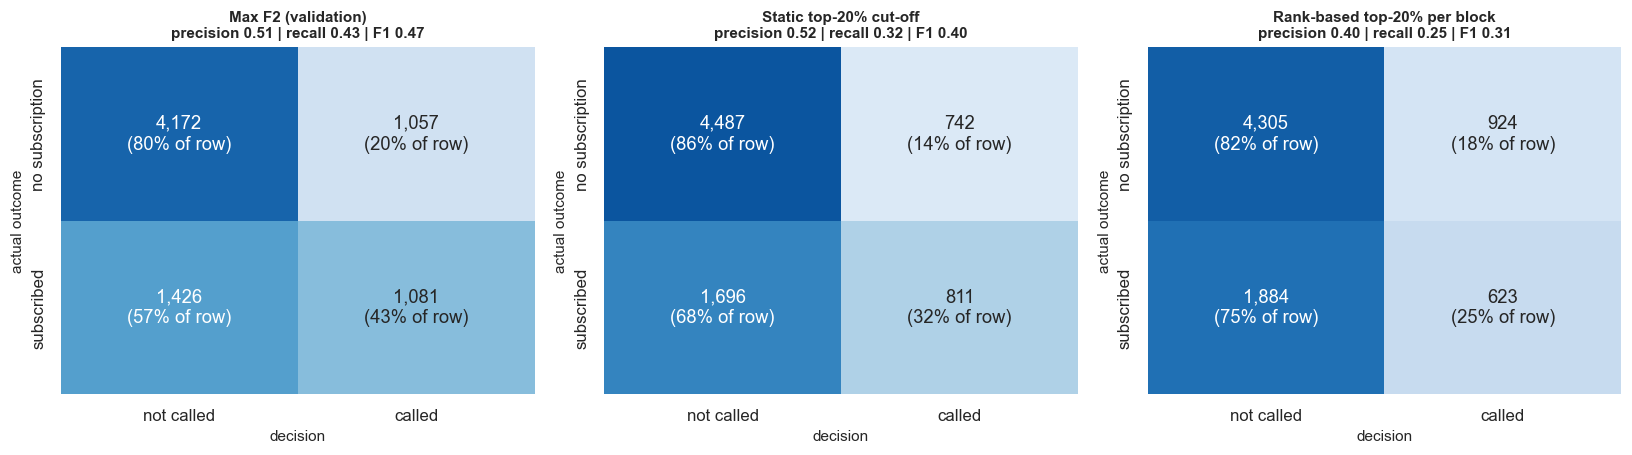

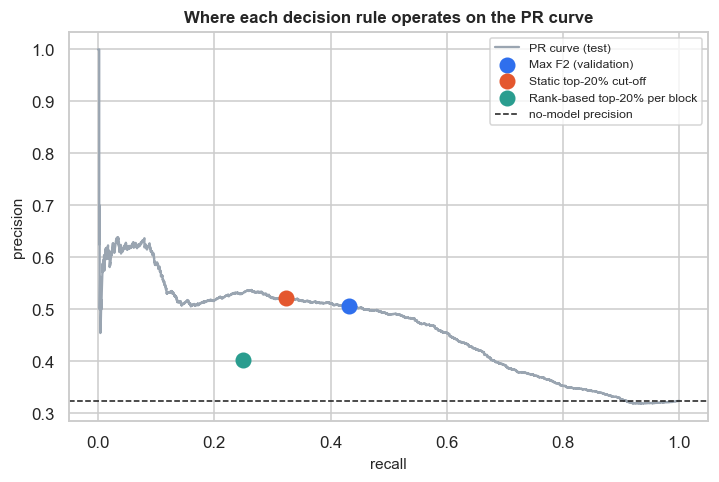

Best test F2 among the rules above: 'Recall >= 70% (validation)' -> 2.1 calls per subscriber won.


In [71]:
op_cut = int(len(X_train) * 0.75)
op_model = clone(best_pipe).fit(X_train.iloc[:op_cut], y_train[:op_cut])
op_vs, op_vy = op_model.predict_proba(X_train.iloc[op_cut:])[:, 1], y_train[op_cut:]
op_ts = op_model.predict_proba(X_test)[:, 1]

def op_metrics(y_true, called):
    tp = int((called & (y_true == 1)).sum()); fp = int((called & (y_true == 0)).sum()); fn = int((~called & (y_true == 1)).sum()); tn = int((~called & (y_true == 0)).sum())
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(called_pct=100 * called.mean(), precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-12), f2=5 * prec * rec / max(4 * prec + rec, 1e-12),
                calls_per_subscriber=(tp + fp) / max(tp, 1), tp=tp, fp=fp, fn=fn, tn=tn)

_cand = np.unique(np.quantile(op_vs, np.linspace(0.40, 0.995, 240)))
_v = pd.DataFrame([op_metrics(op_vy, op_vs >= t) for t in _cand], index=_cand)
op_thr = {
    "Max F1 (validation)": float(_v["f1"].idxmax()),
    "Max F2, recall-weighted (validation)": float(_v["f2"].idxmax()),
    "Recall >= 70% (validation)": float(_v.index[_v["recall"] >= 0.70].max()) if (_v["recall"] >= 0.70).any() else float(_v.index.min()),
    f"Break-even c/v = {thr_theory:.2f}": thr_theory,
    f"Static top-{CALL_BUDGET:.0%} cut-off (validation)": float(np.quantile(op_vs, 1 - CALL_BUDGET)),
}
rows = []
for name, t in op_thr.items():
    mv, mt = op_metrics(op_vy, op_vs >= t), op_metrics(y_test, op_ts >= t)
    rows.append(dict(policy=name, threshold=t, val_called_pct=mv["called_pct"], test_called_pct=mt["called_pct"], val_f1=mv["f1"], test_precision=mt["precision"],
                     test_recall=mt["recall"], test_f1=mt["f1"], test_f2=mt["f2"], calls_per_subscriber=mt["calls_per_subscriber"],
                     test_profit_per_client=(VALUE_PER_SUBSCRIPTION * mt["tp"] - COST_PER_CALL * (mt["tp"] + mt["fp"])) / len(y_test)))
_mt = op_metrics(y_test, per_block_topk_mask(op_ts, CALL_BUDGET))
rows.append(dict(policy=f"Rank-based top-{CALL_BUDGET:.0%} of each block", threshold=np.nan, val_called_pct=100 * CALL_BUDGET, test_called_pct=_mt["called_pct"], val_f1=np.nan,
                 test_precision=_mt["precision"], test_recall=_mt["recall"], test_f1=_mt["f1"], test_f2=_mt["f2"], calls_per_subscriber=_mt["calls_per_subscriber"],
                 test_profit_per_client=(VALUE_PER_SUBSCRIPTION * _mt["tp"] - COST_PER_CALL * (_mt["tp"] + _mt["fp"])) / len(y_test)))
op_table = pd.DataFrame(rows).set_index("policy")
display(op_table.round(3))
op_table.to_csv(TABLES_DIR / "operating_points.csv")
print(f"Test base rate {y_test.mean():.3%} | validation base rate {op_vy.mean():.3%}. A big gap between val_called_pct and test_called_pct means the cut-off did not transfer across periods.")

show_rules = {"Max F2 (validation)": op_ts >= op_thr["Max F2, recall-weighted (validation)"],
              f"Static top-{CALL_BUDGET:.0%} cut-off": op_ts >= op_thr[f"Static top-{CALL_BUDGET:.0%} cut-off (validation)"],
              f"Rank-based top-{CALL_BUDGET:.0%} per block": per_block_topk_mask(op_ts, CALL_BUDGET)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a_, (name, called) in zip(ax, show_rules.items()):
    cm = confusion_matrix(y_test, called.astype(int), labels=[0, 1]); pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(pct, annot=np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.0%} of row)" for j in range(2)] for i in range(2)]), fmt="", cmap="Blues", cbar=False, ax=a_, vmin=0, vmax=1,
                xticklabels=["not called", "called"], yticklabels=["no subscription", "subscribed"])
    m_ = op_metrics(y_test, called); a_.set_title(f"{name}\nprecision {m_['precision']:.2f} | recall {m_['recall']:.2f} | F1 {m_['f1']:.2f}", fontsize=10); a_.set_xlabel("decision"); a_.set_ylabel("actual outcome")
plt.tight_layout(); save_fig("policy_confusion_matrices")

p_, r_, _ = precision_recall_curve(y_test, op_ts)
plt.figure(figsize=(7.5, 4.6)); plt.plot(r_, p_, color=C_GREY, label="PR curve (test)")
for (name, called), c in zip(show_rules.items(), [C_MAIN, C_WARN, C_OK]):
    m_ = op_metrics(y_test, called); plt.scatter(m_["recall"], m_["precision"], s=90, color=c, label=name, zorder=3)
plt.axhline(y_test.mean(), color="k", ls="--", lw=1, label="no-model precision"); plt.xlabel("recall"); plt.ylabel("precision")
plt.title("Where each decision rule operates on the PR curve"); plt.legend(fontsize=8)
save_fig("policy_operating_points")
_best = op_table["test_f2"].idxmax()
print(f"Best test F2 among the rules above: '{_best}' -> {op_table.loc[_best, 'calls_per_subscriber']:.1f} calls per subscriber won.")

**How to read it.** A *static* score threshold tuned on validation fixes a probability, not a call volume. If the response rate in the test period differs from validation (it does, see section 1), the same threshold selects a very different share of clients, so called percentage, precision and recall all move together. The **rank-based** rule fixes the *call volume* instead and is therefore robust to that shift; it is the policy recommended in notebook 08. Use F2 or the recall-constrained rule if the bank values each missed subscriber more than each wasted call, use the break-even rule when the economics are known, and report `calls_per_subscriber` to the stakeholder because it translates a confusion matrix into campaign effort. Remember that the cost and value figures are illustrative assumptions.

---
---
# PART 7 of 8: SEGMENTS AND RESPONSIBLE AI
*(source notebook: `07_segments_and_responsible_ai.ipynb`)*

# 07 · Segments, Explanations and Responsible AI
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

**Questions.** (1) Can client-level scores be turned into **segment-level call priorities** a campaign manager can act on (secondary lens)? (2) **What drives** the ranking? (3) Does the model **treat groups fairly**, and what would excluding sensitive attributes cost?
**Input:** tuned pipeline (notebook 04), `artifacts/policy_scores.npz` (notebook 06). **Nothing here changes the model**; it explains and audits it.

In [72]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import *
from src.data.prepare import load_modelling_data
from src.features.preprocessing import build_pipeline, add_features, CAT_COLS
from src.models.candidates import build_main_models
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train, X_test, y_test = data["X_train"], data["y_train"], data["X_test"], data["y_test"]
best_pipe = joblib.load(ARTIFACTS_DIR / "tuned_pipeline.joblib")
pol = np.load(ARTIFACTS_DIR / "policy_scores.npz")
s_raw, s_cal, budget_mask = pol["s_raw"], pol["s_cal"], pol["budget_mask"]
thr_theory = json.loads((ARTIFACTS_DIR / "policy_labels.json").read_text())["thr_theory"]
models = build_main_models()

Loading local file: bank-additional-full.csv


Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Secondary lens: segment prioritisation
Client-level scores are precise but hard to operationalise: scripts, staffing and offers are designed per **segment**. We cluster **client-profile attributes only** (age, job, marital status, education, credit flags, loans), learned on the **training period**, then rank the segments by the model's average score on the **test period**. The segments exist solely to support the call-priority decision; they are not a separate analysis.

In [73]:
CLIENT_CAT = ["job", "marital", "education", "default", "housing", "loan"]
seg_prep = ColumnTransformer([("n", StandardScaler(), ["age"]), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CLIENT_CAT)])
Z_train = seg_prep.fit_transform(X_train)
sample = np.random.RandomState(SEED).choice(len(Z_train), min(6000, len(Z_train)), replace=False)
sil = {}
for k in range(3, 8):
    km = KMeans(k, n_init=5, random_state=SEED).fit(Z_train)
    sil[k] = silhouette_score(Z_train[sample], km.labels_[sample])
best_k = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", best_k)

km = KMeans(best_k, n_init=10, random_state=SEED).fit(Z_train)
seg_test = km.predict(seg_prep.transform(X_test))
prof = []
for s in range(best_k):
    m = seg_test == s; sub = X_test[m]
    prof.append(dict(segment=s, clients_pct=100 * m.mean(), median_age=sub["age"].median(), top_job=sub["job"].mode().iat[0],
                     pct_housing_loan=100 * (sub["housing"] == "yes").mean(), pct_university=100 * (sub["education"] == "university.degree").mean(),
                     actual_response_pct=100 * y_test[m].mean(), mean_model_score_pct=100 * s_cal[m].mean(), pct_in_budget_list=100 * budget_mask[m].mean()))
seg_profile = pd.DataFrame(prof).set_index("segment").sort_values("mean_model_score_pct", ascending=False).round(1)
seg_profile["call_priority"] = range(1, best_k + 1)
display(seg_profile)
seg_profile.to_csv(TABLES_DIR / "segment_profile.csv")

Silhouette by k: {3: 0.129, 4: 0.124, 5: 0.119, 6: 0.125, 7: 0.123} -> k = 3


,clients_pct,median_age,top_job,pct_housing_loan,pct_university,actual_response_pct,mean_model_score_pct,pct_in_budget_list,call_priority
segment,,,,,,,,,
2,30.900,56.000,retired,56.100,26.800,37.400,37.000,17.300,1
1,29.000,32.000,admin.,0.000,39.100,31.200,30.400,21.700,2
0,40.000,32.000,admin.,95.900,38.500,29.400,29.700,20.800,3


**Caution when reading.** Segments built from client attributes explain only part of the variation; most predictive signal comes from contact history and channel (notebook 01 §6-7). Treat segments as **priority hints for scripting and staffing**, not as a replacement for client-level scores. A silhouette score close to zero means the segments overlap heavily: say so rather than over-interpreting them. On the real data the silhouette is only about 0.12-0.13 and the three segments are separated mainly by housing-loan status and age (older, retired clients versus younger clients with and without a housing loan), so present them as rough priority hints. In the report, name the highest-priority segment in plain business language using the `top_job`, `median_age` and `actual_response_pct` columns.

---
## 2 · What drives the ranking?
Two views of the same question: **permutation importance** (how much does PR-AUC drop on the later period when one raw column is shuffled? honest about the future) and **logistic-regression coefficients** (direction of the effect on a transparent model). Attributes that rank high in both are the most defensible drivers to present. *Association in the model, not causation: a feature that raises the score does not mean changing it would make a client subscribe.*

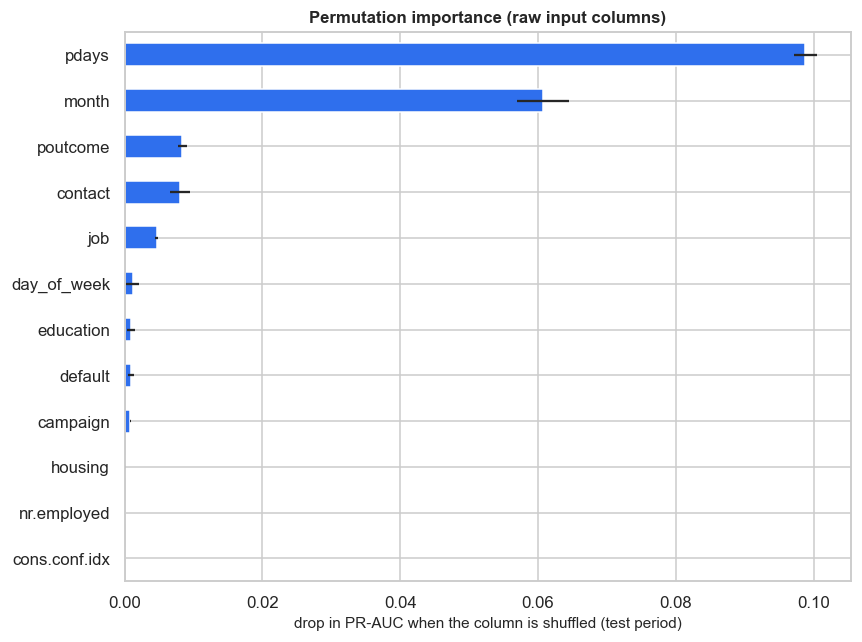

,LR coefficient (standardised)
cat__month_aug,-1.080
cat__month_nov,-0.994
cat__month_jul,-0.853
cat__month_may,-0.852
cat__month_jun,-0.609
num__campaign,-0.314
cat__poutcome_nonexistent,0.306
cat__contact_cellular,0.369
cat__job_retired,0.460
cat__job_student,0.478


In [74]:
final_fit = clone(best_pipe).fit(X_train, y_train)
pi = permutation_importance(final_fit, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).drop("duration", errors="ignore").sort_values()
err = pd.Series(pi.importances_std, index=X_test.columns).reindex(imp.index)
plt.figure(figsize=(8, 6)); imp.tail(12).plot.barh(xerr=err.tail(12), color=C_MAIN)
plt.xlabel("drop in PR-AUC when the column is shuffled (test period)"); plt.title("Permutation importance (raw input columns)")
plt.tight_layout(); save_fig("explain_permutation_importance")

lr_fit = clone(models["Logistic regression"]).fit(X_train, y_train)
coefs = pd.Series(lr_fit.named_steps["model"].coef_[0], index=lr_fit.named_steps["prep"].get_feature_names_out()).sort_values()
display(pd.concat([coefs.head(6), coefs.tail(6)]).rename("LR coefficient (standardised)").round(3).to_frame())

### 2b · Exact per-client explanations for a boosted model (TreeSHAP)
The proposal lists the interpretability of boosted models (XGBoost, LightGBM) as a limitation. It can be addressed rather than just acknowledged: LightGBM computes exact **TreeSHAP** contributions natively (`pred_contrib=True`), so no extra package is needed. For every client the contributions of all features plus a bias term **add up exactly** to the model's score, which gives a campaign manager an auditable answer to *"why is this client near the top of the call list?"* One-hot columns are summed back to the original attribute so the explanation reads in business terms. This explains a **challenger boosted model**, not the tuned model above.

OK: contributions + bias reproduce the model score exactly for all 3,000 sampled clients.


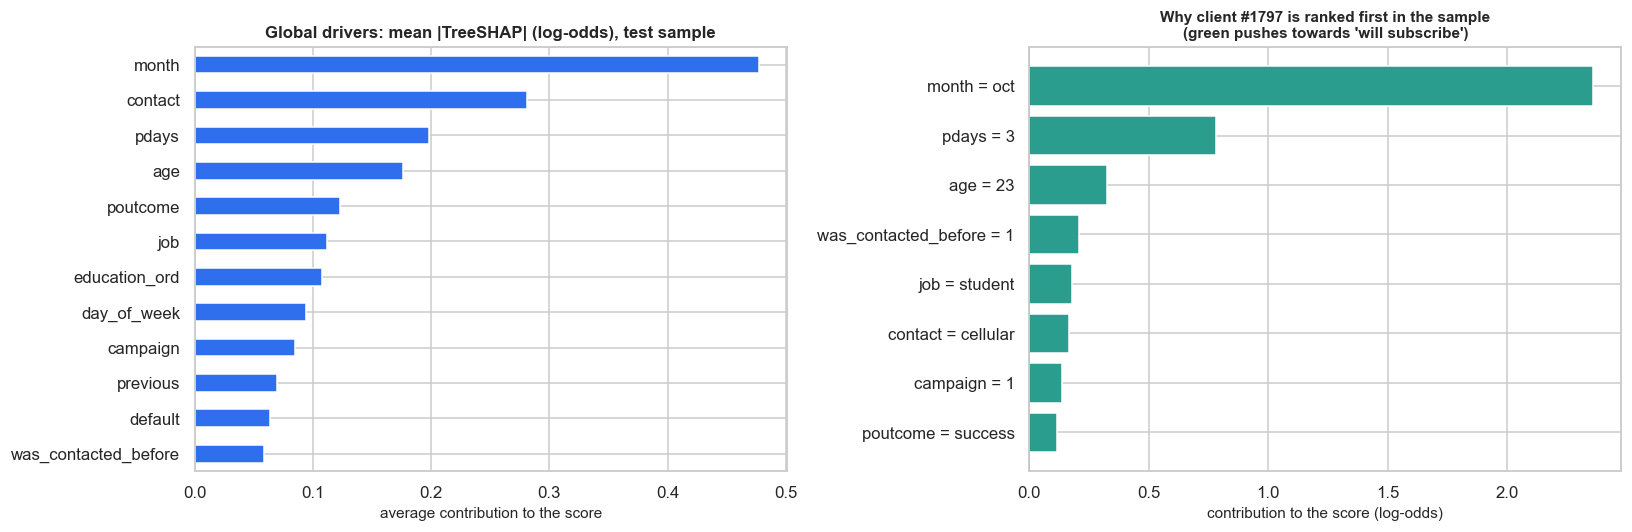

Spearman rank agreement between permutation importance (tuned model) and mean |TreeSHAP| (LightGBM) on 13 shared attributes: +0.75 (p = 0.003)


In [75]:
import lightgbm as lgb
shap_pipe = build_pipeline(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                                              colsample_bytree=0.8, class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1), scale=False).fit(X_train, y_train)
shap_idx = np.random.RandomState(SEED).choice(len(X_test), min(3000, len(X_test)), replace=False)
shap_X = X_test.iloc[shap_idx].reset_index(drop=True)
shap_Z = shap_pipe[:-1].transform(shap_X)
shap_names = shap_pipe.named_steps["prep"].get_feature_names_out()
booster = shap_pipe.named_steps["model"].booster_
contrib = booster.predict(shap_Z, pred_contrib=True)
margin = booster.predict(shap_Z, raw_score=True)
assert np.allclose(contrib.sum(axis=1), margin, atol=1e-4), "TreeSHAP contributions must add up to the model score"
print(f"OK: contributions + bias reproduce the model score exactly for all {len(margin):,} sampled clients.")

def raw_feature(name):
    kind, rest = name.split("__", 1)
    if kind == "cat":
        return next((c for c in sorted(CAT_COLS, key=len, reverse=True) if rest.startswith(c + "_")), rest)
    return rest.replace("missingindicator_", "")
shap_raw = np.array([raw_feature(n) for n in shap_names])
shap_by_feature = pd.DataFrame(contrib[:, :-1], columns=shap_names).T.groupby(shap_raw).sum().T
global_imp = shap_by_feature.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
global_imp.head(12)[::-1].plot.barh(ax=ax[0], color=C_MAIN); ax[0].set_title("Global drivers: mean |TreeSHAP| (log-odds), test sample"); ax[0].set_xlabel("average contribution to the score")
top_i = int(np.argmax(margin)); fe_row = add_features(shap_X.iloc[[top_i]]).iloc[0]
loc = shap_by_feature.iloc[top_i]; loc = loc.reindex(loc.abs().sort_values(ascending=False).index).head(8)[::-1]
labels = [f"{k} = {fe_row[k] if k in fe_row.index else ''}" for k in loc.index]
ax[1].barh(labels, loc.values, color=[C_OK if v > 0 else C_WARN for v in loc.values]); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title(f"Why client #{top_i} is ranked first in the sample\n(green pushes towards 'will subscribe')", fontsize=10); ax[1].set_xlabel("contribution to the score (log-odds)")
plt.tight_layout(); save_fig("explain_treeshap")

common = [f for f in imp.index if f in global_imp.index]
if len(common) >= 4:
    rho, pval = spearmanr(imp.reindex(common), global_imp.reindex(common))
    print(f"Spearman rank agreement between permutation importance (tuned model) and mean |TreeSHAP| (LightGBM) on {len(common)} shared attributes: {rho:+.2f} (p = {pval:.3f})")

**How to read it.** The left panel ranks attributes by average absolute influence; attributes near the top here **and** in the permutation view are the most defensible drivers to present. The right panel is a *local* explanation: each bar is one attribute's push on this client's score, and the bars plus the bias sum to the score. This is the kind of evidence a compliance reviewer or campaign manager can audit client by client.

---
## 3 · Responsible AI: fairness audit and the cost of excluding sensitive features
A bank deciding whom to contact must not systematically deprioritise people on the basis of sensitive attributes. We (a) audit performance and selection rates across **age bands** and **marital status** at the break-even threshold, and (b) measure how much predictive power would be sacrificed by removing those attributes.

In [76]:
def group_report(y_true, score, thr, groups):
    rows = []
    for g in pd.Series(groups).dropna().unique():
        m = np.asarray(groups) == g
        if m.sum() < 50 or y_true[m].sum() < 5:
            continue
        sel = score[m] >= thr
        rows.append(dict(group=g, n=int(m.sum()), base_rate=y_true[m].mean(), auc=roc_auc_score(y_true[m], score[m]), selection_rate=sel.mean(),
                         recall=(sel & (y_true[m] == 1)).sum() / y_true[m].sum()))
    return pd.DataFrame(rows).set_index("group").round(3)

age_band = pd.cut(X_test["age"], [0, 29, 45, 60, 120], labels=["<30", "30-45", "46-60", ">60"]).astype(str)
print("By age band (threshold = c/v):"); display(group_report(y_test, s_cal, thr_theory, age_band.values))
print("By marital status:"); display(group_report(y_test, s_cal, thr_theory, X_test["marital"].values))

excl = ("age", "marital")
no_sens = build_pipeline(clone(best_pipe.named_steps["model"]), scale=isinstance(best_pipe.named_steps["model"], LogisticRegression), exclude=excl).fit(X_train, y_train)
s_ns = no_sens.predict_proba(X_test)[:, 1]
cost = pd.DataFrame({"with age + marital": [average_precision_score(y_test, s_raw), roc_auc_score(y_test, s_raw)],
                     "without": [average_precision_score(y_test, s_ns), roc_auc_score(y_test, s_ns)]}, index=["test PR-AUC", "test ROC-AUC"]).round(4)
display(cost)
cost.to_csv(TABLES_DIR / "fairness_cost_of_exclusion.csv")

By age band (threshold = c/v):


,n,base_rate,auc,selection_rate,recall
group,,,,,
<30,1845,0.315,0.717,0.739,0.897
30-45,3611,0.290,0.731,0.649,0.854
46-60,1514,0.345,0.689,0.723,0.885
>60,766,0.465,0.551,0.919,0.916


By marital status:


,n,base_rate,auc,selection_rate,recall
group,,,,,
single,3000,0.316,0.716,0.756,0.904
married,3927,0.332,0.702,0.694,0.867
divorced,794,0.314,0.713,0.625,0.843


,with age + marital,without
test PR-AUC,0.499,0.498
test ROC-AUC,0.690,0.690


**Discussion points for the report.**
1. Large gaps in *selection rate* are not automatically unfair (base rates differ between groups), but a model that selects a group far *less* than its true response rate justifies deserves review.
2. If excluding `age` and `marital` costs little accuracy (see the table), the **responsible default is to exclude them**; if it costs a lot, the group should state that trade-off openly.
3. Telemarketing financial products to elderly or vulnerable clients carries **conduct risk**, so the score should support a human campaign manager, not replace their judgement.
4. Fairness is audited on only two attributes and on one period; this is a screening check, not a certification.

---
---
# PART 8 of 8: BUSINESS INTERPRETATION
*(source notebook: `08_business_interpretation.ipynb`)*

# 08 · Business Interpretation, Recommendation and Reproducibility
### IT3091 Machine Learning · Group 2026-AI-42 · Evaluation, recommendation & documentation lead

This notebook computes **no new model**. It reads the tables saved by notebooks 02-07, prints the key numbers for the report, and records the recommendation, limitations, decision log, AI-use declaration and reproducibility details. Every number below is read from a saved result, so the write-up cannot drift from the evidence.

In [77]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
while ROOT.name in ["notebooks", "Full Notebook"] or not (ROOT / "src").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json, platform
import numpy as np, pandas as pd
from IPython.display import display
import sklearn

from src.config import *
from src.data.loading import fingerprint
from src.data.prepare import load_modelling_data

pd.set_option("display.max_columns", 60, "display.width", 170, "display.max_colwidth", 140)
data = load_modelling_data()
y_test, y_train = data["y_test"], data["y_train"]
T = lambda name, **kw: pd.read_csv(TABLES_DIR / name, **kw)
params = json.loads((ARTIFACTS_DIR / "tuned_params.json").read_text())
labels = json.loads((ARTIFACTS_DIR / "policy_labels.json").read_text())
TUNED_NAME = params["name"]

Loading local file: bank-additional-full.csv


Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)


---
## 1 · Key numbers for the report
*Test = the later time period, used once for the final evaluation. Cost and value figures are illustrative.*

In [78]:
holdout = T("holdout_results.csv", index_col=0)
policies = T("policy_comparison.csv", index_col=0)
blocks = T("test_blocks.csv", index_col=0)
leak = T("preprocessing_leakage_duration.csv", index_col=0)
split_opt = T("split_optimism.csv", index_col=0)

best_row = holdout.loc[TUNED_NAME]
top, rnd, allc = policies.loc[labels["P_BUDGET"]], policies.loc[labels["P_RANDOM"]], policies.loc[labels["P_ALL"]]
print("=== Key numbers for the report ===")
print(f"FINAL MODEL: {TUNED_NAME} (selected on forward-chaining PR-AUC in the training period, notebooks 03-04)")
print(f"CLIENT-LEVEL SKILL (within time blocks): ROC-AUC {blocks['auc'].mean():.3f} | lift@{CALL_BUDGET:.0%} {blocks['lift_at_budget'].mean():.2f}x")
print(f"Capacity policy (top {CALL_BUDGET:.0%} of each block): captures {top.subscribers_captured_pct:.1f}% of subscribers "
      f"(precision {top.precision:.3f} vs {y_test.mean():.3f} at random = {top.precision / y_test.mean():.2f}x)")
print(f"Profit per client at a {CALL_BUDGET:.0%} call capacity: model {top.profit_per_client:.3f} vs random {rnd.profit_per_client:.3f} | call everyone {allc.profit_per_client:.3f}")
print(f"GLOBAL ranking over the whole test period (includes the period effect; do not headline): ROC-AUC {best_row.roc_auc:.3f} | PR-AUC {best_row.pr_auc:.3f} | lift@{CALL_BUDGET:.0%} {best_row.lift_at_budget:.2f}x")
print(f"Leakage check: ROC-AUC with duration {leak.iloc[0].roc_auc:.3f} vs without {leak.iloc[1].roc_auc:.3f}")
opt = split_opt.iloc[:3][["roc_auc", "lift_at_budget"]].mean() - split_opt.iloc[3][["roc_auc", "lift_at_budget"]]
print(f"Optimism of a stratified random split vs the chronological hold-out: ROC-AUC {opt['roc_auc']:+.3f}, lift {opt['lift_at_budget']:+.2f}x")

=== Key numbers for the report ===
FINAL MODEL: Tuned Logistic regression (selected on forward-chaining PR-AUC in the training period, notebooks 03-04)
CLIENT-LEVEL SKILL (within time blocks): ROC-AUC 0.609 | lift@20% 1.35x
Capacity policy (top 20% of each block): captures 26.9% of subscribers (precision 0.436 vs 0.324 at random = 1.35x)
Profit per client at a 20% call capacity: model 0.673 vs random 0.448 | call everyone 2.241
GLOBAL ranking over the whole test period (includes the period effect; do not headline): ROC-AUC 0.689 | PR-AUC 0.499 | lift@20% 1.72x
Leakage check: ROC-AUC with duration 0.953 vs without 0.671
Optimism of a stratified random split vs the chronological hold-out: ROC-AUC +0.073, lift +1.09x


---
## 2 · Recommendation
*(The numbers in section 1 are the evidence for each point. State your own values when writing the final report.)*

1. **Deploy a ranked-call policy, not a yes/no classifier.** Score every client with the model selected in notebooks 03-04 and call clients in descending order until the call budget is used up (or until the marginal expected profit `p × value − cost` reaches zero when the bank knows its economics).
2. **Never use post-call variables** such as `duration` in the targeting model. Notebook 02 §7 shows the "illusion of skill" they create.
3. **Prioritise segments** from notebook 07 for scripts and staffing, as a complement to client-level scores.
4. **Monitor drift** (response rate, calibration, interest-rate regime). Re-estimate the base rate from the most recent labelled calls (rolling intercept) and **retrain on a recent window**; the forward-chaining results in notebook 05 show how quickly performance can change.
5. **Cap repeat calls.** Notebook 01 §8 shows subscribers won per 100 calls falls sharply with repeated calling.
6. **Keep a human in the loop** and review the fairness audit (notebook 07) before each campaign.

### Limitations and risks
* Data come from **one Portuguese bank, 2008-2010** (financial-crisis period); transfer to other markets or periods is unproven.
* The response rate and the economic setting **drift**; the test period is a different regime from training (notebook 01 §9). Results describe *this* future block, not every future.
* Macro indicators are excluded as time proxies (decision D11); a model that included them could look better on this period and fail in another.
* **Cost and value per call are assumptions**; real economics change the optimal cut-off.
* The dataset has **no client identifier**, so repeated contacts of the same client cannot be separated; train / test leakage through the same person cannot be ruled out.
* `campaign` partly records refusals (reverse causality); a sensitivity test is in notebook 02 §7.2.
* **No causal claim:** the model predicts who *responds*, not who would respond *because of* the call (uplift modelling would be the next step).
* Using age and marital status in targeting raises ethical and regulatory questions (notebook 07 §3).

### Stakeholder value
A fixed call budget aimed by the model reaches more subscribers than random calling, and a recalibrated probability lets the bank tune the cut-off to its own cost structure. Quote the lift, gain and profit figures printed in section 1.

---
## 3 · Decision log (project level)
Group-level decisions with the evidence and where it lives. The detailed preprocessing log is in `docs/preprocessing_log.md`.

| # | Decision | Options considered | Choice | Evidence |
|---|---|---|---|---|
| D1 | Primary lens | response prediction / segmentation / profile analysis | Campaign response prediction | Labelled outcome, costly binary decision, clear baseline |
| D2 | Secondary lens | none / segmentation | Segment prioritisation, only to operationalise scores | Notebook 07 §1 |
| D3 | `duration` | keep / drop | Drop (post-call) | Notebook 02 §7.1 |
| D4 | `unknown` values | drop / impute / own category | Own category; education → NaN + indicator | Notebook 01 §3, 02 §3 |
| D5 | `pdays = 999` | numeric / NaN / flag | Flag + 0 | Notebook 01 §3.6, 02 §3.3 |
| D6 | Evaluation metrics | accuracy / ROC-AUC / PR-AUC / lift / profit | PR-AUC, ROC-AUC, budget lift / recall / precision, profit | Notebook 01 §4, 03 |
| D7 | Validation design | stratified random / chronological | Stratified CV and forward-chaining for selection; **chronological** hold-out for the final result | Notebook 01 §9, 05 §4 |
| D8 | Imbalance handling | none / weights / SMOTE / SMOTE-Tomek | Simplest option unless SMOTE-Tomek improves ranking | Notebook 04 §1-2 |
| D9 | Final model | LR / RF / HGB / MLP / challengers | Read from notebooks 03-05 (printed in §1 above) | Notebooks 03-05 |
| D10 | Probability calibration | none / isotonic / Platt / rolling intercept | Rolling intercept + rank-based policy | Notebook 06 §2 |
| D11 | Dataset version and macro indicators | `bank-full` / additional ± macro | Rule fixed in advance; outcome in notebook 03 §5 | Notebook 03 §5 |
| D12 | Proposal feature families | baseline / each / all | Adopt only on forward-chaining evidence | Notebook 02 §6 |
| D13 | Extra models | keep incumbent / challenger | Challenger replaces incumbent only with higher mean PR-AUC and ≥ 3 of 4 folds | Notebook 03 §3 |
| D14 | Operating point | static threshold / break-even / rank-based call volume | Rank-based call volume | Notebook 06 §5 |
| D15 | Explanation | permutation only / add TreeSHAP | Report both | Notebook 07 §2 |
| D16 | Sensitive features | keep / drop | Decide after the cost table in notebook 07 §3 | Notebook 07 §3 |


---
## 4 · Reproducibility

In [79]:
print("Python        :", platform.python_version())
print("pandas / numpy:", pd.__version__, "/", np.__version__)
print("scikit-learn  :", sklearn.__version__)
print("Random seed   :", SEED)
print("Dataset       : UCI Bank Marketing (id 222), bank-additional-full.csv")
print("Shape         :", data["raw"].shape, "| after de-duplication:", data["df"].shape)
print("Fingerprint   :", fingerprint(data["raw"]))
print("Business config: budget =", CALL_BUDGET, "| cost =", COST_PER_CALL, "| value =", VALUE_PER_SUBSCRIPTION)
print("Macro excluded:", EXCLUDE_MACRO, "| adopted feature families:", ADOPTED_FAMILIES or "none")

Python        : 3.14.2
pandas / numpy: 3.0.1 / 2.4.4
scikit-learn  : 1.8.0
Random seed   : 42
Dataset       : UCI Bank Marketing (id 222), bank-additional-full.csv
Shape         : (41188, 21) | after de-duplication: (41176, 21)
Fingerprint   : 00de77bb3ece5d5fdfdd09ec12392284dac89d6d877ec1659092eb5b3522abe1
Business config: budget = 0.2 | cost = 1.0 | value = 10.0
Macro excluded: True | adopted feature families: none


### References
* Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22-31. Dataset: Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
* Batista, G. E. A. P. A., Prati, R. C., & Monard, M. C. (2004). A study of the behavior of several methods for balancing machine learning training data. *ACM SIGKDD Explorations Newsletter, 6*(1), 20-29.
* Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794.
* Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30*.
* Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*, 56-67.
